In [1]:
!apt-get -qq install -y fonts-liberation > /dev/null 2>&1
!pip -q install cairosvg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.2/46.2 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.6/75.6 kB 2.8 MB/s eta 0:00:00


In [2]:
import os, glob, html, json, math, re

from PIL import ImageFont

def font_path(style):
    names = {'Regular': ['LiberationSans-Regular.ttf', 'arial.ttf', 'Arial.ttf'],
             'Bold': ['LiberationSans-Bold.ttf', 'arialbd.ttf', 'Arial Bold.ttf'],
             'Italic': ['LiberationSans-Italic.ttf', 'ariali.ttf', 'Arial Italic.ttf'],
             'BoldItalic': ['LiberationSans-BoldItalic.ttf', 'arialbi.ttf', 'Arial Bold Italic.ttf']}[style]
    dirs = ['/usr/share/fonts/truetype/liberation/', '/usr/share/fonts/truetype/liberation2/',
            'C:/Windows/Fonts/', '/Library/Fonts/', '/System/Library/Fonts/Supplemental/']
    for d in dirs:
        for n in names:
            if os.path.exists(d + n):
                return d + n
    hits = glob.glob('/usr/share/fonts/**/LiberationSans-' + style + '.ttf', recursive=True)
    if hits:
        return hits[0]
    raise SystemExit('Font not found. In Colab run first:  !apt-get -qq install -y fonts-liberation')

NODE_COUNTS = {'BillingAccount': 22, 'Campus': 5, 'CourseOffering': 32, 'Enrolment': 26, 'Guardian': 11,
               'HostEmployer': 8, 'Invoice': 42, 'InvoiceLine': 73, 'Payment': 33, 'Person': 42, 'Placement': 11,
               'PlacementAgreement': 11, 'Program': 4, 'QCAASubject': 4, 'Qualification': 2, 'Staff': 10,
               'Student': 24, 'Subject': 8, 'Term': 4, 'VETUnit': 4}

EXPERIMENT_COSTS = {'A (baseline)': {'Q1': 98, 'Q2': 194, 'Q3': 392, 'Q4': 1034, 'W1': 39.291666666666664, 'W2': 19.545454545454547}, 'B (optimised)': {'Q1': 62, 'Q2': 176, 'Q3': 264, 'Q4': 827, 'W1': 31.041666666666668, 'W2': 14.454545454545455}, 'B - labels': {'Q1': 90, 'Q2': 188, 'Q3': 264, 'Q4': 837, 'W1': 32.708333333333336, 'W2': 15.318181818181818}, 'B - fold': {'Q1': 70, 'Q2': 182, 'Q3': 264, 'Q4': 1024, 'W1': 36.75, 'W2': 14.454545454545455}, 'B - pivot': {'Q1': 62, 'Q2': 168, 'Q3': 264, 'Q4': 827, 'W1': 31.916666666666668, 'W2': 14.772727272727273}, 'B - materialise': {'Q1': 62, 'Q2': 176, 'Q3': 392, 'Q4': 827, 'W1': 31.041666666666668, 'W2': 18.363636363636363}, 'B - next_term': {'Q1': 62, 'Q2': 184, 'Q3': 264, 'Q4': 827, 'W1': 31.041666666666668, 'W2': 14.454545454545455}, 'B - typed': {'Q1': 62, 'Q2': 176, 'Q3': 264, 'Q4': 827, 'W1': 31.041666666666668, 'W2': 14.454545454545455}}

OUT = 'figures'
os.makedirs(OUT, exist_ok=True)
RAW = {}

def portable(svg_text):
    def halo(m):
        plain = m.group(0).replace(' paint-order="stroke" stroke="white" stroke-width="3"', '')
        back = re.sub(r'fill="[^"]*"', 'fill="white"', m.group(0), count=1).replace(' paint-order="stroke"', '')
        return back + plain
    svg_text = re.sub(r'<text [^>]*paint-order="stroke"[^>]*>.*?</text>', halo, svg_text)

    def underline(m):
        x, y, size, colour, name = float(m.group(1)), float(m.group(2)), float(m.group(3)), m.group(4), m.group(5)
        w = tw(html.unescape(name), F_REG, size)
        line = (f'<line x1="{x:.1f}" y1="{y + 1.8:.1f}" x2="{x + w:.1f}" y2="{y + 1.8:.1f}" '
                f'stroke="{colour}" stroke-width="0.8"/>')
        return m.group(0).replace('<tspan text-decoration="underline">', '<tspan>') + line
    return re.sub(r'<text x="([\d.]+)" y="([\d.]+)" font-size="([\d.]+)" fill="([^"]+)"[^>]*>'
                  r'<tspan text-decoration="underline">([^<]*)</tspan>.*?</text>', underline, svg_text)

def save(name, svg, scale=3):
    RAW[name] = svg
    svg = portable(svg)
    path = os.path.join(OUT, name + '.svg')
    open(path, 'w', encoding='utf-8').write(svg)
    try:
        import cairosvg
        cairosvg.svg2png(url=path, write_to=os.path.join(OUT, name + '.png'), scale=scale, background_color='white')
        print('saved', name + '.svg and .png')
    except ImportError:
        print('saved', name + '.svg  (pip install cairosvg for the PNG)')

F_REG = ImageFont.truetype(font_path('Regular'), 12)
F_BOLD = ImageFont.truetype(font_path('Bold'), 12)
F_ITAL = ImageFont.truetype(font_path('Italic'), 12)

def tw(text, font=F_REG, size=12):
    return font.getlength(text) * size / 12.0

ROW = 16.5
HEAD = 21
PADX = 7

class Box:

    def __init__(self, bid, x, y, color, sections, min_w=0):
        self.id, self.x, self.y, self.color, self.sections = bid, x, y, color, sections
        w = min_w
        h = 0
        for s in sections:
            title = s['title'] + (f" ({s['count']})" if s.get('count') is not None else '')
            w = max(w, tw(title, F_BOLD) + 2 * PADX)
            h += HEAD
            for text, style in s['rows']:
                f = F_ITAL if style == 'derived' else F_REG
                w = max(w, tw(text, f) + 2 * PADX)
                h += ROW
            h += 3
        self.w, self.h = round(w), round(h)

    def top(self, f=0.5):
        return (self.x + self.w * f, self.y)

    def bottom(self, f=0.5):
        return (self.x + self.w * f, self.y + self.h)

    def left(self, f=0.5):
        return (self.x, self.y + self.h * f)

    def right(self, f=0.5):
        return (self.x + self.w, self.y + self.h * f)

    def svg(self):
        c = self.color
        out = [f'<g id="{self.id}">',
               f'<rect x="{self.x}" y="{self.y}" width="{self.w}" height="{self.h}" rx="4" ry="4" '
               f'fill="white" stroke="{c}" stroke-width="1.4"/>']
        yy = self.y
        for i, s in enumerate(self.sections):
            sub = s.get('sub', False)
            fill = c if not sub else c
            op = '1' if not sub else '0.13'
            if i == 0:
                out.append(f'<path d="M{self.x},{yy + HEAD} v{-HEAD + 4} a4,4 0 0 1 4,-4 h{self.w - 8} '
                           f'a4,4 0 0 1 4,4 v{HEAD - 4} z" fill="{fill}" fill-opacity="{op}"/>')
            else:
                out.append(f'<rect x="{self.x + 0.7}" y="{yy}" width="{self.w - 1.4}" height="{HEAD}" '
                           f'fill="{fill}" fill-opacity="{op}"/>')
                out.append(f'<line x1="{self.x}" y1="{yy}" x2="{self.x + self.w}" y2="{yy}" '
                           f'stroke="{c}" stroke-width="0.8"/>')
            tcol = 'white' if not sub else c
            cnt = (f'<tspan font-weight="normal" font-size="10.5" fill-opacity="0.85"> ({s["count"]})</tspan>'
                   if s.get('count') is not None else '')
            out.append(f'<text x="{self.x + PADX}" y="{yy + 14.8}" font-size="12" font-weight="bold" '
                       f'fill="{tcol}">{html.escape(s["title"])}{cnt}</text>')
            yy += HEAD
            for text, style in s['rows']:
                name, _, typ = text.partition(': ')
                deco = ' text-decoration="underline"' if style == 'key' else ''
                ital = ' font-style="italic"' if style == 'derived' else ''
                t = f'<tspan{deco}>{html.escape(name)}</tspan>'
                if typ:
                    t += f'<tspan fill="#7a8591">: {html.escape(typ)}</tspan>'
                out.append(f'<text x="{self.x + PADX}" y="{yy + 12.2}" font-size="12" fill="#1d2329"{ital}>{t}</text>')
                yy += ROW
            yy += 3
        out.append('</g>')
        return '\n'.join(out)

def arrowhead(p1, p2, color, size=7):
    import math
    ang = math.atan2(p2[1] - p1[1], p2[0] - p1[0])
    a1, a2 = ang + math.radians(155), ang - math.radians(155)
    q1 = (p2[0] + size * math.cos(a1), p2[1] + size * math.sin(a1))
    q2 = (p2[0] + size * math.cos(a2), p2[1] + size * math.sin(a2))
    return f'<path d="M{p2[0]:.1f},{p2[1]:.1f} L{q1[0]:.1f},{q1[1]:.1f} L{q2[0]:.1f},{q2[1]:.1f} z" fill="{color}"/>'

def rounded_path(pts, r=7):
    if len(pts) < 3:
        return 'M' + ' L'.join(f'{x:.1f},{y:.1f}' for x, y in pts)
    import math
    d = f'M{pts[0][0]:.1f},{pts[0][1]:.1f}'
    for i in range(1, len(pts) - 1):
        p0, p1, p2 = pts[i - 1], pts[i], pts[i + 1]
        v1 = (p1[0] - p0[0], p1[1] - p0[1])
        v2 = (p2[0] - p1[0], p2[1] - p1[1])
        l1, l2 = math.hypot(*v1), math.hypot(*v2)
        rr = min(r, l1 / 2, l2 / 2)
        a = (p1[0] - v1[0] / l1 * rr, p1[1] - v1[1] / l1 * rr)
        b = (p1[0] + v2[0] / l2 * rr, p1[1] + v2[1] / l2 * rr)
        d += f' L{a[0]:.1f},{a[1]:.1f} Q{p1[0]:.1f},{p1[1]:.1f} {b[0]:.1f},{b[1]:.1f}'
    d += f' L{pts[-1][0]:.1f},{pts[-1][1]:.1f}'
    return d

def edge(pts, color, label=None, props=None, lpos=None, anchor='middle', dashed=False, head=True):
    dash = ' stroke-dasharray="5,3"' if dashed else ''
    out = [f'<path d="{rounded_path(pts)}" fill="none" stroke="{color}" stroke-width="1.4"{dash}/>']
    if head:
        out.append(arrowhead(pts[-2], pts[-1], color))
    if label and lpos:
        lx, ly = lpos
        out.append(f'<text x="{lx}" y="{ly}" font-size="11" font-weight="bold" fill="{color}" '
                   f'text-anchor="{anchor}" paint-order="stroke" stroke="white" stroke-width="3">{html.escape(label)}</text>')
        if props:
            for i, line in enumerate(props):
                out.append(f'<text x="{lx}" y="{ly + 12.5 * (i + 1)}" font-size="10" fill="#56616b" '
                           f'text-anchor="{anchor}" paint-order="stroke" stroke="white" stroke-width="3">'
                           f'{html.escape(line)}</text>')
    return '\n'.join(out)

def svg_doc(w, h, parts, bg='white'):
    return (f'<svg xmlns="http://www.w3.org/2000/svg" width="{w}px" height="{h}px" viewBox="0 0 {w} {h}" '
            f'font-family="Liberation Sans, Arial, Helvetica, sans-serif">'
            f'<rect width="{w}" height="{h}" fill="{bg}"/>' + '\n'.join(parts) + '</svg>')

import math as _m

def cnode(x, y, r, color, lines, fill=None, ring=None, text_color='white', size=10.5):
    fill = fill or color
    out = []
    if ring:
        out.append(f'<circle cx="{x}" cy="{y}" r="{r + 3.2}" fill="none" stroke="{ring}" stroke-width="3"/>')
    out.append(f'<circle cx="{x}" cy="{y}" r="{r}" fill="{fill}" stroke="{color}" stroke-width="1.5"/>')
    n = len(lines)
    for i, t in enumerate(lines):
        yy = y + (i - (n - 1) / 2) * (size + 2) + size * 0.35
        w = 'bold' if i == 0 else 'normal'
        fs = size if i == 0 else size - 1.5
        out.append(f'<text x="{x}" y="{yy:.1f}" font-size="{fs}" font-weight="{w}" fill="{text_color}" '
                   f'text-anchor="middle">{html.escape(t)}</text>')
    return '\n'.join(out)

def carrow(p1, r1, p2, r2, color, label=None, props=None, curve=0.0, dashed=False, lab_off=(0, -6),
           size=10, anchor='middle'):
    (x1, y1), (x2, y2) = p1, p2
    dx, dy = x2 - x1, y2 - y1
    L = _m.hypot(dx, dy)
    ux, uy = dx / L, dy / L
    sx, sy = x1 + ux * (r1 + 1), y1 + uy * (r1 + 1)
    ex, ey = x2 - ux * (r2 + 2), y2 - uy * (r2 + 2)
    dash = ' stroke-dasharray="5,3"' if dashed else ''
    out = []
    if curve:
        mx, my = (sx + ex) / 2 - uy * curve, (sy + ey) / 2 + ux * curve
        out.append(f'<path d="M{sx:.1f},{sy:.1f} Q{mx:.1f},{my:.1f} {ex:.1f},{ey:.1f}" fill="none" '
                   f'stroke="{color}" stroke-width="1.5"{dash}/>')
        out.append(arrowhead((mx, my), (ex, ey), color))
        lx, ly = (sx + 2 * mx + ex) / 4, (sy + 2 * my + ey) / 4
    else:
        out.append(f'<path d="M{sx:.1f},{sy:.1f} L{ex:.1f},{ey:.1f}" fill="none" stroke="{color}" '
                   f'stroke-width="1.5"{dash}/>')
        out.append(arrowhead((sx, sy), (ex, ey), color))
        lx, ly = (sx + ex) / 2, (sy + ey) / 2
    if label:
        out.append(f'<text x="{lx + lab_off[0]:.1f}" y="{ly + lab_off[1]:.1f}" font-size="{size}" font-weight="bold" '
                   f'fill="{color}" text-anchor="{anchor}" paint-order="stroke" stroke="white" stroke-width="3">'
                   f'{html.escape(label)}</text>')
        if props:
            for i, p in enumerate(props):
                out.append(f'<text x="{lx + lab_off[0]:.1f}" y="{ly + lab_off[1] + (size + 1) * (i + 1):.1f}" font-size="{size - 1}" '
                           f'fill="#56616b" text-anchor="{anchor}" paint-order="stroke" stroke="white" stroke-width="3">'
                           f'{html.escape(p)}</text>')
    return '\n'.join(out)

def text(x, y, s, size=11, weight='normal', color='#1d2329', anchor='start', italic=False):
    it = ' font-style="italic"' if italic else ''
    return (f'<text x="{x}" y="{y}" font-size="{size}" font-weight="{weight}" fill="{color}" '
            f'text-anchor="{anchor}"{it}>{html.escape(s)}</text>')

def make_figure1():

    INK, INK2 = '#1d2329', '#56616b'
    BLUE, GREEN, ORANGE, RED, GREY = '#2E5A87', '#2F7D4F', '#B26A1B', '#8E3B46', '#56616B'
    P = []
    BW, BH = 268, 128
    FS, TS = 14, 15

    def box(x, y, color, title, lines):
        P.append(f'<rect x="{x}" y="{y}" width="{BW}" height="{BH}" rx="8" fill="#ffffff" stroke="{color}" stroke-width="1.8"/>')
        P.append(f'<rect x="{x}" y="{y}" width="{BW}" height="27" rx="8" fill="{color}"/>'
                 f'<rect x="{x}" y="{y + 15}" width="{BW}" height="12" fill="{color}"/>')
        P.append(f'<text x="{x + 10}" y="{y + 19.5}" font-size="{TS}" font-weight="bold" fill="white">{html.escape(title)}</text>')
        for i, t in enumerate(lines):
            P.append(f'<text x="{x + 10}" y="{y + 48 + i * 19}" font-size="{FS}" fill="{INK}">{html.escape(t)}</text>')

    def arrow(pts, color='#898781'):
        P.append(f'<path d="{rounded_path(pts)}" fill="none" stroke="{color}" stroke-width="2"/>')
        P.append(arrowhead(pts[-2], pts[-1], color, size=9))

    X = [10, 318, 626]
    Y = [8, 186, 364]
    box(X[0], Y[0], GREY, '1  Source (Assessment 2)', ['SQLite: 26 tables, 600 rows', 'A2 feedback fixed: debt', 'query, category triggers,', 'complete UML', ''])
    box(X[1], Y[0], GREY, '2  Export', ['26 CSV files, one per table', 'header row; NULL = empty', 'field; loaded unchanged', 'into both graph models'])
    box(X[2], Y[0], BLUE, '3  Graph modelling', ['EER -> property graph', 'Model A: general rules', 'Model B: + 5 optimisations', 'keys -> 28 constraints'])
    box(X[2], Y[1], BLUE, '4  Implementation', ['import.txt: constraints,', 'indexes, LOAD CSV,', 'derived NEXT_TERM and', 'balances: 323 nodes, 633 rels'])
    box(X[1], Y[1], GREEN, '5  Verification', ['count and integrity checks', '3,143 cell-level checks over', 'all 600 rows: 0 mismatches', 'Cypher checked by Neo4j parser'])
    box(X[0], Y[1], ORANGE, '6  Modelling experiment', ['6-query workload on Model A,', 'Model B and 5 ablations;', 'cost = scans + seeks +', 'expansions + property reads'])
    box(X[0], Y[2], ORANGE, '7  Query use cases', ['Q1 conflict of interest', 'Q2 blue card sweep', 'Q3 campus debt (A2 fix)', 'Q4 prerequisite breaches'])
    box(X[1], Y[2], RED, '8  Centrality (GDS)', ['7 algorithms vs ground truth', '(efficiency loss, students', 'taught); Spearman, bootstrap', 'CI, robustness to data loss'])
    box(X[2], Y[2], RED, '9  Similarity (GDS)', ['NodeSimilarity x 3 metrics', 'x 2 feature sets; KNN x 3;', 'purity, leave-one-out vs', 'baselines, ties, agreement'])
    mid = lambda b: b + BH / 2
    arrow([(X[0] + BW, mid(Y[0])), (X[1], mid(Y[0]))])
    arrow([(X[1] + BW, mid(Y[0])), (X[2], mid(Y[0]))])
    arrow([(X[2] + BW / 2, Y[0] + BH), (X[2] + BW / 2, Y[1])])
    arrow([(X[2], mid(Y[1])), (X[1] + BW, mid(Y[1]))])
    arrow([(X[1], mid(Y[1])), (X[0] + BW, mid(Y[1]))])
    yb = Y[1] + BH + 25
    arrow([(X[1] + BW / 2, Y[1] + BH), (X[1] + BW / 2, Y[2])])
    P.append(f'<path d="M{X[0] + BW / 2},{yb} L{X[2] + BW / 2},{yb}" stroke="#898781" stroke-width="2" fill="none"/>')
    arrow([(X[0] + BW / 2, yb), (X[0] + BW / 2, Y[2])])
    arrow([(X[2] + BW / 2, yb), (X[2] + BW / 2, Y[2])])
    P.append(f'<circle cx="{X[1] + BW / 2}" cy="{yb}" r="3.5" fill="#898781"/>')
    svg = svg_doc(904, 502, P)
    save('figure1_study_design', svg, 3)

def make_figure2():

    LC = NODE_COUNTS
    C = {'people': '#2E5A87', 'academic': '#2F7D4F', 'placement': '#B26A1B', 'finance': '#8E3B46', 'ref': '#56616B'}

    def S(title, count, rows, sub=False):
        return dict(title=title, count=count, rows=rows, sub=sub)

    K, D, N = 'key', 'derived', ''

    B = {}
    B['Payment'] = Box('Payment', 20, 16, C['finance'], [S(':Payment', LC['Payment'], [
        ('payment_id', K), ('paid_date: Date', N), ('amount_paid: Float', N), ('payment_method', N)])])
    B['InvoiceLine'] = Box('InvoiceLine', 205, 16, C['finance'], [S(':InvoiceLine', LC['InvoiceLine'], [
        ('(invoice_no, line_no)', K), ('description', N), ('line_amount: Float', N)])])
    B['Invoice'] = Box('Invoice', 20, 150, C['finance'], [S(':Invoice', LC['Invoice'], [
        ('invoice_no', K), ('issue_date, due_date: Date', N), ('invoice_status', N),
        ('/total_amount, /amount_paid, /balance_owing', D)])])
    B['Term'] = Box('Term', 468, 150, C['ref'], [S(':Term', LC['Term'], [
        ('term_code', K), ('(academic_year, term_number)', K), ('start_date, end_date: Date', N)])])
    B['CourseOffering'] = Box('CourseOffering', 900, 150, C['academic'], [S(':CourseOffering', LC['CourseOffering'], [
        ('(subject_code, campus_code, term_code)', K), ('delivery_mode', N), ('max_capacity: Int', N)])])
    B['Subject'] = Box('Subject', 1236, 96, C['academic'], [
        S(':Subject', LC['Subject'], [('subject_code', K), ('subject_title', K), ('nominal_hours: Int', N)]),
        S(':QCAASubject', LC['QCAASubject'], [('syllabus_year: Int', N), ('subject_category', N)], True),
        S(':VETUnit', LC['VETUnit'], [('uoc_code', K), ('training_package_code', N)], True)])
    B['BillingAccount'] = Box('BillingAccount', 20, 358, C['finance'], [S(':BillingAccount', LC['BillingAccount'], [
        ('account_no', K), ('account_opened: Date', N), ('account_status', N)])])
    B['Guardian'] = Box('Guardian', 310, 370, C['people'], [S(':Guardian', LC['Guardian'], [('preferred_contact', N)], True)])
    B['Student'] = Box('Student', 528, 370, C['people'], [S(':Student', LC['Student'], [
        ('student_no', K), ('usi', K), ('year_level: Int', N), ('commenced_date: Date', N)], True)])
    B['Staff'] = Box('Staff', 736, 370, C['people'], [S(':Staff', LC['Staff'], [
        ('staff_no', K), ('position_title', N), ('employment_type', N), ('blue_card_expiry: Date', N)], True)])
    B['Person'] = Box('Person', 310, 510, C['people'], [S(':Person', LC['Person'], [
        ('person_id', K), ('email', K), ('given_name, family_name', N), ('preferred_name', N),
        ('date_of_birth: Date', N), ('street_address, suburb', N), ('state, postcode', N),
        ('phone_mobile, phone_home', N), ('phone_work', N)])])
    B['Campus'] = Box('Campus', 900, 358, C['ref'], [S(':Campus', LC['Campus'], [
        ('campus_code', K), ('campus_name', K), ('suburb, state, postcode', N), ('opened_date: Date', N)])])
    B['Enrolment'] = Box('Enrolment', 900, 526, C['academic'], [S(':Enrolment', LC['Enrolment'], [
        ('(student_person_id, program_code)', K), ('enrolment_date: Date', N), ('enrolment_status', N),
        ('funding_source', N)])])
    B['Program'] = Box('Program', 1236, 526, C['academic'], [S(':Program', LC['Program'], [
        ('program_code', K), ('program_name', K), ('aqf_level: Int', N), ('duration_terms: Int', N)])])
    B['Qualification'] = Box('Qualification', 900, 692, C['academic'], [S(':Qualification', LC['Qualification'], [
        ('qualification_id', K), ('certificate_no', K), ('qualification_name', N), ('awarded_date: Date', N)])])
    B['Placement'] = Box('Placement', 430, 812, C['placement'], [S(':Placement', LC['Placement'], [
        ('(student_person_id, employer_abn, start_date)', K), ('end_date: Date', N), ('hours_per_week: Int', N)])])
    B['HostEmployer'] = Box('HostEmployer', 20, 812, C['placement'], [S(':HostEmployer', LC['HostEmployer'], [
        ('employer_abn', K), ('employer_name', K), ('industry_sector', N), ('contact_email', N)])])
    B['PlacementAgreement'] = Box('PlacementAgreement', 900, 812, C['placement'], [S(':PlacementAgreement', LC['PlacementAgreement'], [
        ('agreement_id', K), ('insurance_policy_no', K), ('signed_date, expiry_date: Date', N)])])

    b = B
    E = []
    cp, cf, ca, cr, cpl = C['people'], C['finance'], C['academic'], C['ref'], C['placement']

    E.append(edge([b['Payment'].bottom(0.5), (b['Payment'].bottom(0.5)[0], b['Invoice'].y)], cf,
                  'SETTLES', None, (b['Payment'].x + b['Payment'].w / 2 + 6, 136), 'start'))
    x_il = b['InvoiceLine'].x + b['InvoiceLine'].w * 0.5
    E.append(edge([(x_il, b['Invoice'].y), (x_il, b['InvoiceLine'].y + b['InvoiceLine'].h)], cf,
                  'HAS_LINE', None, (x_il + 6, 136), 'start'))
    yI = b['Invoice'].y + 38
    E.append(edge([(b['Invoice'].x + b['Invoice'].w, yI), (b['Term'].x, yI)], cr,
                  'FOR_TERM', None, ((b['Invoice'].x + b['Invoice'].w + b['Term'].x) / 2, yI - 6)))
    xb = b['BillingAccount'].x + 70
    E.append(edge([(xb, b['Invoice'].y + b['Invoice'].h), (xb, b['BillingAccount'].y)], cf,
                  'BILLED_TO', None, (xb + 6, b['BillingAccount'].y - 12), 'start'))
    xr0 = b['Invoice'].x + b['Invoice'].w - 40
    xr1 = b['Student'].x + 40
    yr = 296
    E.append(edge([(xr0, b['Invoice'].y + b['Invoice'].h), (xr0, yr), (xr1, yr), (xr1, b['Student'].y)], cf,
                  'RAISED_FOR', None, ((xr0 + xr1) / 2 + 20, yr - 5)))
    yg = b['Guardian'].y + 12
    E.append(edge([(b['Guardian'].x, yg), (b['BillingAccount'].x + b['BillingAccount'].w, yg)], cf,
                  'HOLDS_ACCOUNT', ['{account_no}'], ((b['Guardian'].x + b['BillingAccount'].x + b['BillingAccount'].w) / 2, yg - 18)))
    yga = b['Guardian'].y + 12
    E.append(edge([(b['Guardian'].x + b['Guardian'].w, yga), (b['Student'].x, yga)], cp,
                  'GUARDIAN_OF', None, ((b['Guardian'].x + b['Guardian'].w + b['Student'].x) / 2, yga - 6)))
    E.append(f'<text x="{(b["Guardian"].x + b["Guardian"].w + b["Student"].x) / 2}" y="{yga + 16}" font-size="10" '
             f'fill="#56616b" text-anchor="middle">{{relationship_type,</text>'
             f'<text x="{(b["Guardian"].x + b["Guardian"].w + b["Student"].x) / 2}" y="{yga + 28}" font-size="10" '
             f'fill="#56616b" text-anchor="middle">is_primary_contact}}</text>')
    xs_ba = b['Student'].x + 14
    y_ba = b['Student'].y + b['Student'].h + 22
    xb2 = b['BillingAccount'].x + b['BillingAccount'].w - 30
    E.append(edge([(xs_ba, b['Student'].y + b['Student'].h), (xs_ba, y_ba), (xb2, y_ba),
                   (xb2, b['BillingAccount'].y + b['BillingAccount'].h)], cf,
                  'HOLDS_ACCOUNT', ['{account_no}'], ((b['BillingAccount'].x + b['BillingAccount'].w + b['Guardian'].x - 14) / 2, y_ba - 6)))
    xt0 = b['Student'].x + b['Student'].w - 26
    yt = 272
    xt1 = b['CourseOffering'].x + 30
    E.append(edge([(xt0, b['Student'].y), (xt0, yt), (xt1, yt), (xt1, b['CourseOffering'].y + b['CourseOffering'].h)], ca,
                  'TOOK', ['{enrolled_on, status, result_type, grade_letter,', 'competency_outcome, awarded_date}'],
                  (b['Term'].x + b['Term'].w + 12, yt - 30), 'start'))
    xl0 = b['Staff'].x + b['Staff'].w - 40
    yl = 305
    xl1 = b['CourseOffering'].x + 65
    E.append(edge([(xl0, b['Staff'].y), (xl0, yl), (xl1, yl), (xl1, b['CourseOffering'].y + b['CourseOffering'].h)], cp,
                  'LEADS', None, ((xl0 + xl1) / 2 + 8, yl - 5)))
    sxa, sxb = b['Staff'].x + 45, b['Staff'].x + 95
    sy = b['Staff'].y + b['Staff'].h
    E.append(edge([(sxa, sy), (sxa, sy + 22), (sxb, sy + 22), (sxb, sy)], cp,
                  'SUPERVISES', None, ((sxa + sxb) / 2, sy + 37)))
    xe0 = b['Student'].x + b['Student'].w - 26
    ye = b['Enrolment'].y + 30
    E.append(edge([(xe0, b['Student'].y + b['Student'].h), (xe0, ye), (b['Enrolment'].x, ye)], ca,
                  'HAS_ENROLMENT', None, ((xe0 + b['Enrolment'].x) / 2 + 10, ye - 6)))
    xu = b['Student'].x + 40
    E.append(edge([(xu, b['Student'].y + b['Student'].h), (xu, b['Placement'].y)], cpl,
                  'UNDERTAKES', None, (xu + 6, b['Placement'].y - 10), 'start'))
    yp = b['Placement'].y + 30
    E.append(edge([(b['Placement'].x, yp), (b['HostEmployer'].x + b['HostEmployer'].w, yp)], cpl,
                  'HOSTED_BY', None, ((b['Placement'].x + b['HostEmployer'].x + b['HostEmployer'].w) / 2, yp - 6)))
    E.append(edge([(b['Placement'].x + b['Placement'].w, yp), (b['PlacementAgreement'].x, yp)], cpl,
                  'GOVERNED_BY', None, ((b['Placement'].x + b['Placement'].w + b['PlacementAgreement'].x) / 2, yp - 6)))
    xh = b['HostEmployer'].x + 40
    E.append(edge([(xh, b['HostEmployer'].y), (xh, b['BillingAccount'].y + b['BillingAccount'].h)], cf,
                  'HOLDS_ACCOUNT', ['{account_no}'], (xh + 6, b['HostEmployer'].y - 30), 'start'))
    yo = b['CourseOffering'].y + 34
    E.append(edge([(b['CourseOffering'].x, yo), (b['Term'].x + b['Term'].w, yo)], cr,
                  'IN_TERM', None, ((b['CourseOffering'].x + b['Term'].x + b['Term'].w) / 2, yo - 6)))
    E.append(edge([(b['CourseOffering'].x + b['CourseOffering'].w, yo), (b['Subject'].x, yo)], ca,
                  'OF_SUBJECT', None, ((b['CourseOffering'].x + b['CourseOffering'].w + b['Subject'].x) / 2, yo - 6)))
    xc = b['CourseOffering'].x + 110
    E.append(edge([(xc, b['CourseOffering'].y + b['CourseOffering'].h), (xc, b['Campus'].y)], cr,
                  'AT_CAMPUS', None, (xc + 6, b['Campus'].y - 8), 'start'))
    xec = b['Enrolment'].x + 60
    E.append(edge([(xec, b['Enrolment'].y), (xec, b['Campus'].y + b['Campus'].h)], cr,
                  'AT_CAMPUS', None, (xec + 6, b['Enrolment'].y - 8), 'start'))
    yep = b['Enrolment'].y + 30
    E.append(edge([(b['Enrolment'].x + b['Enrolment'].w, yep), (b['Program'].x, yep)], ca,
                  'IN_PROGRAM', None, ((b['Enrolment'].x + b['Enrolment'].w + b['Program'].x) / 2, yep - 6)))
    xq = b['Enrolment'].x + 60
    E.append(edge([(xq, b['Enrolment'].y + b['Enrolment'].h), (xq, b['Qualification'].y)], ca,
                  'AWARDED', None, (xq + 6, b['Qualification'].y - 10), 'start'))
    xi = b['Program'].x + 60
    E.append(edge([(xi, b['Program'].y), (xi, b['Subject'].y + b['Subject'].h)], ca,
                  'INCLUDES', ['{is_core, sequence_no}'], (xi + 6, b['Program'].y - 38), 'start'))
    rx = b['Subject'].x + b['Subject'].w
    ry0, ry1 = b['Subject'].y + 30, b['Subject'].y + 64
    E.append(edge([(rx, ry0), (rx + 26, ry0), (rx + 26, ry1), (rx, ry1)], ca,
                  'REQUIRES', None, (rx + 30, (ry0 + ry1) / 2 + 4), 'start'))
    tx0, tx1 = b['Term'].x + b['Term'].w - 70, b['Term'].x + b['Term'].w - 30
    E.append(edge([(tx0, b['Term'].y), (tx0, b['Term'].y - 22), (tx1, b['Term'].y - 22), (tx1, b['Term'].y)], cr,
                  'NEXT_TERM', None, (tx1 + 8, b['Term'].y - 12), 'start', dashed=True))

    fx0 = b['Guardian'].x - 14
    fy0 = b['Guardian'].y - 14
    fx1 = b['Staff'].x + b['Staff'].w + 14
    fy1 = b['Person'].y + b['Person'].h + 14
    frame = (f'<rect x="{fx0}" y="{fy0}" width="{fx1 - fx0}" height="{fy1 - fy0}" rx="10" ry="10" fill="#EEF3F9" '
             f'stroke="{cp}" stroke-width="1.3" stroke-dasharray="6,4"/>')
    cap_x = b['Student'].x + 62
    cap_y = b['Enrolment'].y + 64
    cap = [f'<text x="{cap_x}" y="{cap_y}" font-size="11.5" font-weight="bold" fill="{cp}">ONE :Person node per person</text>',
           f'<text x="{cap_x}" y="{cap_y + 16}" font-size="11" fill="{cp}">role labels :Student, :Staff, :Guardian are</text>',
           f'<text x="{cap_x}" y="{cap_y + 30}" font-size="11" fill="{cp}">added to the same node (overlapping,</text>',
           f'<text x="{cap_x}" y="{cap_y + 44}" font-size="11" fill="{cp}">total specialisation - no IS_A hop)</text>']

    lx, ly = 1236, 668
    legend = [f'<text x="{lx}" y="{ly}" font-size="11.5" font-weight="bold" fill="#1d2329">Notation</text>',
              f'<text x="{lx}" y="{ly + 17}" font-size="11" fill="#1d2329"><tspan text-decoration="underline">underlined</tspan> = uniqueness constraint</text>',
              f'<text x="{lx}" y="{ly + 33}" font-size="11" fill="#1d2329"><tspan font-style="italic">/italic</tspan> = materialised derived value</text>',
              f'<text x="{lx}" y="{ly + 49}" font-size="11" fill="#1d2329">(n) = node count after migration</text>',
              f'<text x="{lx}" y="{ly + 65}" font-size="11" fill="#1d2329">{{...}} = relationship properties</text>',
              f'<text x="{lx}" y="{ly + 81}" font-size="11" fill="#1d2329">dashed = derived relationship</text>',
              f'<text x="{lx}" y="{ly + 97}" font-size="11" fill="#1d2329">HOLDS_ACCOUNT.account_no unique =</text>',
              f'<text x="{lx}" y="{ly + 111}" font-size="11" fill="#1d2329">one holder per account (category)</text>']
    dom = [('people', 'people'), ('academic', 'academic'), ('ref', 'reference / time'),
           ('placement', 'work placement'), ('finance', 'finance')]
    for i, (k, t) in enumerate(dom):
        yy = ly + 132 + i * 16
        legend.append(f'<rect x="{lx}" y="{yy - 9}" width="11" height="11" rx="2" fill="{C[k]}"/>'
                      f'<text x="{lx + 17}" y="{yy + 1}" font-size="11" fill="#1d2329">{t}</text>')

    W = max(bx.x + bx.w for bx in B.values()) + 110
    H = max(bx.y + bx.h for bx in B.values()) + 30
    parts = [frame] + cap + [e for e in E] + [bx.svg() for bx in B.values()] + legend
    svg = svg_doc(W, H, parts)
    save('figure2_graph_model', svg, 3)

def make_figure3():

    C = {'people': '#2E5A87', 'academic': '#2F7D4F', 'finance': '#8E3B46', 'ref': '#56616B'}
    d = {'costs': {k: {q: {'accesses': v} for q, v in c.items()} for k, c in EXPERIMENT_COSTS.items()}}
    c = d['costs']
    qs = ['Q1', 'Q2', 'Q3', 'Q4', 'W1', 'W2']
    B = c['B (optimised)']

    def effect(k):
        v = c[f'B - {k}']
        ch = {q: 100 * (v[q]['accesses'] - B[q]['accesses']) / B[q]['accesses'] for q in qs}
        top = sorted(ch.items(), key=lambda x: -abs(x[1]))[:2]
        return ', '.join(f'{q} {x:+.0f}%' for q, x in top if abs(x) >= 0.5)

    W, ROWH, TOP = 1000, 150, 44
    GREYT = '#56616b'
    P = [text(16, 26, 'Optimisation', 15, 'bold'), text(236, 26, 'Model A - direct translation', 15, 'bold'),
         text(668, 26, 'Model B - optimised', 15, 'bold'),
         f'<line x1="10" y1="36" x2="{W - 10}" y2="36" stroke="#c3c2b7" stroke-width="1.2"/>']
    R = 36

    def row_y(i):
        return TOP + ROWH * i + ROWH / 2

    rows = [('O1', 'Specialisation', 'as labels', 'labels'), ('O2', 'Junction + 1:1', 'dependant folded', 'fold'),
            ('O3', 'Multi-valued', 'attribute pivoted', 'pivot'), ('O4', 'Derived value', 'materialised', 'materialise'),
            ('O5', 'Sequence made', 'explicit', 'next_term')]
    for i, (code, l1, l2, key) in enumerate(rows):
        y = row_y(i)
        P.append(text(16, y - 14, code, 17, 'bold'))
        P.append(text(52, y - 14, l1, 15, 'bold'))
        P.append(text(52, y + 5, l2, 15, 'bold'))
        P.append(text(52, y + 30, 'removing it:', 13, color=GREYT))
        P.append(text(52, y + 47, effect(key) or 'no change', 13, color=GREYT))
        if i:
            P.append(f'<line x1="10" y1="{TOP + ROWH * i}" x2="{W - 10}" y2="{TOP + ROWH * i}" stroke="#e1e0d9" stroke-width="1.2"/>')
        P.append(f'<path d="M618,{y} l20,0" stroke="#898781" stroke-width="2.5"/><path d="M638,{y - 6} l10,6 l-10,6 z" fill="#898781"/>')

    cp, ca, cf, cr = C['people'], C['academic'], C['finance'], C['ref']
    y = row_y(0) - 8
    P.append(cnode(250, y, R, cp, ['Staff'], size=14))
    P.append(cnode(405, y, R, cp, ['Person'], size=14))
    P.append(cnode(560, y, R, cp, ['Guardian'], size=13))
    P.append(carrow((250, y), R, (405, y), R, cp, 'IS_A', size=13))
    P.append(carrow((560, y), R, (405, y), R, cp, 'IS_A', size=13))
    P.append(text(405, y + 62, 'one person = up to 4 nodes', 13, color=GREYT, anchor='middle'))
    P.append(cnode(712, y + 8, 46, cp, ['Person', ':Staff', ':Guardian'], size=13.5))
    P.append(text(772, y, 'one node,', 14))
    P.append(text(772, y + 18, 'several labels', 14))
    P.append(text(772, y + 38, '(p:Staff&Guardian)', 13, color=GREYT))
    y = row_y(1) - 30
    P.append(cnode(238, y, R, cp, ['Student'], size=13.5))
    P.append(cnode(410, y, R + 6, ca, ['Subject', 'Enrolment'], size=12.5))
    P.append(cnode(565, y, R + 4, ca, ['Course', 'Offering'], size=12.5))
    P.append(cnode(410, y + 80, 21, ca, ['Result'], size=11))
    P.append(carrow((238, y), R, (410, y), R + 6, ca, None))
    P.append(text(322, y - 19, 'HAS_SUBJECT_', 11.5, 'bold', ca, 'middle'))
    P.append(text(322, y - 6, 'ENROLMENT', 11.5, 'bold', ca, 'middle'))
    P.append(carrow((410, y), R + 6, (565, y), R + 4, ca, None))
    P.append(text(488, y - 8, 'FOR_', 11.5, 'bold', ca, 'middle'))
    P.append(text(488, y + 22, 'OFFERING', 11.5, 'bold', ca, 'middle'))
    P.append(carrow((410, y), R + 6, (410, y + 80), 21, ca, None))
    P.append(text(420, y + 56, 'HAS_RESULT', 11.5, 'bold', ca))
    y2 = row_y(1)
    P.append(cnode(700, y2, R, cp, ['Student'], size=13.5))
    P.append(cnode(935, y2, R + 4, ca, ['Course', 'Offering'], size=12.5))
    P.append(carrow((700, y2), R, (935, y2), R + 4, ca, 'TOOK', ['{status, grade_letter,', 'competency_outcome, ...}'],
                    lab_off=(0, -44), size=14))
    y = row_y(2)
    P.append(cnode(262, y, R, cp, ['Person'], size=14))
    P.append(cnode(470, y - 34, 30, cr, ['Phone', 'MOBILE'], size=11.5))
    P.append(cnode(470, y + 36, 30, cr, ['Phone', 'WORK'], size=11.5))
    P.append(carrow((262, y), R, (470, y - 34), 30, cr, 'HAS_PHONE', lab_off=(-6, -10), size=12))
    P.append(carrow((262, y), R, (470, y + 36), 30, cr, 'HAS_PHONE', lab_off=(-6, 22), size=12))
    P.append(text(512, y + 5, 'filter on', 13, color=GREYT))
    P.append(text(512, y + 21, 'type', 13, color=GREYT))
    P.append(cnode(712, y, R + 4, cp, ['Person'], size=14))
    P.append(text(768, y - 16, 'phone_mobile', 14))
    P.append(text(768, y + 3, 'phone_home', 14))
    P.append(text(768, y + 22, 'phone_work', 14))
    P.append(text(875, y + 3, '(at most one', 13, color=GREYT))
    P.append(text(875, y + 20, 'of each type)', 13, color=GREYT))
    y = row_y(3) - 10
    P.append(cnode(248, y, R, cf, ['Payment'], size=12.5))
    P.append(cnode(405, y, R, cf, ['Invoice'], size=13.5))
    P.append(cnode(562, y, R, cf, ['Invoice', 'Line'], size=12.5))
    P.append(carrow((248, y), R, (405, y), R, cf, 'SETTLES', size=12))
    P.append(carrow((405, y), R, (562, y), R, cf, 'HAS_LINE', size=12))
    P.append(text(405, y + 62, 'balance summed at every query', 13, color=GREYT, anchor='middle'))
    P.append(cnode(712, y + 10, R + 4, cf, ['Invoice'], size=14))
    P.append(text(768, y + 1, '/total_amount', 14, italic=True))
    P.append(text(768, y + 20, '/amount_paid', 14, italic=True))
    P.append(text(768, y + 39, '/balance_owing', 14, italic=True))
    P.append(text(890, y + 20, '(refreshed', 13, color=GREYT))
    P.append(text(890, y + 37, 'by import 7.2)', 13, color=GREYT))
    y = row_y(4) - 10
    for j, t in enumerate(['2026T2', '2026T3', '2026T4']):
        P.append(cnode(262 + j * 150, y, R, cr, ['Term', t], size=12.5))
    P.append(text(412, y + 62, 'next term = ORDER BY start_date', 13, color=GREYT, anchor='middle'))
    for j, t in enumerate(['2026T2', '2026T3', '2026T4']):
        P.append(cnode(700 + j * 125, y + 8, R - 2, cr, ['Term', t], size=12))
    for j in range(2):
        P.append(carrow((700 + j * 125, y + 8), R - 2, (700 + (j + 1) * 125, y + 8), R - 2, cr, None, dashed=True))
    P.append(text(825, y + 70, '[:NEXT_TERM] chain', 13.5, 'bold', cr, 'middle'))

    H = TOP + ROWH * len(rows) + 6
    svg = svg_doc(W, H, P)
    save('figure3_optimisations', svg, 3)

def make_figure6():

    PEOPLE, ACAD, GREY = '#2E5A87', '#2F7D4F', '#7a8591'
    RED, GREEN = '#d03b3b', '#0a8a0a'
    P = []
    pri, eth, off1, sub, off2, mee, aar = (95, 140), (95, 388), (390, 270), (620, 270), (620, 92), (860, 92), (860, 320)
    R1, R2 = 70, 62
    P.append(f'<path d="M{pri[0]},{pri[1]} L{eth[0]},{eth[1]} L{off1[0]},{off1[1]} z" fill="{RED}" fill-opacity="0.07" stroke="none"/>')
    P.append(carrow(pri, R1, eth, R2, RED, 'GUARDIAN_OF', ["{'Mother'}"], lab_off=(8, -12), anchor='start', size=14))
    P.append(carrow(eth, R2, off1, R2, RED, 'TOOK', ["{status: 'ENROLLED'}"], lab_off=(14, 28), anchor='middle', size=14))
    P.append(carrow(pri, R1, off1, R2, RED, 'LEADS', None, lab_off=(22, -10), size=14))
    P.append(carrow(off1, R2, sub, R2, GREY, 'OF_SUBJECT', None, lab_off=(0, -8), size=13))
    P.append(carrow(off2, 50, sub, R2, GREY, 'OF_SUBJECT', None, lab_off=(-12, 4), anchor='end', size=13))
    P.append(carrow(mee, R1, off2, 50, GREEN, 'LEADS', None, lab_off=(0, -8), size=14))
    P.append(carrow(mee, R1, aar, R2, GREY, 'GUARDIAN_OF', None, lab_off=(10, 30), anchor='start', size=13))
    P.append(cnode(*pri, R1, PEOPLE, ['Priya Raman', ':Staff:Student', ':Guardian'], size=15))
    P.append(cnode(*eth, R2, PEOPLE, ['Ethan Brady', ':Student'], size=15))
    P.append(cnode(*off1, R2, ACAD, ['SUB-0004', '@RDLD 2026T3'], size=15))
    P.append(cnode(*sub, R2, ACAD, ['SUB-0004', 'Industry', 'Placement'], size=15))
    P.append(cnode(*off2, 50, ACAD, ['SUB-0004', '@CBLT T4'], size=14))
    P.append(cnode(*mee, R1, PEOPLE, ['Meena', 'Chandra', ':Staff:Guardian'], size=15))
    P.append(cnode(*aar, R2, PEOPLE, ['Aarav', 'Chandra', ':Student'], size=15))
    P.append(text(200, 490, 'CONFLICT: the pattern closes on the same node - she would assess her own son;', 15, 'bold', RED))
    P.append(text(200, 510, 'not yet graded, so the assessor can still be changed.', 15, 'bold', RED))
    P.append(text(688, 178, 'ELIGIBLE ASSESSOR', 14.5, 'bold', GREEN))
    P.append(text(688, 197, 'leads SUB-0004, not related', 13.5, color='#56616b'))
    P.append(text(688, 215, 'to Ethan, blue card valid', 13.5, color='#56616b'))
    P.append(text(688, 233, 'past the end of term', 13.5, color='#56616b'))
    P.append(text(975, 410, 'no shared', 13.5, color='#56616b', anchor='end'))
    P.append(text(975, 428, 'class: no', 13.5, color='#56616b', anchor='end'))
    P.append(text(975, 446, 'conflict', 13.5, color='#56616b', anchor='end'))
    svg = svg_doc(985, 525, P)
    save('figure6_q1_conflict', svg, 3)

def make_uml():

    F = {k: ImageFont.truetype(font_path(f), 100) for k, f in
         (('r', 'Regular'), ('b', 'Bold'), ('i', 'Italic'), ('bi', 'BoldItalic'))}

    def tw(s, size=12, style='r'):
        return F[style].getlength(s) * size / 100

    INK, INK2, LINE = '#1d2329', '#56616b', '#3a4550'
    DOM = {'people': ('#2E5A87', '#DCE6F2'), 'academic': ('#2F7D4F', '#DCEFE3'), 'placement': ('#B26A1B', '#F6E6D3'),
           'finance': ('#8E3B46', '#F2DDE0'), 'ref': ('#56616B', '#E3E6EA'), 'service': ('#5E4B8B', '#E9E4F3')}
    ROW, PAD, FS = 16, 8, 12
    P = []
    BOXES = {}
    SEGS = []
    LABELS = []

    class C:
        def __init__(self, key, name, x, y, dom, attrs=(), ops=(), stereo=None, abstract=False):
            self.key, self.name, self.x, self.y, self.dom = key, name, x, y, dom
            self.attrs, self.ops, self.stereo, self.abstract = list(attrs), list(ops), stereo, abstract
            w = tw(name, 13, 'bi' if abstract else 'b') + 2 * PAD
            if stereo:
                w = max(w, tw(stereo, 11, 'r') + 2 * PAD)
            for a in self.attrs + self.ops:
                w = max(w, tw(a, FS) + 2 * PAD)
            self.w = math.ceil(w / 2) * 2
            self.hh = 24 + (14 if stereo else 0)
            self.ha = (len(self.attrs) * ROW + 6) if self.attrs else 8
            self.ho = (len(self.ops) * ROW + 6) if self.ops else 8
            self.h = self.hh + self.ha + self.ho
            BOXES[key] = self

        @property
        def r(self): return self.x + self.w

        @property
        def b(self): return self.y + self.h

        @property
        def cx(self): return self.x + self.w / 2

        @property
        def cy(self): return self.y + self.h / 2

        def svg(self):
            st, fill = DOM[self.dom]
            x, y, w = self.x, self.y, self.w
            o = [f'<rect x="{x}" y="{y}" width="{w}" height="{self.h}" fill="white" stroke="{st}" stroke-width="1.5"/>',
                 f'<rect x="{x}" y="{y}" width="{w}" height="{self.hh}" fill="{fill}" stroke="{st}" stroke-width="1.5"/>']
            ty = y + 17
            if self.stereo:
                o.append(f'<text x="{x + w / 2}" y="{ty}" font-size="11" fill="{INK}" text-anchor="middle">'
                         f'{html.escape(self.stereo)}</text>')
                ty += 14
            style = ' font-style="italic"' if self.abstract else ''
            o.append(f'<text x="{x + w / 2}" y="{ty}" font-size="13" font-weight="bold" fill="{INK}" text-anchor="middle"'
                     f'{style}>{html.escape(self.name)}</text>')
            yy = y + self.hh
            for i, a in enumerate(self.attrs):
                o.append(f'<text x="{x + PAD}" y="{yy + 15 + i * ROW}" font-size="{FS}" fill="{INK}">{html.escape(a)}</text>')
            yy += self.ha
            o.append(f'<line x1="{x}" y1="{yy}" x2="{x + w}" y2="{yy}" stroke="{st}" stroke-width="1"/>')
            for i, a in enumerate(self.ops):
                o.append(f'<text x="{x + PAD}" y="{yy + 15 + i * ROW}" font-size="{FS}" fill="{INK}">{html.escape(a)}</text>')
            return '\n'.join(o)

    def poly(pts, dashed=False, color=LINE, width=1.3, owners=('', '')):
        d = 'M' + ' L'.join(f'{x:.1f},{y:.1f}' for x, y in pts)
        dash = ' stroke-dasharray="6,4"' if dashed else ''
        P.append(f'<path d="{d}" fill="none" stroke="{color}" stroke-width="{width}"{dash}/>')
        for p, q in zip(pts, pts[1:]):
            SEGS.append((p, q, owners))

    def _dir(p, q):
        L = math.hypot(q[0] - p[0], q[1] - p[1])
        return (q[0] - p[0]) / L, (q[1] - p[1]) / L

    def diamond(at, frm, filled):
        ux, uy = _dir(at, frm)
        L, W = 18, 7
        m = (at[0] + ux * L / 2, at[1] + uy * L / 2)
        e = (at[0] + ux * L, at[1] + uy * L)
        s1 = (m[0] - uy * W, m[1] + ux * W)
        s2 = (m[0] + uy * W, m[1] - ux * W)
        P.append(f'<path d="M{at[0]:.1f},{at[1]:.1f} L{s1[0]:.1f},{s1[1]:.1f} L{e[0]:.1f},{e[1]:.1f} '
                 f'L{s2[0]:.1f},{s2[1]:.1f} z" fill="{LINE if filled else "white"}" stroke="{LINE}" stroke-width="1.3"/>')
        return e

    def triangle(at, frm):
        ux, uy = _dir(at, frm)
        L, W = 15, 9
        b = (at[0] + ux * L, at[1] + uy * L)
        s1 = (b[0] - uy * W, b[1] + ux * W)
        s2 = (b[0] + uy * W, b[1] - ux * W)
        P.append(f'<path d="M{at[0]:.1f},{at[1]:.1f} L{s1[0]:.1f},{s1[1]:.1f} L{s2[0]:.1f},{s2[1]:.1f} z" '
                 f'fill="white" stroke="{LINE}" stroke-width="1.3"/>')
        return b

    def open_arrow(at, frm, color=LINE):
        ux, uy = _dir(at, frm)
        L, W = 11, 5.5
        b = (at[0] + ux * L, at[1] + uy * L)
        s1 = (b[0] - uy * W, b[1] + ux * W)
        s2 = (b[0] + uy * W, b[1] - ux * W)
        P.append(f'<path d="M{s1[0]:.1f},{s1[1]:.1f} L{at[0]:.1f},{at[1]:.1f} L{s2[0]:.1f},{s2[1]:.1f}" fill="none" '
                 f'stroke="{color}" stroke-width="1.3"/>')

    def label(x, y, s, size=11.5, anchor='start', italic=False, bold=False, color=INK, check=True):
        st = (' font-style="italic"' if italic else '') + (' font-weight="bold"' if bold else '')
        P.append(f'<text x="{x:.1f}" y="{y:.1f}" font-size="{size}" fill="{color}" text-anchor="{anchor}"{st} '
                 f'paint-order="stroke" stroke="white" stroke-width="3" stroke-linejoin="round">{html.escape(s)}</text>')
        w = tw(s, size, 'bi' if (italic and bold) else 'i' if italic else 'b' if bold else 'r')
        x0 = x - (w if anchor == 'end' else w / 2 if anchor == 'middle' else 0)
        if check:
            LABELS.append((s, (x0, y - size * 0.8, x0 + w, y + size * 0.25)))

    def mult(x, y, s, anchor='start'):
        label(x, y, s, 11.5, anchor)

    def name(x, y, s, arrow=None, anchor='middle'):
        t = s + {'r': ' ▶', 'l': '', 'u': ' ▲', 'd': ' ▼', None: ''}[arrow]
        if arrow == 'l':
            t = '◀ ' + s
        label(x, y, t, 11.5, anchor, italic=True, color=INK2)

    def lollipop(cls, side, at, text, text_pos):
        x, y = at
        L = 26
        if side == 'l':
            end = (x - L, y)
        elif side == 'r':
            end = (x + L, y)
        elif side == 'b':
            end = (x, y + L)
        else:
            end = (x, y - L)
        ux, uy = _dir((x, y), end)
        c = (end[0] + ux * 7, end[1] + uy * 7)
        poly([(x, y), end], owners=(cls, 'lollipop'))
        P.append(f'<circle cx="{c[0]:.1f}" cy="{c[1]:.1f}" r="7" fill="white" stroke="{LINE}" stroke-width="1.4"/>')
        label(text_pos[0], text_pos[1], text, 11, 'middle', italic=False, color=INK2)

    def note(x, y, w, lines, size=11):
        h = 12 + len(lines) * (size + 4)
        P.append(f'<path d="M{x},{y} L{x + w - 12},{y} L{x + w},{y + 12} L{x + w},{y + h} L{x},{y + h} z" '
                 f'fill="#FFFBEA" stroke="#B8A55C" stroke-width="1.1"/>'
                 f'<path d="M{x + w - 12},{y} L{x + w - 12},{y + 12} L{x + w},{y + 12}" fill="none" stroke="#B8A55C" stroke-width="1.1"/>')
        for i, (t, bold) in enumerate(lines):
            t = t.replace('    ', '\u00a0' * 6, 1) if t.startswith('    ') else t
            fw = ' font-weight="bold"' if bold else ''
            P.append(f'<text x="{x + 8}" y="{y + 16 + i * (size + 4)}" font-size="{size}" fill="{INK}"{fw}>'
                     f'{html.escape(t)}</text>')
        BOXES['note_' + str(len(BOXES))] = type('N', (), dict(x=x, y=y, w=w, h=h, r=x + w, b=y + h, key='note'))()
        return h

    FROZ = ' {frozen}'
    person = C('Person', 'Person', 810, 70, 'people',
               ['- personId: Integer' + FROZ, '- givenName: String', '- familyName: String', '- preferredName: String [0..1]',
                '- dateOfBirth: Date' + FROZ, '- email: String', '- address: AddressDomain', '- phoneNumber: String [0..*]',
                '- /age: Integer'],
               ['+ calculateAge(): Integer', '+ getPersonId(): Integer', '...'], abstract=False)
    guardian = C('Guardian', 'Guardian', 380, 380, 'people', ['- preferredContact: String'],
                 ['+ getPreferredContact(): String'])
    student = C('Student', 'Student', 800, 380, 'people',
                ['- studentNo: String' + FROZ, '- usi: String' + FROZ, '- yearLevel: Integer', '- commencedDate: Date'],
                ['+ isMinor(): Boolean', '+ countCompletedUnits(): Integer'])
    staff = C('Staff', 'Staff', 1300, 380, 'people',
              ['- staffNo: String' + FROZ, '- positionTitle: String', '- employmentType: String', '- blueCardExpiry: Date'],
              ['+ isBlueCardValid(on: Date): Boolean'])
    guardianship = C('Guardianship', 'Guardianship', 590, 468, 'people',
                     ['- relationshipType: String', '- isPrimaryContact: Boolean'], ['+ getRelationshipType(): String'])
    ah = C('AccountHolder', 'AccountHolder', 40, 580, 'finance', [], ['+ holderName(): String', '+ billingEmail(): String'],
           stereo='«interface»')
    ba = C('BillingAccount', 'BillingAccount', 40, 740, 'finance',
           ['- accountNo: String' + FROZ, '- accountOpened: Date', '- accountStatus: String'], ['+ isActive(): Boolean'])
    invoice = C('Invoice', 'Invoice', 320, 700, 'finance',
                ['- invoiceNo: String' + FROZ, '- issueDate: Date', '- dueDate: Date', '- invoiceStatus: String',
                 '- /totalAmount: Decimal'],
                ['+ calculateBalance(): Decimal', '+ isOverdue(on: Date): Boolean'])
    iline = C('InvoiceLine', 'InvoiceLine', 307, 950, 'finance', ['- description: String', '- lineAmount: Decimal'],
              ['+ getLineAmount(): Decimal'])
    payment = C('Payment', 'Payment', 540, 950, 'finance',
                ['- paymentId: String' + FROZ, '- paidDate: Date', '- amountPaid: Decimal', '- paymentMethod: String'],
                ['+ getAmountPaid(): Decimal'])
    he = C('HostEmployer', 'HostEmployer', 320, 1170, 'placement',
           ['- employerAbn: String' + FROZ, '- employerName: String', '- industrySector: String', '- contactEmail: String'])
    placement = C('Placement', 'Placement', 607, 1272, 'placement',
                  ['- startDate: Date', '- endDate: Date [0..1]', '- hoursPerWeek: Integer'],
                  ['+ isCovered(on: Date): Boolean'])
    pa = C('PlacementAgreement', 'PlacementAgreement', 300, 1400, 'placement',
           ['- agreementId: String' + FROZ, '- signedDate: Date', '- expiryDate: Date', '- insurancePolicyNo: String'],
           ['+ isValid(on: Date): Boolean'])
    program = C('Program', 'Program', 870, 1330, 'academic',
                ['- programCode: String' + FROZ, '- programName: String', '- aqfLevel: Integer', '- durationTerms: Integer'],
                ['+ coreSubjects(): Subject [*]'])
    pgs = C('ProgramSubject', 'ProgramSubject', 1160, 1440, 'academic', ['- isCore: Boolean', '- sequenceNo: Integer'])
    se = C('SubjectEnrolment', 'SubjectEnrolment', 1040, 530, 'academic', ['- enrolledOn: Date', '- status: String'],
           ['+ isComplete(): Boolean'])
    result = C('Result', 'Result', 1024, 680, 'academic',
               ['- resultType: String', '- gradeLetter: String [0..1]', '- competencyOutcome: String [0..1]',
                '- awardedDate: Date'], ['+ isPass(): Boolean'])
    cr = C('ComplianceReporter', 'ComplianceReporter', 996, 850, 'service', ['- reportPeriod: String'],
           ['+ generateQCAAExtract(term: Term): File', '+ generateASQAExtract(term: Term): File'])
    enrol = C('Enrolment', 'Enrolment', 1040, 1000, 'academic',
              ['- enrolmentDate: Date', '- enrolmentStatus: String', '- fundingSource: String'], ['+ isActive(): Boolean'])
    qual = C('Qualification', 'Qualification', 1040, 1160, 'academic',
             ['- qualificationId: String' + FROZ, '- qualificationName: String', '- certificateNo: String' + FROZ,
              '- awardedDate: Date'])
    campus = C('Campus', 'Campus', 1270, 900, 'ref',
               ['- campusCode: String' + FROZ, '- campusName: String', '- suburb: String', '- state: String',
                '- postcode: String', '- openedDate: Date'], ['+ activeStudentCount(): Integer'])
    co = C('CourseOffering', 'CourseOffering', 1400, 600, 'academic', ['- deliveryMode: String', '- maxCapacity: Integer'],
           ['+ remainingPlaces(): Integer', '+ enrolledCount(): Integer'])
    term = C('Term', 'Term', 1600, 740, 'ref',
             ['- termCode: String' + FROZ, '- academicYear: Integer', '- termNumber: Integer', '- startDate: Date',
              '- endDate: Date'], ['+ next(): Term [0..1]'])
    subject = C('Subject', 'Subject', 1395, 1330, 'academic',
                ['- subjectCode: String' + FROZ, '- subjectTitle: String', '- nominalHours: Integer'],
                ['+ allPrerequisites(): Subject [*]'], abstract=True)
    qcaa = C('QCAASubject', 'QCAASubject', 1330, 1512, 'academic', ['- syllabusYear: Integer', '- subjectCategory: String'])
    vet = C('VETUnit', 'VETUnit', 1510, 1512, 'academic', ['- uocCode: String' + FROZ, '- trainingPackageCode: String'])

    yb = 340
    tri_y = person.b
    tb = triangle((person.cx, tri_y), (person.cx, tri_y + 20))
    poly([tb, (person.cx, yb)], owners=('Person', 'gen'))
    poly([(guardian.cx, yb), (staff.cx, yb)], owners=('gen', 'gen'))
    for k in (guardian, student, staff):
        poly([(k.cx, yb), (k.cx, k.y)], owners=('gen', k.key))
    label(person.cx + 10, yb - 12, '{complete, overlapping}', 11.5, 'start', italic=False, color=INK2)

    yg = guardian.y + 30
    poly([(guardian.r, yg), (student.x, yg)], owners=('Guardian', 'Student'))
    mult(guardian.r + 6, yg - 6, '*')
    mult(student.x - 6, yg - 6, '1..*', 'end')
    name((guardian.r + student.x) / 2, yg - 8, 'guardianOf', 'r')
    xm = guardianship.cx
    poly([(xm, yg), (xm, guardianship.y)], dashed=True, owners=('assoc', 'Guardianship'))

    sx0, sy0, sy1 = staff.r, staff.y + 36, staff.y + 88
    poly([(sx0, sy0), (sx0 + 44, sy0), (sx0 + 44, sy1), (sx0, sy1)], owners=('Staff', 'Staff'))
    mult(sx0 + 5, sy0 - 5, '0..1')
    mult(sx0 + 5, sy1 + 14, '*')
    name(sx0 + 50, (sy0 + sy1) / 2 + 4, 'supervises', 'd', 'start')

    lollipop('Guardian', 'l', (guardian.x, guardian.y + 30), 'AccountHolder', (guardian.x - 40, guardian.y + 8))
    lollipop('Student', 'r', (student.r, student.y + 28), 'AccountHolder', (student.r + 40, student.y + 8))
    lollipop('HostEmployer', 'l', (he.x, he.y + 34), 'AccountHolder', (he.x - 40, he.y + 12))

    xh = ah.cx
    poly([(xh, ba.y), (xh, ah.b)], owners=('BillingAccount', 'AccountHolder'))
    open_arrow((xh, ah.b), (xh, ba.y))
    mult(xh + 7, ah.b + 16, '1')
    mult(xh + 7, ba.y - 6, '*')
    name(xh - 8, (ah.b + ba.y) / 2 + 4, 'heldBy', None, 'end')

    yi = ba.y + 40
    poly([(ba.r, yi), (invoice.x, yi)], owners=('BillingAccount', 'Invoice'))
    mult(ba.r + 6, yi - 6, '1')
    mult(invoice.x - 6, yi - 6, '*', 'end')
    name((ba.r + invoice.x) / 2, yi + 16, 'billedTo')

    xr0 = student.x + 30
    yr = 640
    xr1 = invoice.x + 100
    poly([(xr0, student.b), (xr0, yr), (xr1, yr), (xr1, invoice.y)], owners=('Student', 'Invoice'))
    mult(xr0 + 6, student.b + 16, '1')
    mult(xr1 + 6, invoice.y - 6, '*')
    name((xr0 + xr1) / 2, yr - 7, 'raisedFor', 'r')

    qx0, qw, qh = invoice.x + 14, 112, 20
    P.append(f'<rect x="{qx0}" y="{invoice.b}" width="{qw}" height="{qh}" fill="white" stroke="{DOM["finance"][0]}" stroke-width="1.3"/>'
             f'<text x="{qx0 + qw / 2}" y="{invoice.b + 14}" font-size="11.5" fill="{INK}" text-anchor="middle">lineNo: Integer</text>')
    BOXES['qualifier'] = type('Q', (), dict(x=qx0, y=invoice.b, w=qw, h=qh, r=qx0 + qw, b=invoice.b + qh, key='qualifier'))()
    xq = qx0 + qw / 2
    dtip = (xq, invoice.b + qh)
    de = diamond(dtip, (xq, iline.y), True)
    poly([de, (xq, iline.y)], owners=('qualifier', 'InvoiceLine'))
    mult(xq + 7, iline.y - 6, '0..1')
    name(xq + 8, (de[1] + iline.y) / 2 + 4, 'consistsOf', None, 'start')

    xs = payment.x + 60
    ys = invoice.y + 104
    poly([(invoice.r, ys), (xs, ys), (xs, payment.y)], owners=('Invoice', 'Payment'))
    open_arrow((xs, payment.y), (xs, ys))
    mult(invoice.r + 6, ys - 6, '1')
    mult(xs + 9, payment.y - 6, '*')
    name(xs + 8, (ys + payment.y) / 2 + 4, 'settledBy', None, 'start')

    xp = student.x + 100
    yp = he.y + 34
    poly([(xp, student.b), (xp, yp), (he.r, yp)], owners=('Student', 'HostEmployer'))
    mult(xp + 6, student.b + 16, '*')
    mult(he.r + 6, yp - 6, '*')
    name((he.r + xp) / 2 - 10, yp - 8, 'placedWith', 'l')
    xpm = placement.x + 90
    poly([(xpm, yp), (xpm, placement.y)], dashed=True, owners=('assoc', 'Placement'))

    yga = pa.y + 40
    poly([(placement.x + 40, placement.b), (placement.x + 40, yga), (pa.r, yga)], owners=('Placement', 'PlacementAgreement'))
    mult(placement.x + 46, placement.b + 16, '*')
    mult(pa.r + 6, yga - 6, '1')
    name(pa.r + 70, yga + 17, 'governedBy', None, 'middle')

    xe = student.x + 160
    poly([(xe, student.b), (xe, program.y)], owners=('Student', 'Program'))
    mult(xe + 6, student.b + 16, '1..*')
    mult(xe + 6, program.y - 6, '*')
    name(xe - 8, program.y - 26, 'enrolledIn', 'd', 'end')
    ye = enrol.y + 40
    poly([(xe, ye), (enrol.x, ye)], dashed=True, owners=('assoc', 'Enrolment'))

    xa = enrol.x + 60
    poly([(xa, enrol.b), (xa, qual.y)], owners=('Enrolment', 'Qualification'))
    open_arrow((xa, qual.y), (xa, enrol.b))
    mult(xa + 8, qual.y - 6, '0..1 {addOnly}')
    mult(xa + 8, enrol.b + 15, '1')
    name(xa - 8, (enrol.b + qual.y) / 2 + 4, 'awarded', None, 'end')

    yc = enrol.y + 30
    poly([(enrol.r, yc), (campus.x, yc)], owners=('Enrolment', 'Campus'))
    mult(enrol.r + 6, yc - 6, '*')
    mult(campus.x - 6, yc - 6, '1', 'end')
    name((enrol.r + campus.x) / 2, yc + 17, 'at')

    yt0 = student.y + 70
    xt = 1230
    yt1 = co.y + 40
    poly([(student.r, yt0), (xt, yt0), (xt, yt1), (co.x, yt1)], owners=('Student', 'CourseOffering'))
    mult(student.r + 6, yt0 + 16, '*')
    mult(co.x - 6, yt1 - 6, '*', 'end')
    name((student.r + xt) / 2 + 4, yt0 - 7, 'takes', 'r')
    yse = se.y + 30
    poly([(se.r, yse), (xt, yse)], dashed=True, owners=('SubjectEnrolment', 'assoc'))

    xres = se.x + 70
    de2 = diamond((xres, se.b), (xres, result.y), True)
    poly([de2, (xres, result.y)], owners=('SubjectEnrolment', 'Result'))
    mult(xres + 8, result.y - 6, '0..1 {addOnly}')

    for tgt, xx in ((result, cr.x + 70), (enrol, cr.x + 70)):
        if tgt is result:
            a, b = (xx, cr.y), (xx, result.b)
        else:
            a, b = (xx, cr.b), (xx, enrol.y)
        poly([a, b], dashed=True, owners=('ComplianceReporter', tgt.key))
        open_arrow(b, a)
        label(xx + 8, (a[1] + b[1]) / 2 + 4, '«use»', 11, 'start', color=INK2)

    xl = co.x + 40
    poly([(xl, staff.b), (xl, co.y)], owners=('Staff', 'CourseOffering'))
    mult(xl + 7, staff.b + 16, '1')
    mult(xl + 7, co.y - 6, '*')
    name(xl - 8, (staff.b + co.y) / 2 + 4, 'leads', 'd', 'end')

    dx, dy = co.cx, 800
    DW, DH = 26, 18
    P.append(f'<path d="M{dx},{dy - DH} L{dx + DW},{dy} L{dx},{dy + DH} L{dx - DW},{dy} z" fill="white" stroke="{LINE}" stroke-width="1.4"/>')
    BOXES['ternary'] = type('T', (), dict(x=dx - DW, y=dy - DH, w=2 * DW, h=2 * DH, r=dx + DW, b=dy + DH, key='ternary'))()
    poly([(dx, co.b), (dx, dy - DH)], dashed=True, owners=('CourseOffering', 'ternary'))
    poly([(dx + DW, dy), (term.x, dy)], owners=('ternary', 'Term'))
    mult(term.x - 6, dy - 6, '*', 'end')
    xcamp = campus.x + 90
    poly([(dx - DW, dy), (xcamp, dy), (xcamp, campus.y)], owners=('ternary', 'Campus'))
    mult(xcamp + 7, campus.y - 6, '*')
    poly([(dx, dy + DH), (dx, subject.y)], owners=('ternary', 'Subject'))
    mult(dx + 7, subject.y - 6, '*')
    label(dx + DW + 10, dy + 18, 'scheduled', 11.5, 'start', italic=True, color=INK2)

    yco = program.y + 40
    de3 = diamond((program.r, yco), (subject.x, yco), False)
    poly([de3, (subject.x, yco)], owners=('Program', 'Subject'))
    mult(program.r + 22, yco - 7, '1..*')
    mult(subject.x - 6, yco - 6, '1..*', 'end')
    name(program.r + 80, yco + 17, 'comprises')
    poly([(pgs.cx, yco), (pgs.cx, pgs.y)], dashed=True, owners=('assoc', 'ProgramSubject'))

    px0, py0, py1 = subject.r, subject.y + 30, subject.y + 76
    poly([(px0, py0), (px0 + 42, py0), (px0 + 42, py1), (px0, py1)], owners=('Subject', 'Subject'))
    mult(px0 + 5, py0 - 5, '*')
    mult(px0 + 5, py1 + 14, '*')
    label(px0 + 48, (py0 + py1) / 2 + 4, 'prerequisiteOf', 11.5, 'start', italic=True, color=INK2)

    yb2 = subject.b + 42
    tb2 = triangle((subject.cx, subject.b), (subject.cx, subject.b + 20))
    poly([tb2, (subject.cx, yb2)], owners=('Subject', 'gen2'))
    poly([(qcaa.cx, yb2), (vet.cx, yb2)], owners=('gen2', 'gen2'))
    for k in (qcaa, vet):
        poly([(k.cx, yb2), (k.cx, k.y)], owners=('gen2', k.key))
    label(subject.cx + 10, yb2 - 10, '{complete, disjoint}', 11.5, 'start', color=INK2)

    note(40, 380, 240, [('Category (union type)', True), ('Each BillingAccount has exactly', False),
                         ('one holder: a Student, Guardian', False), ('or HostEmployer, all of which', False),
                         ('realise «interface» AccountHolder.', False)])
    note(40, 890, 240, [('Enforced in SQLite by UNIQUE', False), ('account_no indexes + 6 triggers;', False),
                         ('in Neo4j by a uniqueness', False), ('constraint on HOLDS_ACCOUNT', False),
                         ('.account_no (import.txt s.1).', False)])
    note(1060, 70, 700, [('Revised for Assessment 4 (Assessment 2 feedback)', True),
                         ('1  Academic classes added: Program, ProgramSubject, Subject {abstract}, QCAASubject, VETUnit,', False),
                         ('    Term, Enrolment, Result, Qualification; placement classes added: HostEmployer,', False),
                         ('    Placement, PlacementAgreement.', False),
                         ('2  Composition corrected: the filled diamond sits at the Invoice (whole) end.', False),
                         ('3  Billing-account category modelled through «interface» AccountHolder (exactly one holder).', False),
                         ('4  phoneNumber is [0..*] (20 of the 42 people have no phone); staffedBy removed \u2013 not in the', False),
                         ('    schema: a trainer\'s campuses follow from the offerings they lead. Shared aggregation', False),
                         ('    is now Program ◇ Subject: a subject exists independently and is shared by programs.', False),
                         ('Associations without an arrowhead are bidirectional; ▶ gives the reading direction of a name.', False)],
         size=12)
    label(40, 44, 'The Industry School – UML class diagram (Assessment 2, revised)', 20, 'start', bold=True, check=False)

    W, H = 1800, 1620
    def rect_hits_seg(r, p, q, pad=0.5):
        x0, y0, x1, y1 = r.x + pad, r.y + pad, r.r - pad, r.b - pad
        if abs(p[0] - q[0]) < 1e-6:
            x = p[0]
            ya, yb_ = sorted((p[1], q[1]))
            return x0 < x < x1 and ya < y1 and yb_ > y0
        y = p[1]
        xa, xb = sorted((p[0], q[0]))
        return y0 < y < y1 and xa < x1 and xb > x0

    problems = []
    keys = list(BOXES)
    for i in range(len(keys)):
        for j in range(i + 1, len(keys)):
            a, b = BOXES[keys[i]], BOXES[keys[j]]
            if a.x < b.r and b.x < a.r and a.y < b.b and b.y < a.b:
                problems.append(f'box overlap {keys[i]} / {keys[j]}')
    for p, q, own in SEGS:
        for k, bx in BOXES.items():
            if rect_hits_seg(bx, p, q):
                problems.append(f'segment {own} {p}->{q} passes through {k}')
    for s, (x0, y0, x1, y1) in LABELS:
        for k, bx in BOXES.items():
            if x0 < bx.r and bx.x < x1 and y0 < bx.b and bx.y < y1:
                problems.append(f'label "{s}" overlaps {k}')
        if x1 > W - 4 or y1 > H - 4:
            problems.append(f'label "{s}" outside canvas')
    for k, bx in BOXES.items():
        if bx.r > W - 10 or bx.b > H - 10:
            problems.append(f'box {k} outside canvas ({bx.r:.0f}, {bx.b:.0f})')
    segs = [(p, q, o) for p, q, o in SEGS if abs(p[0] - q[0]) < 1e-6 or abs(p[1] - q[1]) < 1e-6]
    for i in range(len(segs)):
        for j in range(i + 1, len(segs)):
            (p1, q1, o1), (p2, q2, o2) = segs[i], segs[j]
            v1 = abs(p1[0] - q1[0]) < 1e-6
            v2 = abs(p2[0] - q2[0]) < 1e-6
            if v1 == v2:
                continue
            (vp, vq), (hp, hq) = ((p1, q1), (p2, q2)) if v1 else ((p2, q2), (p1, q1))
            x = vp[0]; y = hp[1]
            ya, yb_ = sorted((vp[1], vq[1])); xa, xb = sorted((hp[0], hq[0]))
            if xa + 0.5 < x < xb - 0.5 and ya + 0.5 < y < yb_ - 0.5:
                problems.append(f'crossing {o1} x {o2} at ({x:.0f},{y:.0f})')

    parts = P[:]
    body = [b.svg() for b in BOXES.values() if hasattr(b, 'svg')]
    svg = (f'<svg xmlns="http://www.w3.org/2000/svg" width="{W}px" height="{H}px" viewBox="0 0 {W} {H}" '
           f'font-family="Liberation Sans, Arial, Helvetica, sans-serif"><rect width="{W}" height="{H}" fill="white"/>'
           + '\n'.join(body) + '\n' + '\n'.join(parts) + '</svg>')
    save('A2_revised_UML', svg, 2)

for make in (make_figure1, make_figure2, make_figure3, make_figure6, make_uml):
    make()
print('Done - all files are in the folder:', os.path.abspath(OUT))

saved figure1_study_design.svg and .png
saved figure2_graph_model.svg and .png
saved figure3_optimisations.svg and .png
saved figure6_q1_conflict.svg and .png
saved A2_revised_UML.svg and .png
Done - all files are in the folder: /content/figures


In [3]:
import glob, json, math, os
import numpy as np
import networkx as nx
from collections import deque
from matplotlib import font_manager
for _f in glob.glob('/usr/share/fonts/truetype/liberation*/LiberationSans*.ttf'):
    font_manager.fontManager.addfont(_f)
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
os.makedirs('figures', exist_ok=True)

"""Shared chart style for the report figures (dataviz reference palette, print-sized)."""
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
INK, INK2, MUTED = '#0b0b0b', '#52514e', '#898781'
GRID, BASE = '#e1e0d9', '#c3c2b7'
BLUE_RAMP = ['#cde2fb', '#b7d3f6', '#9ec5f4', '#86b6ef', '#6da7ec', '#5598e7', '#3987e5', '#2a78d6',
             '#256abf', '#1c5cab', '#184f95', '#104281', '#0d366b']
DIV_NEG, DIV_MID, DIV_POS = '#2a78d6', '#f0efec', '#e34948'
TEXT_W = 6.3

plt.rcParams.update({
    'font.family': 'Liberation Sans', 'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8,
    'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5, 'legend.fontsize': 7.5,
    'text.color': INK, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.edgecolor': BASE, 'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'grid.color': GRID, 'grid.linewidth': 0.6, 'grid.linestyle': '-',
    'figure.dpi': 150, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.04,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 6,
    'legend.frameon': False, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
})

def rbar(ax, x, h, w, color, horizontal=False, r=0.18, base=0.0):
    if horizontal:
        y, length = x, h
        if abs(length) < 1e-12:
            return
        x0 = base if length >= 0 else base + length
        rr = min(r, abs(length) / 2)
        p = FancyBboxPatch((x0, y - w / 2), abs(length), w, boxstyle=f'round,pad=0,rounding_size={rr}',
                           linewidth=0, facecolor=color, mutation_aspect=w / max(rr, 1e-9) * 0 + 1)
        ax.add_patch(p)
        sq = Rectangle((x0 if length >= 0 else base - rr, y - w / 2), rr, w, linewidth=0, facecolor=color)
        ax.add_patch(sq)
    else:
        if abs(h) < 1e-12:
            return
        y0 = base if h >= 0 else base + h
        p = FancyBboxPatch((x - w / 2, y0), w, abs(h), boxstyle=f'round,pad=0,rounding_size={r}',
                           linewidth=0, facecolor=color)
        ax.add_patch(p)
        rr = min(abs(h) / 2, abs(h))
        sq = Rectangle((x - w / 2, y0 if h >= 0 else base - rr), w, min(rr, abs(h)), linewidth=0, facecolor=color)
        ax.add_patch(sq)

def hgrid(ax):
    ax.yaxis.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)

def vgrid(ax):
    ax.xaxis.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)

EXPERIMENT = json.loads(r'''{"sizes":{"A (baseline)":{"nodes":569,"rels":876,"props":3162,"labels":23,"types":25},"B (optimised)":{"nodes":323,"rels":633,"props":2384,"labels":20,"types":22},"B - labels":{"nodes":376,"rels":686,"props":2445,"labels":20,"types":23},"B - fold":{"nodes":489,"rels":799,"props":3048,"labels":22,"types":24},"B - pivot":{"nodes":350,"rels":660,"props":2438,"labels":21,"types":23},"B - materialise":{"nodes":323,"rels":633,"props":2258,"labels":20,"types":22},"B - next_term":{"nodes":323,"rels":630,"props":2384,"labels":20,"types":21},"B - typed":{"nodes":323,"rels":633,"props":2384,"labels":20,"types":22}},"costs":{"A (baseline)":{"Q1":{"scanned":10,"seeks":0,"expansions":68,"reads":20,"conversions":2,"touched":50,"accesses":98},"Q2":{"scanned":18,"seeks":0,"expansions":92,"reads":84,"conversions":34,"touched":47,"accesses":194},"Q3":{"scanned":5,"seeks":0,"expansions":229,"reads":158,"conversions":127,"touched":234,"accesses":392},"Q4":{"scanned":24,"seeks":0,"expansions":761,"reads":249,"conversions":33,"touched":196,"accesses":1034},"W1":{"scanned":0.0,"seeks":1.0,"expansions":17.833333333333332,"reads":20.458333333333332,"conversions":0.0,"touched":17.541666666666668,"accesses":39.291666666666664},"W2":{"scanned":0.0,"seeks":1.0,"expansions":9.318181818181818,"reads":9.227272727272727,"conversions":4.818181818181818,"touched":10.318181818181818,"accesses":19.545454545454547}},"B (optimised)":{"Q1":{"scanned":10,"seeks":0,"expansions":31,"reads":21,"conversions":0,"touched":26,"accesses":62},"Q2":{"scanned":14,"seeks":0,"expansions":75,"reads":87,"conversions":0,"touched":35,"accesses":176},"Q3":{"scanned":5,"seeks":0,"expansions":123,"reads":136,"conversions":0,"touched":128,"accesses":264},"Q4":{"scanned":24,"seeks":0,"expansions":554,"reads":249,"conversions":0,"touched":80,"accesses":827},"W1":{"scanned":0.0,"seeks":1.0,"expansions":6.791666666666667,"reads":23.25,"conversions":0.0,"touched":7.791666666666667,"accesses":31.041666666666668},"W2":{"scanned":0.0,"seeks":1.0,"expansions":2.909090909090909,"reads":10.545454545454545,"conversions":0.0,"touched":3.909090909090909,"accesses":14.454545454545455}},"B - labels":{"Q1":{"scanned":10,"seeks":0,"expansions":59,"reads":21,"conversions":0,"touched":41,"accesses":90},"Q2":{"scanned":14,"seeks":0,"expansions":87,"reads":87,"conversions":0,"touched":41,"accesses":188},"Q3":{"scanned":5,"seeks":0,"expansions":123,"reads":136,"conversions":0,"touched":128,"accesses":264},"Q4":{"scanned":24,"seeks":0,"expansions":564,"reads":249,"conversions":0,"touched":88,"accesses":837},"W1":{"scanned":0.0,"seeks":1.0,"expansions":8.458333333333334,"reads":23.25,"conversions":0.0,"touched":9.458333333333334,"accesses":32.708333333333336},"W2":{"scanned":0.0,"seeks":1.0,"expansions":3.772727272727273,"reads":10.545454545454545,"conversions":0.0,"touched":4.7727272727272725,"accesses":15.318181818181818}},"B - fold":{"Q1":{"scanned":10,"seeks":0,"expansions":40,"reads":20,"conversions":0,"touched":35,"accesses":70},"Q2":{"scanned":14,"seeks":0,"expansions":81,"reads":87,"conversions":0,"touched":41,"accesses":182},"Q3":{"scanned":5,"seeks":0,"expansions":123,"reads":136,"conversions":0,"touched":128,"accesses":264},"Q4":{"scanned":24,"seeks":0,"expansions":751,"reads":249,"conversions":0,"touched":188,"accesses":1024},"W1":{"scanned":0.0,"seeks":1.0,"expansions":14.5,"reads":21.25,"conversions":0.0,"touched":14.708333333333334,"accesses":36.75},"W2":{"scanned":0.0,"seeks":1.0,"expansions":2.909090909090909,"reads":10.545454545454545,"conversions":0.0,"touched":3.909090909090909,"accesses":14.454545454545455}},"B - pivot":{"Q1":{"scanned":10,"seeks":0,"expansions":31,"reads":21,"conversions":0,"touched":26,"accesses":62},"Q2":{"scanned":14,"seeks":0,"expansions":75,"reads":79,"conversions":0,"touched":35,"accesses":168},"Q3":{"scanned":5,"seeks":0,"expansions":123,"reads":136,"conversions":0,"touched":128,"accesses":264},"Q4":{"scanned":24,"seeks":0,"expansions":554,"reads":249,"conversions":0,"touched":80,"accesses":827},"W1":{"scanned":0.0,"seeks":1.0,"expansions":8.458333333333334,"reads":22.458333333333332,"conversions":0.0,"touched":8.958333333333334,"accesses":31.916666666666668},"W2":{"scanned":0.0,"seeks":1.0,"expansions":3.6363636363636362,"reads":10.136363636363637,"conversions":0.0,"touched":4.636363636363637,"accesses":14.772727272727273}},"B - materialise":{"Q1":{"scanned":10,"seeks":0,"expansions":31,"reads":21,"conversions":0,"touched":26,"accesses":62},"Q2":{"scanned":14,"seeks":0,"expansions":75,"reads":87,"conversions":0,"touched":35,"accesses":176},"Q3":{"scanned":5,"seeks":0,"expansions":229,"reads":158,"conversions":0,"touched":234,"accesses":392},"Q4":{"scanned":24,"seeks":0,"expansions":554,"reads":249,"conversions":0,"touched":80,"accesses":827},"W1":{"scanned":0.0,"seeks":1.0,"expansions":6.791666666666667,"reads":23.25,"conversions":0.0,"touched":7.791666666666667,"accesses":31.041666666666668},"W2":{"scanned":0.0,"seeks":1.0,"expansions":7.7272727272727275,"reads":9.636363636363637,"conversions":0.0,"touched":8.727272727272727,"accesses":18.363636363636363}},"B - next_term":{"Q1":{"scanned":10,"seeks":0,"expansions":31,"reads":21,"conversions":0,"touched":26,"accesses":62},"Q2":{"scanned":18,"seeks":0,"expansions":74,"reads":92,"conversions":0,"touched":35,"accesses":184},"Q3":{"scanned":5,"seeks":0,"expansions":123,"reads":136,"conversions":0,"touched":128,"accesses":264},"Q4":{"scanned":24,"seeks":0,"expansions":554,"reads":249,"conversions":0,"touched":80,"accesses":827},"W1":{"scanned":0.0,"seeks":1.0,"expansions":6.791666666666667,"reads":23.25,"conversions":0.0,"touched":7.791666666666667,"accesses":31.041666666666668},"W2":{"scanned":0.0,"seeks":1.0,"expansions":2.909090909090909,"reads":10.545454545454545,"conversions":0.0,"touched":3.909090909090909,"accesses":14.454545454545455}},"B - typed":{"Q1":{"scanned":10,"seeks":0,"expansions":31,"reads":21,"conversions":2,"touched":26,"accesses":62},"Q2":{"scanned":14,"seeks":0,"expansions":75,"reads":87,"conversions":29,"touched":35,"accesses":176},"Q3":{"scanned":5,"seeks":0,"expansions":123,"reads":136,"conversions":21,"touched":128,"accesses":264},"Q4":{"scanned":24,"seeks":0,"expansions":554,"reads":249,"conversions":33,"touched":80,"accesses":827},"W1":{"scanned":0.0,"seeks":1.0,"expansions":6.791666666666667,"reads":23.25,"conversions":0.0,"touched":7.791666666666667,"accesses":31.041666666666668},"W2":{"scanned":0.0,"seeks":1.0,"expansions":2.909090909090909,"reads":10.545454545454545,"conversions":0.0,"touched":3.909090909090909,"accesses":14.454545454545455}}},"results":{"Q1":[{"staff_member":"Priya Raman","position":"Workplace Learning Coordinator","dependant":"Ethan Brady","relationship":"Mother","finding":"CONFLICT","subject":"SUB-0004 Industry Placement Studies","campus":"RDLD","term":"2026T3","action":"Not yet assessed - reassign assessor now","eligible_assessors":["Meena Chandra"]},{"staff_member":"Meena Chandra","position":"Trainer and Assessor","dependant":"Aarav Chandra","relationship":"Mother","finding":"No conflict","subject":null,"campus":null,"term":null,"action":null,"eligible_assessors":[]}],"Q2":[{"staff_member":"Meena Chandra","position":"Trainer and Assessor","blue_card_expiry":"2026-09-30","days_remaining":16,"risk":"BLOCKER - lapses before 2026T4 starts","offerings_next_term":["SUB-0004@CBLT","SUB-0008@RDLD"],"students_affected":3,"escalation_chain":"Meena > Tom > Grace","manager_contact":"tom.ellery@tis.qld.edu.au"},{"staff_member":"Sarah McKenzie","position":"Senior Trainer","blue_card_expiry":"2026-11-28","days_remaining":75,"risk":"BLOCKER - lapses during 2026T4","offerings_next_term":["SUB-0006@CBLT"],"students_affected":3,"escalation_chain":"Sarah > Tom > Grace","manager_contact":"tom.ellery@tis.qld.edu.au"},{"staff_member":"Daniel Okonjo","position":"VET Trainer and Assessor","blue_card_expiry":"2026-10-15","days_remaining":31,"risk":"RENEW - not rostered in 2026T4","offerings_next_term":[],"students_affected":0,"escalation_chain":"Daniel > Tom > Grace","manager_contact":"tom.ellery@tis.qld.edu.au"},{"staff_member":"Nadia Petrosyan","position":"Senior Trainer","blue_card_expiry":"2026-12-05","days_remaining":82,"risk":"RENEW - not rostered in 2026T4","offerings_next_term":[],"students_affected":0,"escalation_chain":"Nadia > Tom > Grace","manager_contact":"tom.ellery@tis.qld.edu.au"}],"Q3":[{"campus":"Caboolture Campus","open_invoices":7,"debtor_students":4,"balance_owing":5420.0,"variance_vs_average":2867.0,"pct_over_90_days":92.4,"flag":"ABOVE AVERAGE - escalate","school_average":2553.0},{"campus":"Ipswich Campus","open_invoices":4,"debtor_students":2,"balance_owing":3145.0,"variance_vs_average":592.0,"pct_over_90_days":100.0,"flag":"ABOVE AVERAGE - escalate","school_average":2553.0},{"campus":"Redlands Campus","open_invoices":5,"debtor_students":3,"balance_owing":2205.0,"variance_vs_average":-348.0,"pct_over_90_days":69.2,"flag":"within average","school_average":2553.0},{"campus":"Eagle Farm Campus","open_invoices":4,"debtor_students":3,"balance_owing":1740.0,"variance_vs_average":-813.0,"pct_over_90_days":100.0,"flag":"within average","school_average":2553.0},{"campus":"Toowoomba Campus","open_invoices":1,"debtor_students":1,"balance_owing":255.0,"variance_vs_average":-2298.0,"pct_over_90_days":100.0,"flag":"within average","school_average":2553.0}],"Q4":[{"student_no":"S2026007","student":"Lucas Hartley","program":"PRG101","subject":"SUB-0008","term":"2026T3","status":"COMPLETED","unmet_prerequisite":"SUB-0001","prerequisite_history":"2026T1 D","root_cause":"Enrolled outside program"},{"student_no":"S2026001","student":"Tali Nguyen","program":"PRG102","subject":"SUB-0007","term":"2026T4","status":"ENROLLED","unmet_prerequisite":"SUB-0002","prerequisite_history":"never attempted","root_cause":"Enrolled outside program"},{"student_no":"S2026005","student":"Ethan Brady","program":"PRG103","subject":"SUB-0004","term":"2026T3","status":"ENROLLED","unmet_prerequisite":"SUB-0005","prerequisite_history":"never attempted","root_cause":"Enrolled outside program"},{"student_no":"S2026003","student":"Mia Fletcher","program":"PRG104","subject":"SUB-0004","term":"2026T3","status":"ENROLLED","unmet_prerequisite":"SUB-0005","prerequisite_history":"never attempted","root_cause":"Enrolled outside program"},{"student_no":"S2026014","student":"Oscar Delaney","program":"PRG104","subject":"SUB-0004","term":"2026T3","status":"ENROLLED","unmet_prerequisite":"SUB-0005","prerequisite_history":"never attempted","root_cause":"Enrolled outside program"},{"student_no":"S2026001","student":"Tali Nguyen","program":"PRG102","subject":"SUB-0004","term":"2026T3","status":"ENROLLED","unmet_prerequisite":"SUB-0005","prerequisite_history":"never attempted","root_cause":"Program design gap"},{"student_no":"S2026011","student":"Sienna Marsh","program":"PRG102","subject":"SUB-0004","term":"2026T3","status":"ENROLLED","unmet_prerequisite":"SUB-0005","prerequisite_history":"never attempted","root_cause":"Program design gap"},{"student_no":"S2026017","student":"Isla Moreau","program":"PRG102","subject":"SUB-0004","term":"2026T3","status":"ENROLLED","unmet_prerequisite":"SUB-0005","prerequisite_history":"never attempted","root_cause":"Program design gap"},{"student_no":"S2026020","student":"Malik Traore","program":"PRG101","subject":"SUB-0004","term":"2026T4","status":"ENROLLED","unmet_prerequisite":"SUB-0005","prerequisite_history":"2026T3 NYC","root_cause":"Progression control failure"},{"student_no":"S2026014","student":"Oscar Delaney","program":"PRG104","subject":"SUB-0008","term":"2026T2","status":"COMPLETED","unmet_prerequisite":"SUB-0001","prerequisite_history":"2026T1 D","root_cause":"Progression control failure"}]}}''')

CENTRALITY = json.loads(r'''{"nodes":65,"edges":136,"E0":0.3428766025641059,"eigen_iters":20,"eigen_converged_iters":622,"staff":{"Priya Raman":{"G1":0.047549098394228176,"G2":11.0,"Degree":7.0,"PageRank":1.505461558870864,"ArticleRank":0.3355387889721056,"Eigenvector":0.1528171880334604,"Betweenness":383.73477151853564,"Closeness":0.367816091954023,"Harmonic":0.43359374999999956},"Grace Whitlam":{"G1":0.02777784401757313,"G2":0.0,"Degree":3.0,"PageRank":0.7661490932076609,"ArticleRank":0.22799624170800314,"Eigenvector":0.08165794458528057,"Betweenness":234.528326745718,"Closeness":0.36363636363636365,"Harmonic":0.39843749999999967},"Daniel Okonjo":{"G1":0.03429478012917996,"G2":7.0,"Degree":6.0,"PageRank":1.3020876803374946,"ArticleRank":0.3072999792598293,"Eigenvector":0.11693987967266571,"Betweenness":343.5464864037723,"Closeness":0.35359116022099446,"Harmonic":0.4140624999999997},"Sarah McKenzie":{"G1":0.03689535452889488,"G2":14.0,"Degree":7.0,"PageRank":1.4243974803188566,"ArticleRank":0.3307239890841914,"Eigenvector":0.24856565690839788,"Betweenness":329.82912349332565,"Closeness":0.38095238095238093,"Harmonic":0.44791666666666624},"Tom Ellery":{"G1":0.1211437360494099,"G2":4.0,"Degree":9.0,"PageRank":1.994196026692934,"ArticleRank":0.38858288851417583,"Eigenvector":0.22179646322987315,"Betweenness":855.4418527123926,"Closeness":0.4413793103448276,"Harmonic":0.5026041666666662},"Fatima Al-Hassan":{"G1":0.043195289068080525,"G2":13.0,"Degree":7.0,"PageRank":1.4289230717607102,"ArticleRank":0.3315716117819091,"Eigenvector":0.2628879768905445,"Betweenness":392.3584272838233,"Closeness":0.3742690058479532,"Harmonic":0.4427083333333329},"Meena Chandra":{"G1":0.011783450341953921,"G2":3.0,"Degree":3.0,"PageRank":0.7899591855074833,"ArticleRank":0.23024110646938514,"Eigenvector":0.06848861680783433,"Betweenness":96.83966988221962,"Closeness":0.32323232323232326,"Harmonic":0.3632812500000001},"Angus Fraser":{"G1":0.006956026472813583,"G2":2.0,"Degree":3.0,"PageRank":0.8801263292073261,"ArticleRank":0.23197564129163742,"Eigenvector":0.01941643618875469,"Betweenness":134.46666666666667,"Closeness":0.2782608695652174,"Harmonic":0.31562499999999993},"Nadia Petrosyan":{"G1":0.030123527681422423,"G2":2.0,"Degree":3.0,"PageRank":0.9032413917878017,"ArticleRank":0.2313455798892563,"Eigenvector":0.05658861827605642,"Betweenness":127.73752551030775,"Closeness":0.32,"Harmonic":0.35937500000000017},"Beau Larsen":{"G1":0.019919287073261654,"G2":4.0,"Degree":3.0,"PageRank":0.8032327874999217,"ArticleRank":0.22970756098024378,"Eigenvector":0.06224865388751129,"Betweenness":192.20376419990268,"Closeness":0.32989690721649484,"Harmonic":0.3697916666666667}},"evaluation":[{"algorithm":"Degree","G1_spearman":0.9244162777371753,"G1_kendall":0.8432740427115677,"G1_p@3":0.6666666666666666,"G2_spearman":0.7519716936241743,"G2_kendall":0.6200384459197709,"G2_p@3":0.6666666666666666,"all_spearman":0.40817612254338514,"all_kendall":0.3345228841065737,"all_ci":[0.1573830174685134,0.625514071445599],"G1_ci":[0.7112939163972877,0.9842509842514764],"distinct_staff_scores":4},{"algorithm":"PageRank","G1_spearman":0.8909090909090909,"G1_kendall":0.7777777777777777,"G1_p@3":1.0,"G2_spearman":0.6890371996505876,"G2_kendall":0.47739603762933147,"G2_p@3":0.6666666666666666,"all_spearman":0.29307311531259234,"all_kendall":0.21189502179414382,"all_ci":[0.02230863181696029,0.5261573292431604],"G1_ci":[0.41176470588235287,1.0],"distinct_staff_scores":10},{"algorithm":"ArticleRank","G1_spearman":0.8303030303030302,"G1_kendall":0.6888888888888888,"G1_p@3":1.0,"G2_spearman":0.6707441766510146,"G2_kendall":0.4319297483312999,"G2_p@3":0.6666666666666666,"all_spearman":0.3217466371090219,"all_kendall":0.23115820559361147,"all_ci":[0.050355072130887454,0.5602971992367725],"G1_ci":[0.18518518518518515,1.0],"distinct_staff_scores":10},{"algorithm":"Eigenvector","G1_spearman":0.8181818181818182,"G1_kendall":0.6444444444444444,"G1_p@3":0.6666666666666666,"G2_spearman":0.7865999889816444,"G2_kendall":0.6137949055234262,"G2_p@3":0.6666666666666666,"all_spearman":0.49182083422778355,"all_kendall":0.3573320594801244,"all_ci":[0.24835988255317745,0.6950076717948069],"G1_ci":[0.4284821428571428,0.9875038580246913],"distinct_staff_scores":10},{"algorithm":"Betweenness","G1_spearman":0.8787878787878788,"G1_kendall":0.7333333333333333,"G1_p@3":1.0,"G2_spearman":0.6097674333191042,"G2_kendall":0.38646345903326834,"G2_p@3":0.6666666666666666,"all_spearman":0.9266443019577862,"all_kendall":0.7830484214483588,"all_ci":[0.859750394485698,0.9606026374814791],"G1_ci":[0.4993055555555556,1.0],"distinct_staff_scores":10},{"algorithm":"Closeness","G1_spearman":0.8545454545454544,"G1_kendall":0.6888888888888888,"G1_p@3":0.6666666666666666,"G2_spearman":0.6463534793182504,"G2_kendall":0.5683286162253945,"G2_p@3":0.6666666666666666,"all_spearman":0.9337399817427178,"all_kendall":0.8062044549124906,"all_ci":[0.8634842274208595,0.9712833200458979],"G1_ci":[0.4509803921568627,1.0],"distinct_staff_scores":10},{"algorithm":"Harmonic","G1_spearman":0.8787878787878788,"G1_kendall":0.7333333333333333,"G1_p@3":0.6666666666666666,"G2_spearman":0.7195255713165428,"G2_kendall":0.6137949055234262,"G2_p@3":0.6666666666666666,"all_spearman":0.9048706682796862,"all_kendall":0.7921898355020752,"all_ci":[0.7998299438979245,0.9674741139169708],"G1_ci":[0.43387479695114334,1.0],"distinct_staff_scores":10}],"agreement":{"names":["Degree","PageRank","ArticleRank","Eigenvector","Betweenness","Closeness","Harmonic"],"matrix":[[1.0,0.7741155574086103,0.8723984170510729,0.60847028834828,0.3467507632329581,0.32845933410014955,0.4853733452900972],[0.7741155574086103,1.0,0.8709055876685935,0.26493256262042386,0.2764932562620424,0.16553920924331084,0.2811673131185092],[0.8723984170510728,0.8709055876685935,1.0,0.34585741811175336,0.28420038535645475,0.20038956908400787,0.3236076622684728],[0.60847028834828,0.26493256262042386,0.34585741811175336,1.0,0.26204238921001927,0.39884300706575476,0.507837359714906],[0.3467507632329581,0.2764932562620424,0.28420038535645475,0.26204238921001927,1.0,0.6534442470130691,0.653484921570463],[0.3284593341001495,0.16553920924331084,0.20038956908400787,0.3988430070657548,0.6534442470130691,0.9999999999999999,0.8490484964194027],[0.4853733452900971,0.2811673131185092,0.3236076622684728,0.507837359714906,0.653484921570463,0.8490484964194028,1.0]]},"robustness":{"Degree":[0.9959483968479048,0.013043164854490575],"PageRank":[0.9267555555555556,0.05348304912035097],"ArticleRank":[0.9614222222222222,0.04369537648225412],"Eigenvector":[0.9277333333333333,0.05859463591511334],"Betweenness":[0.9508444444444444,0.04700961813853484],"Closeness":[0.9683014133593681,0.034892124897528305],"Harmonic":[0.9875705241133946,0.02335326043119726]},"G1_all_top":[["Tom Ellery",0.1211437360494099],["Priya Raman",0.047549098394228176],["Fatima Al-Hassan",0.043195289068080525],["Sarah McKenzie",0.03689535452889488],["Daniel Okonjo",0.03429478012917996],["Nadia Petrosyan",0.030123527681422423],["Grace Whitlam",0.02777784401757313],["Beau Larsen",0.019919287073261654]],"top5":{"Degree":[["Tom Ellery",9.0],["Priya Raman",7.0],["Sarah McKenzie",7.0],["Fatima Al-Hassan",7.0],["SUB-0001@RDLD 2026T2",7.0]],"PageRank":[["Tom Ellery",1.994196026692934],["Priya Raman",1.505461558870864],["SUB-0001@RDLD 2026T2",1.4575307801816928],["SUB-0002@CBLT 2026T2",1.4311038648653027],["SUB-0001@CBLT 2026T1",1.4311038648653027]],"ArticleRank":[["Tom Ellery",0.38858288851417583],["Priya Raman",0.3355387889721056],["SUB-0002@CBLT 2026T2",0.33371768082893183],["SUB-0001@CBLT 2026T1",0.33371768082893183],["SUB-0001@RDLD 2026T2",0.33223490813879947]],"Eigenvector":[["Fatima Al-Hassan",0.2628879768905445],["Sarah McKenzie",0.24856565690839788],["SUB-0002@CBLT 2026T2",0.23578033038399546],["SUB-0001@CBLT 2026T1",0.23578033038399546],["Tom Ellery",0.22179646322987315]],"Betweenness":[["Tom Ellery",855.4418527123926],["Fatima Al-Hassan",392.3584272838233],["Priya Raman",383.73477151853564],["Daniel Okonjo",343.5464864037723],["Sarah McKenzie",329.82912349332565]],"Closeness":[["Tom Ellery",0.4413793103448276],["Sarah McKenzie",0.38095238095238093],["Fatima Al-Hassan",0.3742690058479532],["Priya Raman",0.367816091954023],["Grace Whitlam",0.36363636363636365]],"Harmonic":[["Tom Ellery",0.5026041666666662],["Sarah McKenzie",0.44791666666666624],["Fatima Al-Hassan",0.4427083333333329],["Priya Raman",0.43359374999999956],["SUB-0001@RDLD 2026T2",0.41458333333333297]]}}''')

SIMILARITY = json.loads(r'''{"intrinsic":{"NS Jaccard (subject)":{"program_purity":0.2638888888888889,"campus_purity":0.20833333333333334,"tie_rate":0.8333333333333334},"NS Overlap (subject)":{"program_purity":0.29166666666666663,"campus_purity":0.2222222222222222,"tie_rate":0.8333333333333334},"NS Cosine (subject)":{"program_purity":0.2638888888888889,"campus_purity":0.20833333333333334,"tie_rate":0.8333333333333334},"NS Jaccard (class)":{"program_purity":0.27777777777777773,"campus_purity":0.861111111111111,"tie_rate":0.3333333333333333},"NS Overlap (class)":{"program_purity":0.3194444444444444,"campus_purity":0.861111111111111,"tie_rate":0.4583333333333333},"NS Cosine (class)":{"program_purity":0.3055555555555555,"campus_purity":0.861111111111111,"tie_rate":0.5},"KNN Cosine (profile)":{"program_purity":0.34722222222222215,"campus_purity":0.19444444444444442,"tie_rate":0.0},"KNN Pearson (profile)":{"program_purity":0.3194444444444444,"campus_purity":0.19444444444444442,"tie_rate":0.0},"KNN Euclidean (profile)":{"program_purity":0.2916666666666667,"campus_purity":0.20833333333333334,"tie_rate":0.16666666666666666}},"baseline_purity":{"program":0.22463768115942026,"campus":0.18840579710144922},"extrinsic":{"NS Jaccard (subject)|pure|1":{"hit1":0.2727272727272727,"hit3":0.2727272727272727,"mrr":0.2727272727272727,"ranks":[null,1,1,null,null,null,null,null,null,1,null]},"NS Jaccard (subject)|pure|3":{"hit1":0.09090909090909091,"hit3":0.5454545454545454,"mrr":0.30303030303030304,"ranks":[2,2,1,null,3,null,2,null,null,2,null]},"NS Jaccard (subject)|pure|5":{"hit1":0.18181818181818182,"hit3":0.5454545454545454,"mrr":0.3560606060606061,"ranks":[1,4,1,null,3,null,2,3,null,2,null]},"NS Jaccard (subject)|hybrid|1":{"hit1":0.5454545454545454,"hit3":0.8181818181818182,"mrr":0.6818181818181818,"ranks":[2,1,1,1,1,1,2,2,null,1,null]},"NS Jaccard (subject)|hybrid|3":{"hit1":0.2727272727272727,"hit3":0.8181818181818182,"mrr":0.5303030303030303,"ranks":[2,2,1,1,2,1,2,3,null,2,null]},"NS Jaccard (subject)|hybrid|5":{"hit1":0.36363636363636365,"hit3":0.8181818181818182,"mrr":0.5909090909090909,"ranks":[1,2,1,1,2,1,2,2,null,2,null]},"NS Overlap (subject)|pure|1":{"hit1":0.09090909090909091,"hit3":0.09090909090909091,"mrr":0.09090909090909091,"ranks":[null,null,null,null,null,1,null,null,null,null,null]},"NS Overlap (subject)|pure|3":{"hit1":0.09090909090909091,"hit3":0.6363636363636364,"mrr":0.3333333333333333,"ranks":[3,2,2,null,3,1,2,null,null,2,null]},"NS Overlap (subject)|pure|5":{"hit1":0.0,"hit3":0.6363636363636364,"mrr":0.303030303030303,"ranks":[3,3,2,3,4,3,2,4,null,2,null]},"NS Overlap (subject)|hybrid|1":{"hit1":0.5454545454545454,"hit3":0.8181818181818182,"mrr":0.6818181818181818,"ranks":[2,1,1,1,1,1,2,2,null,1,null]},"NS Overlap (subject)|hybrid|3":{"hit1":0.2727272727272727,"hit3":0.8181818181818182,"mrr":0.5303030303030303,"ranks":[2,2,1,1,2,1,2,3,null,2,null]},"NS Overlap (subject)|hybrid|5":{"hit1":0.36363636363636365,"hit3":0.8181818181818182,"mrr":0.5909090909090909,"ranks":[1,2,1,1,2,1,2,2,null,2,null]},"NS Cosine (subject)|pure|1":{"hit1":0.2727272727272727,"hit3":0.2727272727272727,"mrr":0.2727272727272727,"ranks":[null,1,1,null,null,null,null,null,null,1,null]},"NS Cosine (subject)|pure|3":{"hit1":0.09090909090909091,"hit3":0.5454545454545454,"mrr":0.30303030303030304,"ranks":[2,2,1,null,3,null,2,null,null,2,null]},"NS Cosine (subject)|pure|5":{"hit1":0.09090909090909091,"hit3":0.5454545454545454,"mrr":0.3106060606060606,"ranks":[1,4,2,null,3,null,2,3,null,2,null]},"NS Cosine (subject)|hybrid|1":{"hit1":0.5454545454545454,"hit3":0.8181818181818182,"mrr":0.6818181818181818,"ranks":[2,1,1,1,1,1,2,2,null,1,null]},"NS Cosine (subject)|hybrid|3":{"hit1":0.2727272727272727,"hit3":0.8181818181818182,"mrr":0.5303030303030303,"ranks":[2,2,1,1,2,1,2,3,null,2,null]},"NS Cosine (subject)|hybrid|5":{"hit1":0.36363636363636365,"hit3":0.8181818181818182,"mrr":0.5909090909090909,"ranks":[1,2,1,1,2,1,2,2,null,2,null]},"NS Jaccard (class)|pure|1":{"hit1":0.09090909090909091,"hit3":0.09090909090909091,"mrr":0.09090909090909091,"ranks":[null,null,1,null,null,null,null,null,null,null,null]},"NS Jaccard (class)|pure|3":{"hit1":0.09090909090909091,"hit3":0.18181818181818182,"mrr":0.13636363636363635,"ranks":[null,null,1,null,null,null,null,2,null,null,null]},"NS Jaccard (class)|pure|5":{"hit1":0.09090909090909091,"hit3":0.18181818181818182,"mrr":0.13636363636363635,"ranks":[null,null,1,null,null,null,null,2,null,null,null]},"NS Jaccard (class)|hybrid|1":{"hit1":0.36363636363636365,"hit3":0.8181818181818182,"mrr":0.5909090909090909,"ranks":[2,2,1,1,2,1,2,1,null,2,null]},"NS Jaccard (class)|hybrid|3":{"hit1":0.36363636363636365,"hit3":0.8181818181818182,"mrr":0.5909090909090909,"ranks":[2,2,1,1,2,1,2,1,null,2,null]},"NS Jaccard (class)|hybrid|5":{"hit1":0.36363636363636365,"hit3":0.8181818181818182,"mrr":0.5909090909090909,"ranks":[2,2,1,1,2,1,2,1,null,2,null]},"NS Overlap (class)|pure|1":{"hit1":0.09090909090909091,"hit3":0.09090909090909091,"mrr":0.09090909090909091,"ranks":[null,null,1,null,null,null,null,null,null,null,null]},"NS Overlap (class)|pure|3":{"hit1":0.09090909090909091,"hit3":0.18181818181818182,"mrr":0.13636363636363635,"ranks":[null,null,1,null,null,null,null,2,null,null,null]},"NS Overlap (class)|pure|5":{"hit1":0.09090909090909091,"hit3":0.18181818181818182,"mrr":0.13636363636363635,"ranks":[null,null,1,null,null,null,null,2,null,null,null]},"NS Overlap (class)|hybrid|1":{"hit1":0.36363636363636365,"hit3":0.8181818181818182,"mrr":0.5909090909090909,"ranks":[2,2,1,1,2,1,2,1,null,2,null]},"NS Overlap (class)|hybrid|3":{"hit1":0.36363636363636365,"hit3":0.8181818181818182,"mrr":0.5909090909090909,"ranks":[2,2,1,1,2,1,2,1,null,2,null]},"NS Overlap (class)|hybrid|5":{"hit1":0.36363636363636365,"hit3":0.8181818181818182,"mrr":0.5909090909090909,"ranks":[2,2,1,1,2,1,2,1,null,2,null]},"NS Cosine (class)|pure|1":{"hit1":0.09090909090909091,"hit3":0.09090909090909091,"mrr":0.09090909090909091,"ranks":[null,null,1,null,null,null,null,null,null,null,null]},"NS Cosine (class)|pure|3":{"hit1":0.09090909090909091,"hit3":0.18181818181818182,"mrr":0.13636363636363635,"ranks":[null,null,1,null,null,null,null,2,null,null,null]},"NS Cosine (class)|pure|5":{"hit1":0.09090909090909091,"hit3":0.18181818181818182,"mrr":0.13636363636363635,"ranks":[null,null,1,null,null,null,null,2,null,null,null]},"NS Cosine (class)|hybrid|1":{"hit1":0.36363636363636365,"hit3":0.8181818181818182,"mrr":0.5909090909090909,"ranks":[2,2,1,1,2,1,2,1,null,2,null]},"NS Cosine (class)|hybrid|3":{"hit1":0.36363636363636365,"hit3":0.8181818181818182,"mrr":0.5909090909090909,"ranks":[2,2,1,1,2,1,2,1,null,2,null]},"NS Cosine (class)|hybrid|5":{"hit1":0.36363636363636365,"hit3":0.8181818181818182,"mrr":0.5909090909090909,"ranks":[2,2,1,1,2,1,2,1,null,2,null]},"KNN Cosine (profile)|pure|1":{"hit1":0.09090909090909091,"hit3":0.09090909090909091,"mrr":0.09090909090909091,"ranks":[null,null,null,null,1,null,null,null,null,null,null]},"KNN Cosine (profile)|pure|3":{"hit1":0.09090909090909091,"hit3":0.5454545454545454,"mrr":0.30303030303030304,"ranks":[2,2,2,null,1,null,3,null,null,2,null]},"KNN Cosine (profile)|pure|5":{"hit1":0.09090909090909091,"hit3":0.5454545454545454,"mrr":0.28787878787878785,"ranks":[1,3,2,null,2,null,3,null,null,2,null]},"KNN Cosine (profile)|hybrid|1":{"hit1":0.36363636363636365,"hit3":0.8181818181818182,"mrr":0.5909090909090909,"ranks":[2,2,1,1,1,1,2,2,null,2,null]},"KNN Cosine (profile)|hybrid|3":{"hit1":0.36363636363636365,"hit3":0.8181818181818182,"mrr":0.5606060606060606,"ranks":[2,2,1,1,1,1,3,3,null,2,null]},"KNN Cosine (profile)|hybrid|5":{"hit1":0.45454545454545453,"hit3":0.8181818181818182,"mrr":0.6212121212121212,"ranks":[1,2,1,1,1,1,3,2,null,2,null]},"KNN Pearson (profile)|pure|1":{"hit1":0.09090909090909091,"hit3":0.09090909090909091,"mrr":0.09090909090909091,"ranks":[null,null,null,null,1,null,null,null,null,null,null]},"KNN Pearson (profile)|pure|3":{"hit1":0.09090909090909091,"hit3":0.6363636363636364,"mrr":0.3484848484848485,"ranks":[2,2,2,null,1,2,3,null,null,2,null]},"KNN Pearson (profile)|pure|5":{"hit1":0.09090909090909091,"hit3":0.6363636363636364,"mrr":0.35151515151515156,"ranks":[1,2,2,5,2,3,3,null,null,2,null]},"KNN Pearson (profile)|hybrid|1":{"hit1":0.36363636363636365,"hit3":0.8181818181818182,"mrr":0.5909090909090909,"ranks":[2,2,1,1,1,1,2,2,null,2,null]},"KNN Pearson (profile)|hybrid|3":{"hit1":0.36363636363636365,"hit3":0.8181818181818182,"mrr":0.5606060606060606,"ranks":[2,2,1,1,1,1,3,3,null,2,null]},"KNN Pearson (profile)|hybrid|5":{"hit1":0.45454545454545453,"hit3":0.8181818181818182,"mrr":0.6212121212121212,"ranks":[1,2,1,1,1,1,3,2,null,2,null]},"KNN Euclidean (profile)|pure|1":{"hit1":0.2727272727272727,"hit3":0.2727272727272727,"mrr":0.2727272727272727,"ranks":[null,1,1,null,null,null,null,null,null,1,null]},"KNN Euclidean (profile)|pure|3":{"hit1":0.18181818181818182,"hit3":0.5454545454545454,"mrr":0.3484848484848485,"ranks":[2,2,1,null,2,null,3,null,null,1,null]},"KNN Euclidean (profile)|pure|5":{"hit1":0.09090909090909091,"hit3":0.5454545454545454,"mrr":0.3106060606060606,"ranks":[2,3,1,null,2,null,3,4,null,2,null]},"KNN Euclidean (profile)|hybrid|1":{"hit1":0.5454545454545454,"hit3":0.8181818181818182,"mrr":0.6818181818181818,"ranks":[2,1,1,1,1,1,2,2,null,1,null]},"KNN Euclidean (profile)|hybrid|3":{"hit1":0.45454545454545453,"hit3":0.8181818181818182,"mrr":0.606060606060606,"ranks":[2,2,1,1,1,1,3,3,null,1,null]},"KNN Euclidean (profile)|hybrid|5":{"hit1":0.45454545454545453,"hit3":0.8181818181818182,"mrr":0.6212121212121212,"ranks":[1,2,1,1,1,1,3,2,null,2,null]}},"baselines":{"Random (expected)":{"hit1":0.16666666666666666,"hit3":0.5,"mrr":0.40833333333333327},"Popularity":{"hit1":0.2727272727272727,"hit3":0.2727272727272727,"mrr":0.3818181818181819,"ranks":[1,5,1,5,5,5,5,1,null,5,null]},"Program rule":{"hit1":0.45454545454545453,"hit3":0.8181818181818182,"mrr":0.6363636363636364,"ranks":[1,2,1,1,2,1,2,1,null,2,null]}},"agreement":{"names":["NS Jaccard (subject)","NS Overlap (subject)","NS Cosine (subject)","NS Jaccard (class)","NS Overlap (class)","NS Cosine (class)","KNN Cosine (profile)","KNN Pearson (profile)","KNN Euclidean (profile)"],"matrix":[[1.0,0.35833333333333334,1.0,0.14444444444444446,0.14444444444444446,0.14444444444444446,0.5125000000000001,0.4708333333333334,0.4458333333333333],[0.35833333333333334,1.0,0.35833333333333334,0.09583333333333333,0.15,0.15,0.26666666666666666,0.26666666666666666,0.22083333333333335],[1.0,0.35833333333333334,1.0,0.14444444444444446,0.14444444444444446,0.14444444444444446,0.5125000000000001,0.4708333333333334,0.4458333333333333],[0.14444444444444446,0.09583333333333333,0.14444444444444446,1.0,0.8166666666666668,0.8958333333333334,0.1361111111111111,0.1277777777777778,0.1486111111111111],[0.14444444444444446,0.15,0.14444444444444446,0.8166666666666668,1.0,0.9041666666666667,0.1361111111111111,0.14027777777777778,0.1486111111111111],[0.14444444444444446,0.15,0.14444444444444446,0.8958333333333334,0.9041666666666667,1.0,0.1361111111111111,0.14027777777777778,0.1486111111111111],[0.5125000000000001,0.26666666666666666,0.5125000000000001,0.1361111111111111,0.1361111111111111,0.1361111111111111,1.0,0.875,0.6208333333333333],[0.4708333333333334,0.26666666666666666,0.4708333333333334,0.1277777777777778,0.14027777777777778,0.14027777777777778,0.875,1.0,0.6291666666666667],[0.4458333333333333,0.22083333333333335,0.4458333333333333,0.1486111111111111,0.1486111111111111,0.1486111111111111,0.6208333333333333,0.6291666666666667,1.0]]},"placed":["P1002","P1003","P1004","P1005","P1009","P1021","P1022","P1025","P1029","P1030","P1033"],"unplaced":["P1001","P1006","P1007","P1008","P1010","P1023","P1024","P1026","P1027","P1028","P1031","P1032","P1034"]}''')

NETWORK = json.loads(r'''{"nodes":[["Student",0,""],["Student",0,""],["Student",0,""],["Student",0,""],["Staff",1,"Priya Raman"],["Student",0,""],["Student",0,""],["Student",0,""],["Student",0,""],["Student",0,""],["Staff",0,"Grace Whitlam"],["Staff",0,"Daniel Okonjo"],["Staff",0,"Sarah McKenzie"],["Staff",0,"Tom Ellery"],["Staff",0,"Fatima Al-Hassan"],["Student",0,""],["Student",0,""],["Student",0,""],["Student",0,""],["Student",0,""],["Student",0,""],["Student",0,""],["Student",0,""],["Student",0,""],["Student",0,""],["Student",0,""],["Student",0,""],["Student",0,""],["Student",0,""],["Staff",0,"Meena Chandra"],["Staff",0,"Angus Fraser"],["Staff",0,"Nadia Petrosyan"],["Staff",0,"Beau Larsen"],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""],["CourseOffering",0,""]],"edges":[[10,13,"SUPERVISES"],[13,11,"SUPERVISES"],[13,12,"SUPERVISES"],[13,14,"SUPERVISES"],[10,4,"SUPERVISES"],[13,29,"SUPERVISES"],[10,30,"SUPERVISES"],[13,31,"SUPERVISES"],[13,32,"SUPERVISES"],[12,33,"LEADS"],[11,34,"LEADS"],[12,35,"LEADS"],[14,36,"LEADS"],[11,37,"LEADS"],[14,38,"LEADS"],[14,39,"LEADS"],[11,40,"LEADS"],[11,41,"LEADS"],[14,42,"LEADS"],[12,43,"LEADS"],[12,44,"LEADS"],[13,45,"LEADS"],[4,46,"LEADS"],[4,47,"LEADS"],[4,48,"LEADS"],[14,49,"LEADS"],[30,50,"LEADS"],[31,51,"LEADS"],[12,52,"LEADS"],[30,53,"LEADS"],[14,54,"LEADS"],[11,55,"LEADS"],[4,56,"LEADS"],[4,57,"LEADS"],[29,58,"LEADS"],[32,59,"LEADS"],[32,60,"LEADS"],[31,61,"LEADS"],[12,62,"LEADS"],[13,63,"LEADS"],[29,64,"LEADS"],[0,33,"TOOK"],[0,43,"TOOK"],[0,48,"TOOK"],[1,33,"TOOK"],[1,36,"TOOK"],[1,40,"TOOK"],[2,34,"TOOK"],[2,46,"TOOK"],[3,34,"TOOK"],[3,37,"TOOK"],[3,41,"TOOK"],[5,35,"TOOK"],[5,39,"TOOK"],[5,45,"TOOK"],[6,35,"TOOK"],[6,44,"TOOK"],[7,38,"TOOK"],[7,42,"TOOK"],[8,38,"TOOK"],[8,47,"TOOK"],[9,38,"TOOK"],[4,35,"TOOK"],[15,33,"TOOK"],[15,36,"TOOK"],[15,43,"TOOK"],[15,54,"TOOK"],[15,48,"TOOK"],[16,33,"TOOK"],[16,36,"TOOK"],[16,40,"TOOK"],[16,48,"TOOK"],[17,33,"TOOK"],[17,36,"TOOK"],[17,43,"TOOK"],[17,63,"TOOK"],[18,34,"TOOK"],[18,46,"TOOK"],[18,55,"TOOK"],[18,56,"TOOK"],[19,34,"TOOK"],[19,37,"TOOK"],[19,41,"TOOK"],[19,56,"TOOK"],[20,34,"TOOK"],[20,37,"TOOK"],[20,55,"TOOK"],[20,61,"TOOK"],[21,52,"TOOK"],[21,35,"TOOK"],[21,44,"TOOK"],[21,57,"TOOK"],[22,52,"TOOK"],[22,35,"TOOK"],[22,39,"TOOK"],[22,45,"TOOK"],[23,52,"TOOK"],[23,35,"TOOK"],[23,59,"TOOK"],[23,64,"TOOK"],[24,49,"TOOK"],[24,38,"TOOK"],[24,42,"TOOK"],[24,58,"TOOK"],[25,49,"TOOK"],[25,38,"TOOK"],[25,47,"TOOK"],[25,62,"TOOK"],[26,49,"TOOK"],[26,38,"TOOK"],[26,42,"TOOK"],[26,62,"TOOK"],[27,50,"TOOK"],[27,53,"TOOK"],[27,60,"TOOK"],[28,50,"TOOK"],[28,53,"TOOK"],[28,60,"TOOK"],[0,54,"TOOK"],[0,63,"TOOK"],[1,43,"TOOK"],[2,37,"TOOK"],[2,56,"TOOK"],[3,55,"TOOK"],[3,61,"TOOK"],[5,52,"TOOK"],[5,57,"TOOK"],[6,52,"TOOK"],[6,59,"TOOK"],[6,64,"TOOK"],[7,49,"TOOK"],[7,47,"TOOK"],[8,49,"TOOK"],[8,62,"TOOK"],[9,49,"TOOK"],[9,42,"TOOK"]]}''')

"""Figure 5 - modelling experiment: Model A vs Model B (dumbbell, log x) + ablation heatmap."""

d = EXPERIMENT
c = d['costs']
qs = ['Q1', 'Q2', 'Q3', 'Q4', 'W1', 'W2']
qname = {'Q1': 'Q1 conflict of interest', 'Q2': 'Q2 blue card sweep', 'Q3': 'Q3 campus debt',
         'Q4': 'Q4 prerequisite breaches', 'W1': 'W1 student profile*', 'W2': 'W2 account statement*'}
A = {q: c['A (baseline)'][q]['accesses'] for q in qs}
B = {q: c['B (optimised)'][q]['accesses'] for q in qs}

fig = plt.figure(figsize=(TEXT_W, 3.0))
ax = fig.add_axes([0.20, 0.20, 0.31, 0.68])
ax2 = fig.add_axes([0.675, 0.20, 0.32, 0.68])

ys = np.arange(len(qs))[::-1]
for y, q in zip(ys, qs):
    rel = 100 * B[q] / A[q]
    ax.barh(y, rel, height=0.52, color=SERIES[0], linewidth=0)
    ax.text(rel - 2, y, f'{rel:.0f}', va='center', ha='right', fontsize=7.2, color='white', fontweight='bold')
    ax.text(147, y, f'{B[q]:.0f} / {A[q]:.0f}', va='center', ha='right', fontsize=7.2, color=INK2)
ax.vlines(100, -0.6, len(qs) - 0.5, color=SERIES[1], linewidth=1.4)
ax.text(100, len(qs) - 0.45, 'Model A = 100', ha='center', va='bottom', fontsize=7.2, color=INK2)
ax.text(147, len(qs) - 0.45, 'B / A', ha='right', va='bottom', fontsize=7.2, color=INK2, fontweight='bold')
ax.set_xlim(0, 150)
ax.set_ylim(-0.6, len(qs) - 0.05)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_yticks(ys)
ax.set_yticklabels([qname[q] for q in qs])
ax.set_xlabel('Model B logical accesses, % of Model A')
vgrid(ax)
ax.spines['left'].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.set_title('(a) Same query, optimised model', x=-0.62)

rows = [('labels', 'O1 role labels\n(no IS_A hop)'), ('fold', 'O2 RESULT folded\nonto [:TOOK]'),
        ('pivot', 'O3 phones pivoted'), ('materialise', 'O4 materialised\nbalance'),
        ('next_term', 'O5 [:NEXT_TERM]')]
cols = qs + ['all']
M = np.zeros((len(rows), len(cols)))
totB = sum(B.values())
for i, (k, _) in enumerate(rows):
    v = c[f'B - {k}']
    for j, q in enumerate(qs):
        M[i, j] = 100 * (v[q]['accesses'] - B[q]) / B[q]
    M[i, -1] = 100 * (sum(v[q]['accesses'] for q in qs) - totB) / totB
cmap = LinearSegmentedColormap.from_list('div', [DIV_NEG, DIV_MID, DIV_POS])
norm = TwoSlopeNorm(vmin=-50, vcenter=0, vmax=50)
ax2.imshow(M, cmap=cmap, norm=norm, aspect='auto')
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M[i, j]
        last = j == M.shape[1] - 1
        txt = ('0' if abs(v) < 0.05 else f'{v:+.1f}') if last else ('0' if abs(v) < 0.05 else f'{v:+.0f}')
        col = 'white' if abs(v) > 30 else INK
        ax2.text(j, i, txt, ha='center', va='center', fontsize=7.2, color=col,
                 fontweight='bold' if j == M.shape[1] - 1 else 'normal')
ax2.set_xticks(range(len(cols)))
ax2.set_xticklabels(cols)
ax2.set_yticks(range(len(rows)))
ax2.set_yticklabels([r[1] for r in rows], fontsize=7)
ax2.tick_params(length=0)
for s in ax2.spines.values():
    s.set_visible(False)
ax2.axvline(len(qs) - 0.5, color='white', linewidth=3)
ax2.set_xticks(np.arange(-.5, len(cols), 1), minor=True)
ax2.set_yticks(np.arange(-.5, len(rows), 1), minor=True)
ax2.grid(which='minor', color='white', linewidth=1.5)
ax2.tick_params(which='minor', length=0)
ax2.set_title('(b) Cost change when ONE optimisation is removed (%)', x=-0.40)
fig.text(0.675, 0.035, 'red = removing it makes the query more expensive; blue = cheaper', fontsize=7, color=INK2)
fig.text(0.005, 0.005, '* point lookups, averaged over all 24 students / 22 accounts', fontsize=6.5, color=MUTED)
fig.savefig('figures/figure5_experiment.png')
fig.savefig('figures/figure5_experiment.svg')
print('saved figure5_experiment.svg and .png')
plt.close(fig)

"""Figure 6 - centrality comparison: criterion validity, robustness, agreement."""

d = CENTRALITY
ev = {r['algorithm']: r for r in d['evaluation']}
order = sorted(ev, key=lambda a: -ev[a]['all_spearman'])
rob = d['robustness']

fig = plt.figure(figsize=(TEXT_W, 2.55))
axa = fig.add_axes([0.125, 0.20, 0.235, 0.67])
axb = fig.add_axes([0.425, 0.20, 0.13, 0.67], sharey=axa)
axc = fig.add_axes([0.675, 0.20, 0.32, 0.67])

ys = np.arange(len(order))[::-1]
for y, a in zip(ys, order):
    r = ev[a]
    lo, hi = r['all_ci']
    axa.plot([lo, hi], [y + 0.14, y + 0.14], color=SERIES[0], linewidth=1.6, solid_capstyle='round')
    axa.scatter([r['all_spearman']], [y + 0.14], s=26, color=SERIES[0], zorder=3, edgecolor='white', linewidth=1)
    lo, hi = r['G1_ci']
    axa.plot([lo, hi], [y - 0.16, y - 0.16], color=SERIES[1], linewidth=1.2, alpha=0.55, solid_capstyle='round')
    axa.scatter([r['G1_spearman']], [y - 0.16], s=22, facecolor='white', edgecolor=SERIES[1], linewidth=1.3, zorder=3)
axa.set_yticks(ys)
axa.set_yticklabels(order)
axa.set_xlim(0, 1.02)
axa.set_ylim(-0.6, len(order) - 0.4)
axa.set_xlabel("Spearman ρ vs efficiency loss")
axa.set_xticks([0, 0.25, 0.5, 0.75, 1.0]); axa.set_xticklabels(['0', '.25', '.50', '.75', '1'])
vgrid(axa)
axa.spines['left'].set_visible(False)
axa.tick_params(axis='y', length=0)
axa.axhspan(len(order) - 3.5, len(order) - 0.4, color='#f3f6fa', zorder=0)
axa.text(0.02, len(order) - 1.0, 'path-based', fontsize=6.5, color=INK2, style='italic')
axa.set_title('(a) Validity (95% CI)', x=-0.02)
axa.scatter([], [], s=22, color=SERIES[0], label='all nodes (n = 65)')
axa.scatter([], [], s=22, facecolor='white', edgecolor=SERIES[1], linewidth=1.3, label='staff only (n = 10)')
axa.legend(loc='upper center', bbox_to_anchor=(0.62, -0.16), ncol=2, handletextpad=0.2, columnspacing=1.0,
           fontsize=7)

for y, a in zip(ys, order):
    m, sd = rob[a]
    axb.plot([m - sd, min(1.0, m + sd)], [y, y], color=SERIES[0], linewidth=1.6, solid_capstyle='round')
    axb.scatter([m], [y], s=26, color=SERIES[0], zorder=3, edgecolor='white', linewidth=1)
axb.set_xlim(0.85, 1.0)
axb.set_xticks([0.85, 0.9, 0.95, 1.0])
axb.set_xticklabels(['.85', '.90', '.95', '1'])
axb.set_xlabel('Kendall τ, 10% TOOK lost')
vgrid(axb)
axb.spines['left'].set_visible(False)
axb.tick_params(axis='y', length=0, labelleft=False)
axb.axhspan(len(order) - 3.5, len(order) - 0.4, color='#f3f6fa', zorder=0)
axb.set_title('(b) Robustness', x=-0.02)

names = d['agreement']['names']
M = np.array(d['agreement']['matrix'])
idx = [names.index(a) for a in order]
M = M[np.ix_(idx, idx)]
cmap = LinearSegmentedColormap.from_list('seq', ['#f7f9fc'] + BLUE_RAMP[2:11])
axc.imshow(M, cmap=cmap, vmin=0, vmax=1, aspect='auto')
short = {'Betweenness': 'Betw.', 'Closeness': 'Close.', 'Harmonic': 'Harm.', 'Eigenvector': 'Eigen.',
         'Degree': 'Degree', 'ArticleRank': 'ArtRank', 'PageRank': 'PageRank'}
for i in range(len(order)):
    for j in range(len(order)):
        if i == j:
            axc.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, color='#f0efec', zorder=2))
            continue
        v = M[i, j]
        axc.text(j, i, f'{v:.2f}'.lstrip('0'), ha='center', va='center', fontsize=6.3,
                 color='white' if v > 0.62 else INK)
axc.set_xticks(range(len(order)))
axc.set_xticklabels([short[a] for a in order], rotation=40, ha='right', fontsize=6.8)
axc.set_yticks(range(len(order)))
axc.set_yticklabels([short[a] for a in order], fontsize=6.8)
axc.tick_params(length=0)
for s in axc.spines.values():
    s.set_visible(False)
axc.set_xticks(np.arange(-.5, len(order), 1), minor=True)
axc.set_yticks(np.arange(-.5, len(order), 1), minor=True)
axc.grid(which='minor', color='white', linewidth=1.2)
axc.tick_params(which='minor', length=0)
axc.set_title('(c) Agreement between algorithms (τ)', x=-0.25)
fig.savefig('figures/figure7_centrality.png')
fig.savefig('figures/figure7_centrality.svg')
print('saved figure7_centrality.svg and .png')
plt.close(fig)

def betweenness(adj):
    bc = {v: 0.0 for v in adj}
    for s in adj:
        stack, pred = [], {v: [] for v in adj}
        sigma = {v: 0 for v in adj}
        sigma[s] = 1
        dist = {v: -1 for v in adj}
        dist[s] = 0
        q = deque([s])
        while q:
            v = q.popleft()
            stack.append(v)
            for w in adj[v]:
                if dist[w] < 0:
                    dist[w] = dist[v] + 1
                    q.append(w)
                if dist[w] == dist[v] + 1:
                    sigma[w] += sigma[v]
                    pred[w].append(v)
        delta = {v: 0.0 for v in adj}
        while stack:
            w = stack.pop()
            for v in pred[w]:
                delta[v] += sigma[v] / sigma[w] * (1 + delta[w])
            if w != s:
                bc[w] += delta[w]
    return {v: val / 2.0 for v, val in bc.items()}

"""Figure 7 - the teaching-delivery network, node size = betweenness (recommended measure)."""

nodes = list(range(len(NETWORK['nodes'])))
edges = [(x[0], x[1], x[2]) for x in NETWORK['edges']]
G = nx.Graph()
G.add_nodes_from(nodes)
for a, b, t in edges:
    G.add_edge(a, b, type=t)
adj = {n: list(G.neighbors(n)) for n in G}
bt = betweenness(adj)
pos = nx.kamada_kawai_layout(G)

def kind(n):
    return NETWORK['nodes'][n][0]

col = {'Staff': SERIES[0], 'Student': SERIES[1], 'CourseOffering': SERIES[2]}
mx = max(bt.values())
fig, ax = plt.subplots(figsize=(TEXT_W, 4.0))
fig.subplots_adjust(left=0.0, right=0.77, top=1.0, bottom=0.075)
ax.set_axis_off()
xs = [pos[n][0] for n in G]; ys = [pos[n][1] for n in G]
ax.set_xlim(min(xs) - 0.04, max(xs) + 0.04); ax.set_ylim(min(ys) - 0.04, max(ys) + 0.04)
size = {n: 14 + 520 * math.sqrt(bt[n] / mx) for n in G}
rad = {n: math.sqrt(size[n]) / 2 * fig.dpi / 72 + 2.5 for n in G}
T = ax.transData
P = {n: T.transform(pos[n]) for n in G}
for _ in range(200):
    moved = False
    ns = list(G)
    for i in range(len(ns)):
        for j in range(i + 1, len(ns)):
            a, b = ns[i], ns[j]
            dx, dy = P[b][0] - P[a][0], P[b][1] - P[a][1]
            d = math.hypot(dx, dy) or 1e-6
            need = rad[a] + rad[b]
            if d < need:
                push = (need - d) / 2 + 0.2
                ux, uy = dx / d, dy / d
                P[a] = (P[a][0] - ux * push, P[a][1] - uy * push)
                P[b] = (P[b][0] + ux * push, P[b][1] + uy * push)
                moved = True
    if not moved:
        break
inv = T.inverted()
pos = {n: tuple(inv.transform(P[n])) for n in G}
for a, b, t in edges:
    (x1, y1), (x2, y2) = pos[a], pos[b]
    ax.plot([x1, x2], [y1, y2], color='#b8b6ae' if t == 'TOOK' else '#6f8fb3', linewidth=0.5 if t == 'TOOK' else 0.9,
            zorder=1, alpha=0.9)
for n in G:
    k = kind(n)
    multi = bool(NETWORK['nodes'][n][1])
    ax.scatter(*pos[n], s=size[n], color=col[k], edgecolor=SERIES[1] if multi else 'white',
               linewidth=2.2 if multi else 0.8, zorder=3)
staff = sorted([n for n in G if kind(n) == 'Staff'], key=lambda n: -bt[n])
kx0, kx1, ky, dy = 0.785, 0.985, 0.90, 0.052
fig.text(kx0, ky, 'Top five staff', fontsize=7.6, fontweight='bold', color=INK, va='top')
fig.text(kx0, ky - 0.04, 'by betweenness', fontsize=7.6, fontweight='bold', color=INK, va='top')
for i, n in enumerate(staff[:5]):
    x, y = pos[n]
    ax.text(x, y, str(i + 1), ha='center', va='center', color='white', fontsize=8.5, fontweight='bold', zorder=7)
    yy = ky - 0.105 - i * dy
    fig.text(kx0, yy, str(i + 1), fontsize=7.3, fontweight='bold', color=col['Staff'], va='top')
    fig.text(kx0 + 0.022, yy, NETWORK['nodes'][n][2], fontsize=7.3, color=INK, va='top')
    fig.text(kx1, yy, f"{bt[n]:.0f}", fontsize=7.3, color=INK2, va='top', ha='right')
yy = ky - 0.105 - 5 * dy - 0.03
for j, line in enumerate(['Node 3 is one :Person', 'with Staff, Student and', 'Guardian labels']):
    fig.text(kx0, yy - j * 0.037, line, fontsize=6.8, color=INK2, va='top')
for k, lab in (('Staff', 'Staff'), ('CourseOffering', 'Course offering'), ('Student', 'Student')):
    ax.scatter([], [], s=40, color=col[k], label=lab)
ax.scatter([], [], s=40, color=col['Staff'], edgecolor=SERIES[1], linewidth=2, label='Staff + Student')
ax.plot([], [], color='#6f8fb3', linewidth=0.9, label='LEADS / SUPERVISES')
ax.plot([], [], color='#b8b6ae', linewidth=0.8, label='TOOK')
fig.legend(*ax.get_legend_handles_labels(), loc='lower left', ncol=6, fontsize=7, handletextpad=0.3,
           columnspacing=1.0, bbox_to_anchor=(0.0, 0.0), frameon=False)
fig.savefig('figures/figure8_network.png')
fig.savefig('figures/figure8_network.svg')
print('saved figure8_network.svg and .png')
plt.close(fig)

"""Figure 8 - similarity comparison: what each notion captures, and what it buys for placement matching."""

d = SIMILARITY
algs = list(d['intrinsic'])
short = {'NS Jaccard (subject)': 'NS Jaccard · subject', 'NS Overlap (subject)': 'NS Overlap · subject',
         'NS Cosine (subject)': 'NS Cosine · subject', 'NS Jaccard (class)': 'NS Jaccard · class',
         'NS Overlap (class)': 'NS Overlap · class', 'NS Cosine (class)': 'NS Cosine · class',
         'KNN Cosine (profile)': 'KNN Cosine · profile', 'KNN Pearson (profile)': 'KNN Pearson · profile',
         'KNN Euclidean (profile)': 'KNN Euclid · profile'}
fig = plt.figure(figsize=(TEXT_W, 5.0))
axa = fig.add_axes([0.215, 0.635, 0.33, 0.325])
axb = fig.add_axes([0.62, 0.635, 0.33, 0.325], sharey=axa)
axc = fig.add_axes([0.215, 0.115, 0.33, 0.31])
axd = fig.add_axes([0.62, 0.115, 0.33, 0.31])
ys = np.arange(len(algs))[::-1]
bp = d['baseline_purity']
for y, a in zip(ys, algs):
    v = d['intrinsic'][a]
    axa.scatter([v['program_purity']], [y + 0.13], s=24, color=SERIES[0], edgecolor='white', linewidth=0.8, zorder=3)
    axa.scatter([v['campus_purity']], [y - 0.13], s=24, color=SERIES[1], edgecolor='white', linewidth=0.8, zorder=3)
axa.axvline(bp['program'], color=SERIES[0], linewidth=0.8, alpha=0.6)
axa.axvline(bp['campus'], color=SERIES[1], linewidth=0.8, alpha=0.6)
axa.text(bp['program'] + 0.015, len(algs) - 0.35, 'random', fontsize=6.3, color=INK2)
axa.set_xlim(0, 1)
axa.set_xticks([0, 0.25, 0.5, 0.75, 1]); axa.set_xticklabels(['0', '.25', '.50', '.75', '1'])
axa.set_yticks(ys); axa.set_yticklabels([short[a] for a in algs], fontsize=7)
axa.set_ylim(-0.6, len(algs) - 0.1)
axa.set_xlabel('share of 3 nearest peers')
vgrid(axa); axa.spines['left'].set_visible(False); axa.tick_params(axis='y', length=0)
axa.set_title('(a) What "similar" captures (n = 24)', x=-0.02)
axa.scatter([], [], s=24, color=SERIES[0], label='same program')
axa.scatter([], [], s=24, color=SERIES[1], label='same campus')
axa.legend(loc='upper center', bbox_to_anchor=(0.45, -0.19), ncol=2, handletextpad=0.2, columnspacing=0.8, fontsize=6.8)

ex = d['extrinsic']
for y, a in zip(ys, algs):
    p, h = ex[f'{a}|pure|3']['mrr'], ex[f'{a}|hybrid|3']['mrr']
    axb.plot([p, h], [y, y], color=BASE, linewidth=1.6, zorder=1)
    axb.scatter([p], [y], s=24, facecolor='white', edgecolor=SERIES[0], linewidth=1.3, zorder=3)
    axb.scatter([h], [y], s=24, color=SERIES[0], edgecolor='white', linewidth=0.8, zorder=3)
bl = d['baselines']
axb.axvline(bl['Program rule']['mrr'], color=SERIES[2], linewidth=1.2)
axb.axvline(bl['Random (expected)']['mrr'], color=MUTED, linewidth=0.8, linestyle='-')
axb.text(bl['Program rule']['mrr'] + 0.012, len(algs) - 0.35, 'program\nrule', fontsize=6.3, color=INK2, va='top')
axb.text(bl['Random (expected)']['mrr'] - 0.012, len(algs) - 0.35, 'random', fontsize=6.3, color=INK2, ha='right')
axb.set_xlim(0, 0.8)
axb.set_xticks([0, 0.2, 0.4, 0.6, 0.8]); axb.set_xticklabels(['0', '.2', '.4', '.6', '.8'])
axb.set_xlabel('mean reciprocal rank, k = 3')
vgrid(axb); axb.spines['left'].set_visible(False); axb.tick_params(axis='y', length=0, labelleft=False)
axb.set_title('(b) Placement matching (LOO, n = 11)', x=-0.02)
axb.scatter([], [], s=24, facecolor='white', edgecolor=SERIES[0], linewidth=1.3, label='similarity only')
axb.scatter([], [], s=24, color=SERIES[0], label='within program')
axb.legend(loc='upper center', bbox_to_anchor=(0.45, -0.19), ncol=2, handletextpad=0.2, columnspacing=0.8, fontsize=6.8)

names = d['agreement']['names']
M = np.array(d['agreement']['matrix'])
cmap = LinearSegmentedColormap.from_list('seq', ['#f7f9fc'] + BLUE_RAMP[2:11])
axc.imshow(M, cmap=cmap, vmin=0, vmax=1, aspect='auto')
tiny = ['J·s', 'O·s', 'C·s', 'J·c', 'O·c', 'C·c', 'Cos·p', 'Pea·p', 'Euc·p']
for i in range(len(names)):
    for j in range(len(names)):
        if i == j:
            axc.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, color='#f0efec', zorder=2))
            continue
        v = M[i, j]
        axc.text(j, i, f'{v:.2f}'[1:] if v < 1 else '1', ha='center', va='center', fontsize=6.2,
                 color='white' if v > 0.62 else INK)
axc.set_xticks(range(len(names))); axc.set_xticklabels(tiny, rotation=45, ha='right', fontsize=6.3)
axc.set_yticks(range(len(names))); axc.set_yticklabels([short[a] for a in names], fontsize=7)
axc.tick_params(length=0)
for s in axc.spines.values():
    s.set_visible(False)
axc.set_xticks(np.arange(-.5, len(names), 1), minor=True)
axc.set_yticks(np.arange(-.5, len(names), 1), minor=True)
axc.grid(which='minor', color='white', linewidth=1.0)
axc.tick_params(which='minor', length=0)
axc.set_title('(c) Same three peers? (Jaccard)', x=-0.02)
for y, a in zip(ys, algs):
    t = d['intrinsic'][a]['tie_rate']
    axd.barh(y, t, height=0.5, color=SERIES[0], linewidth=0)
    axd.text(t + 0.02, y, f'{t:.0%}', va='center', fontsize=6.8, color=INK2)
axd.set_yticks(ys); axd.set_yticklabels([short[a] for a in algs], fontsize=7)
axd.set_xlim(0, 1); axd.set_xticks([0, 0.25, 0.5, 0.75, 1]); axd.set_xticklabels(['0', '25%', '50%', '75%', '100%'])
axd.set_xlabel('students whose 3rd and 4th peers tie')
vgrid(axd); axd.spines['left'].set_visible(False); axd.tick_params(axis='y', length=0, labelleft=False)
axd.set_title('(d) Tied (arbitrary) top-3', x=-0.02)
fig.text(0.215, 0.005, 'Heatmap columns: J/O/C = NodeSimilarity Jaccard/Overlap/Cosine on subject (s) or class (c); '
         'Cos/Pea/Euc = KNN on the performance profile (p).', fontsize=6, color=MUTED)
fig.savefig('figures/figure9_similarity.png')
fig.savefig('figures/figure9_similarity.svg')
print('saved figure9_similarity.svg and .png')
plt.close(fig)

saved figure5_experiment.svg and .png
saved figure7_centrality.svg and .png
saved figure8_network.svg and .png
saved figure9_similarity.svg and .png


figure1_study_design


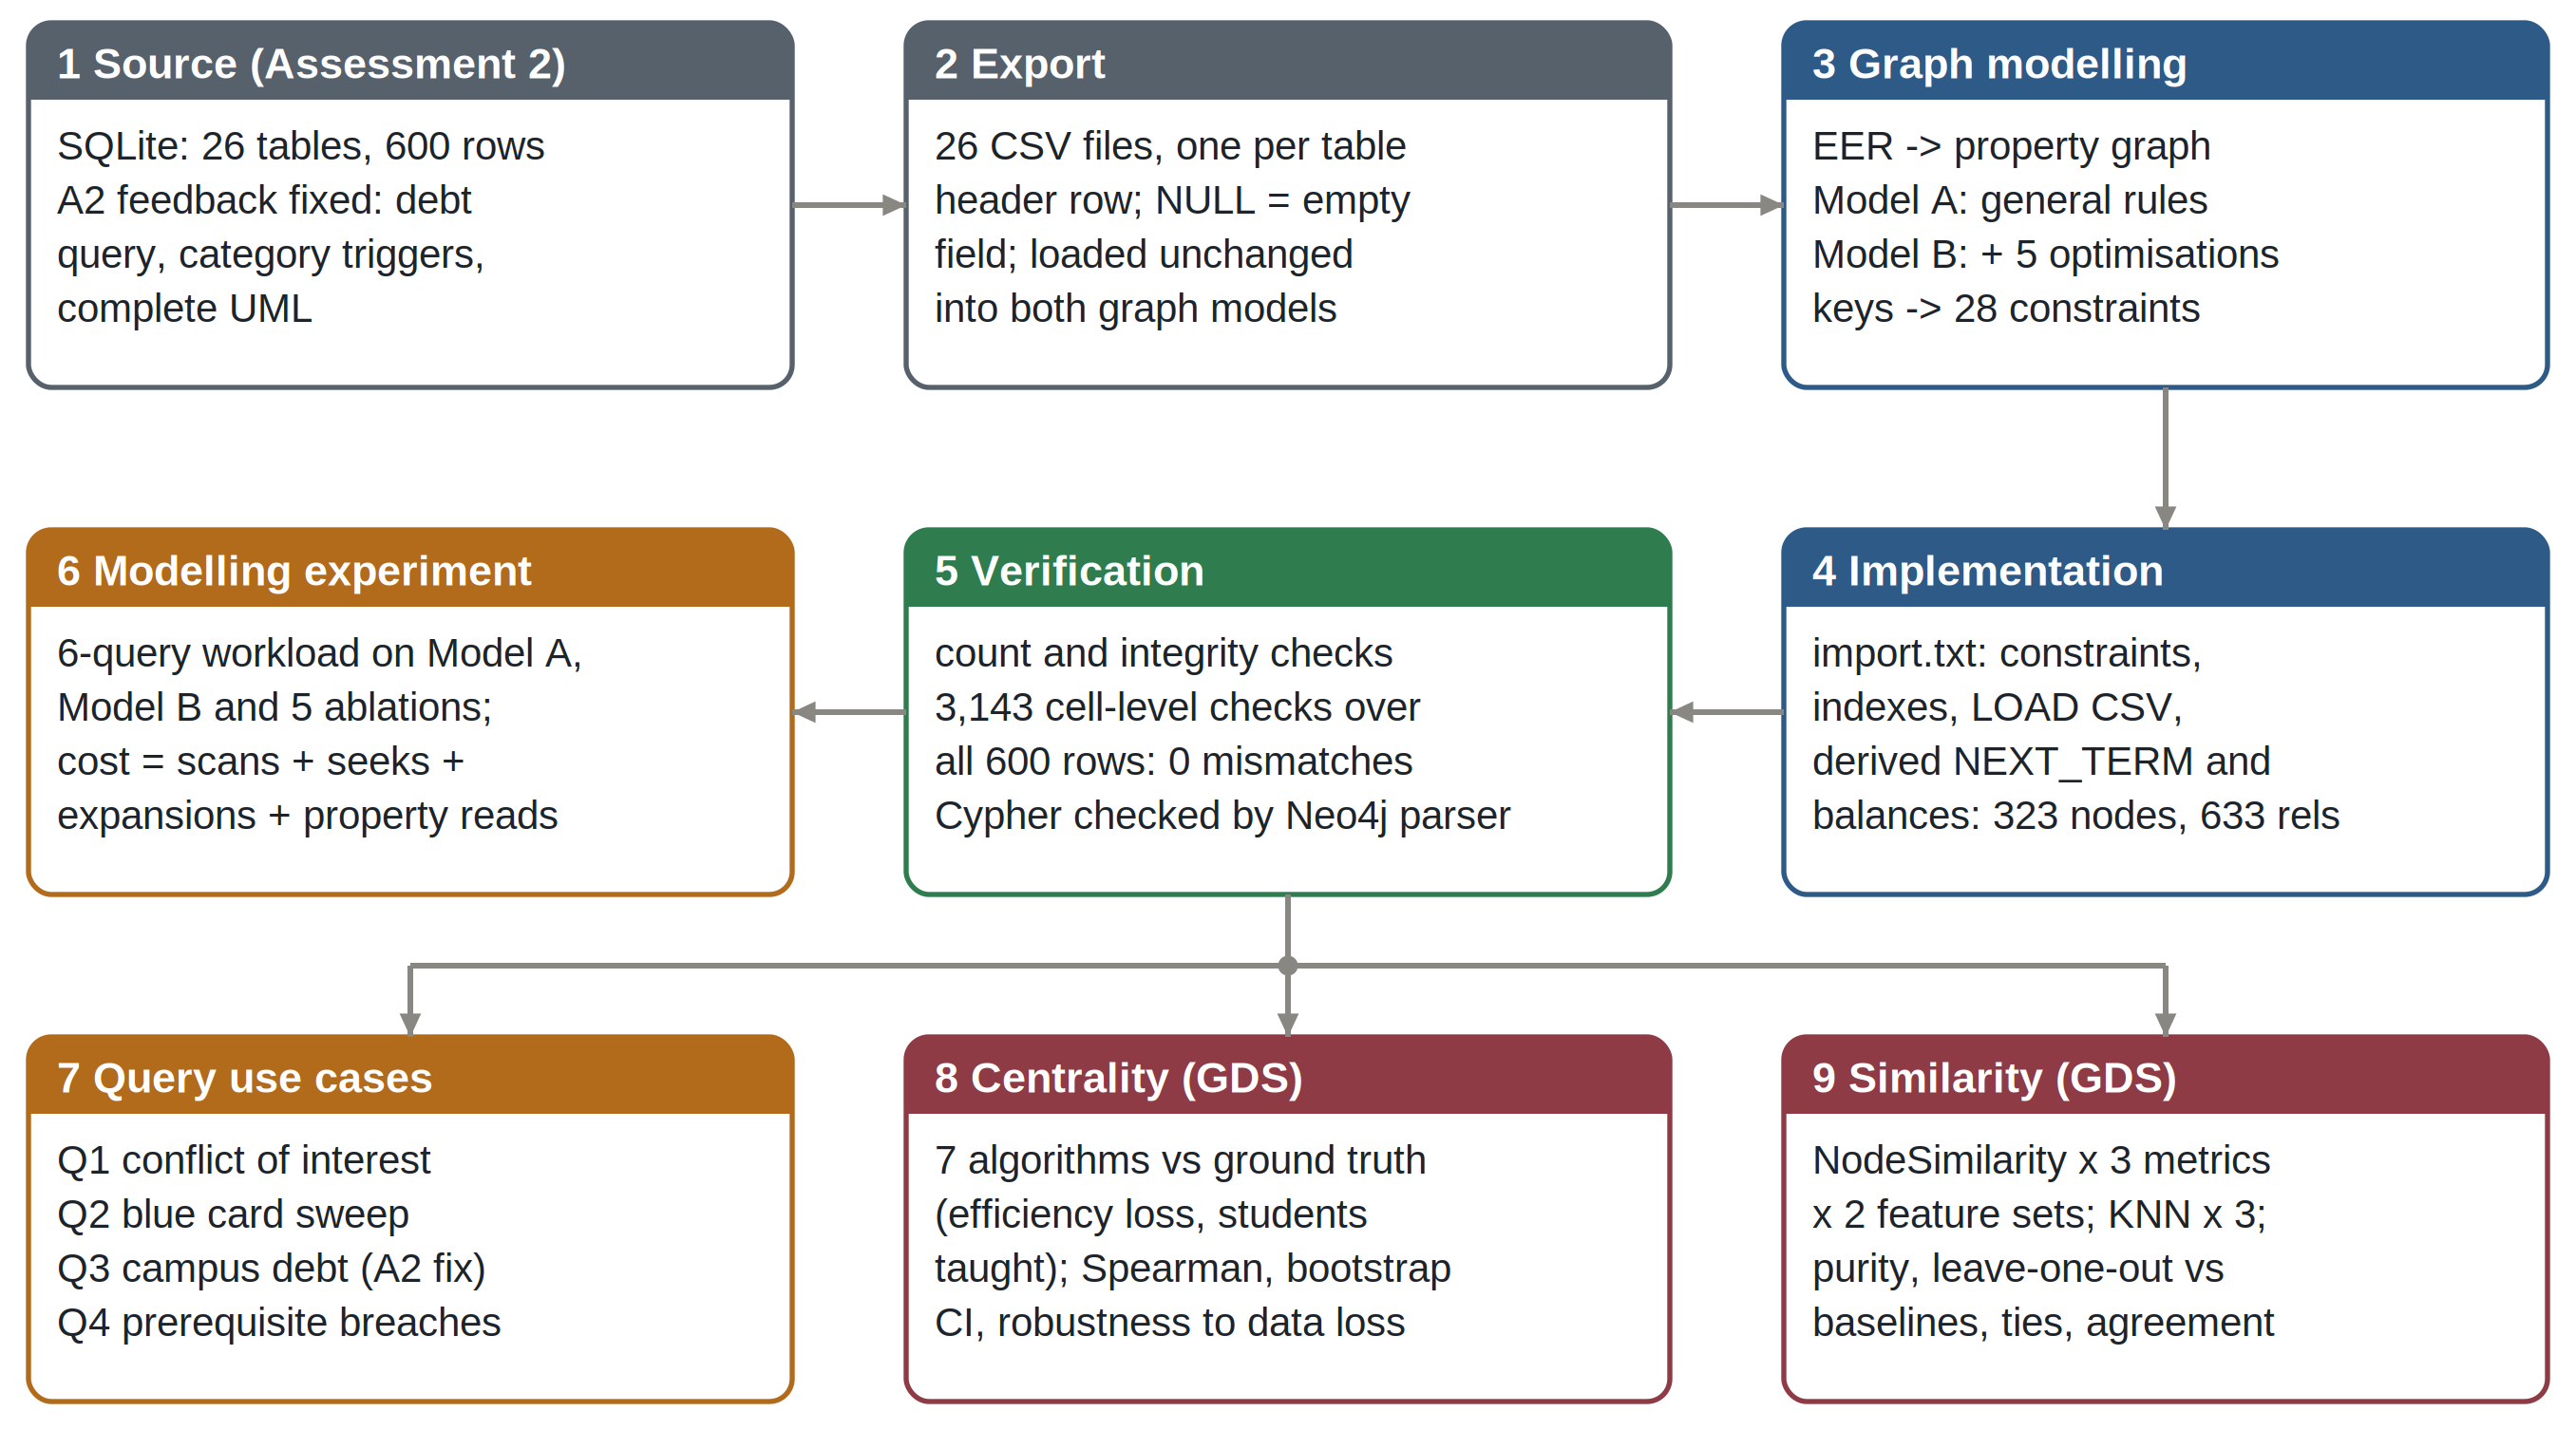

figure2_graph_model


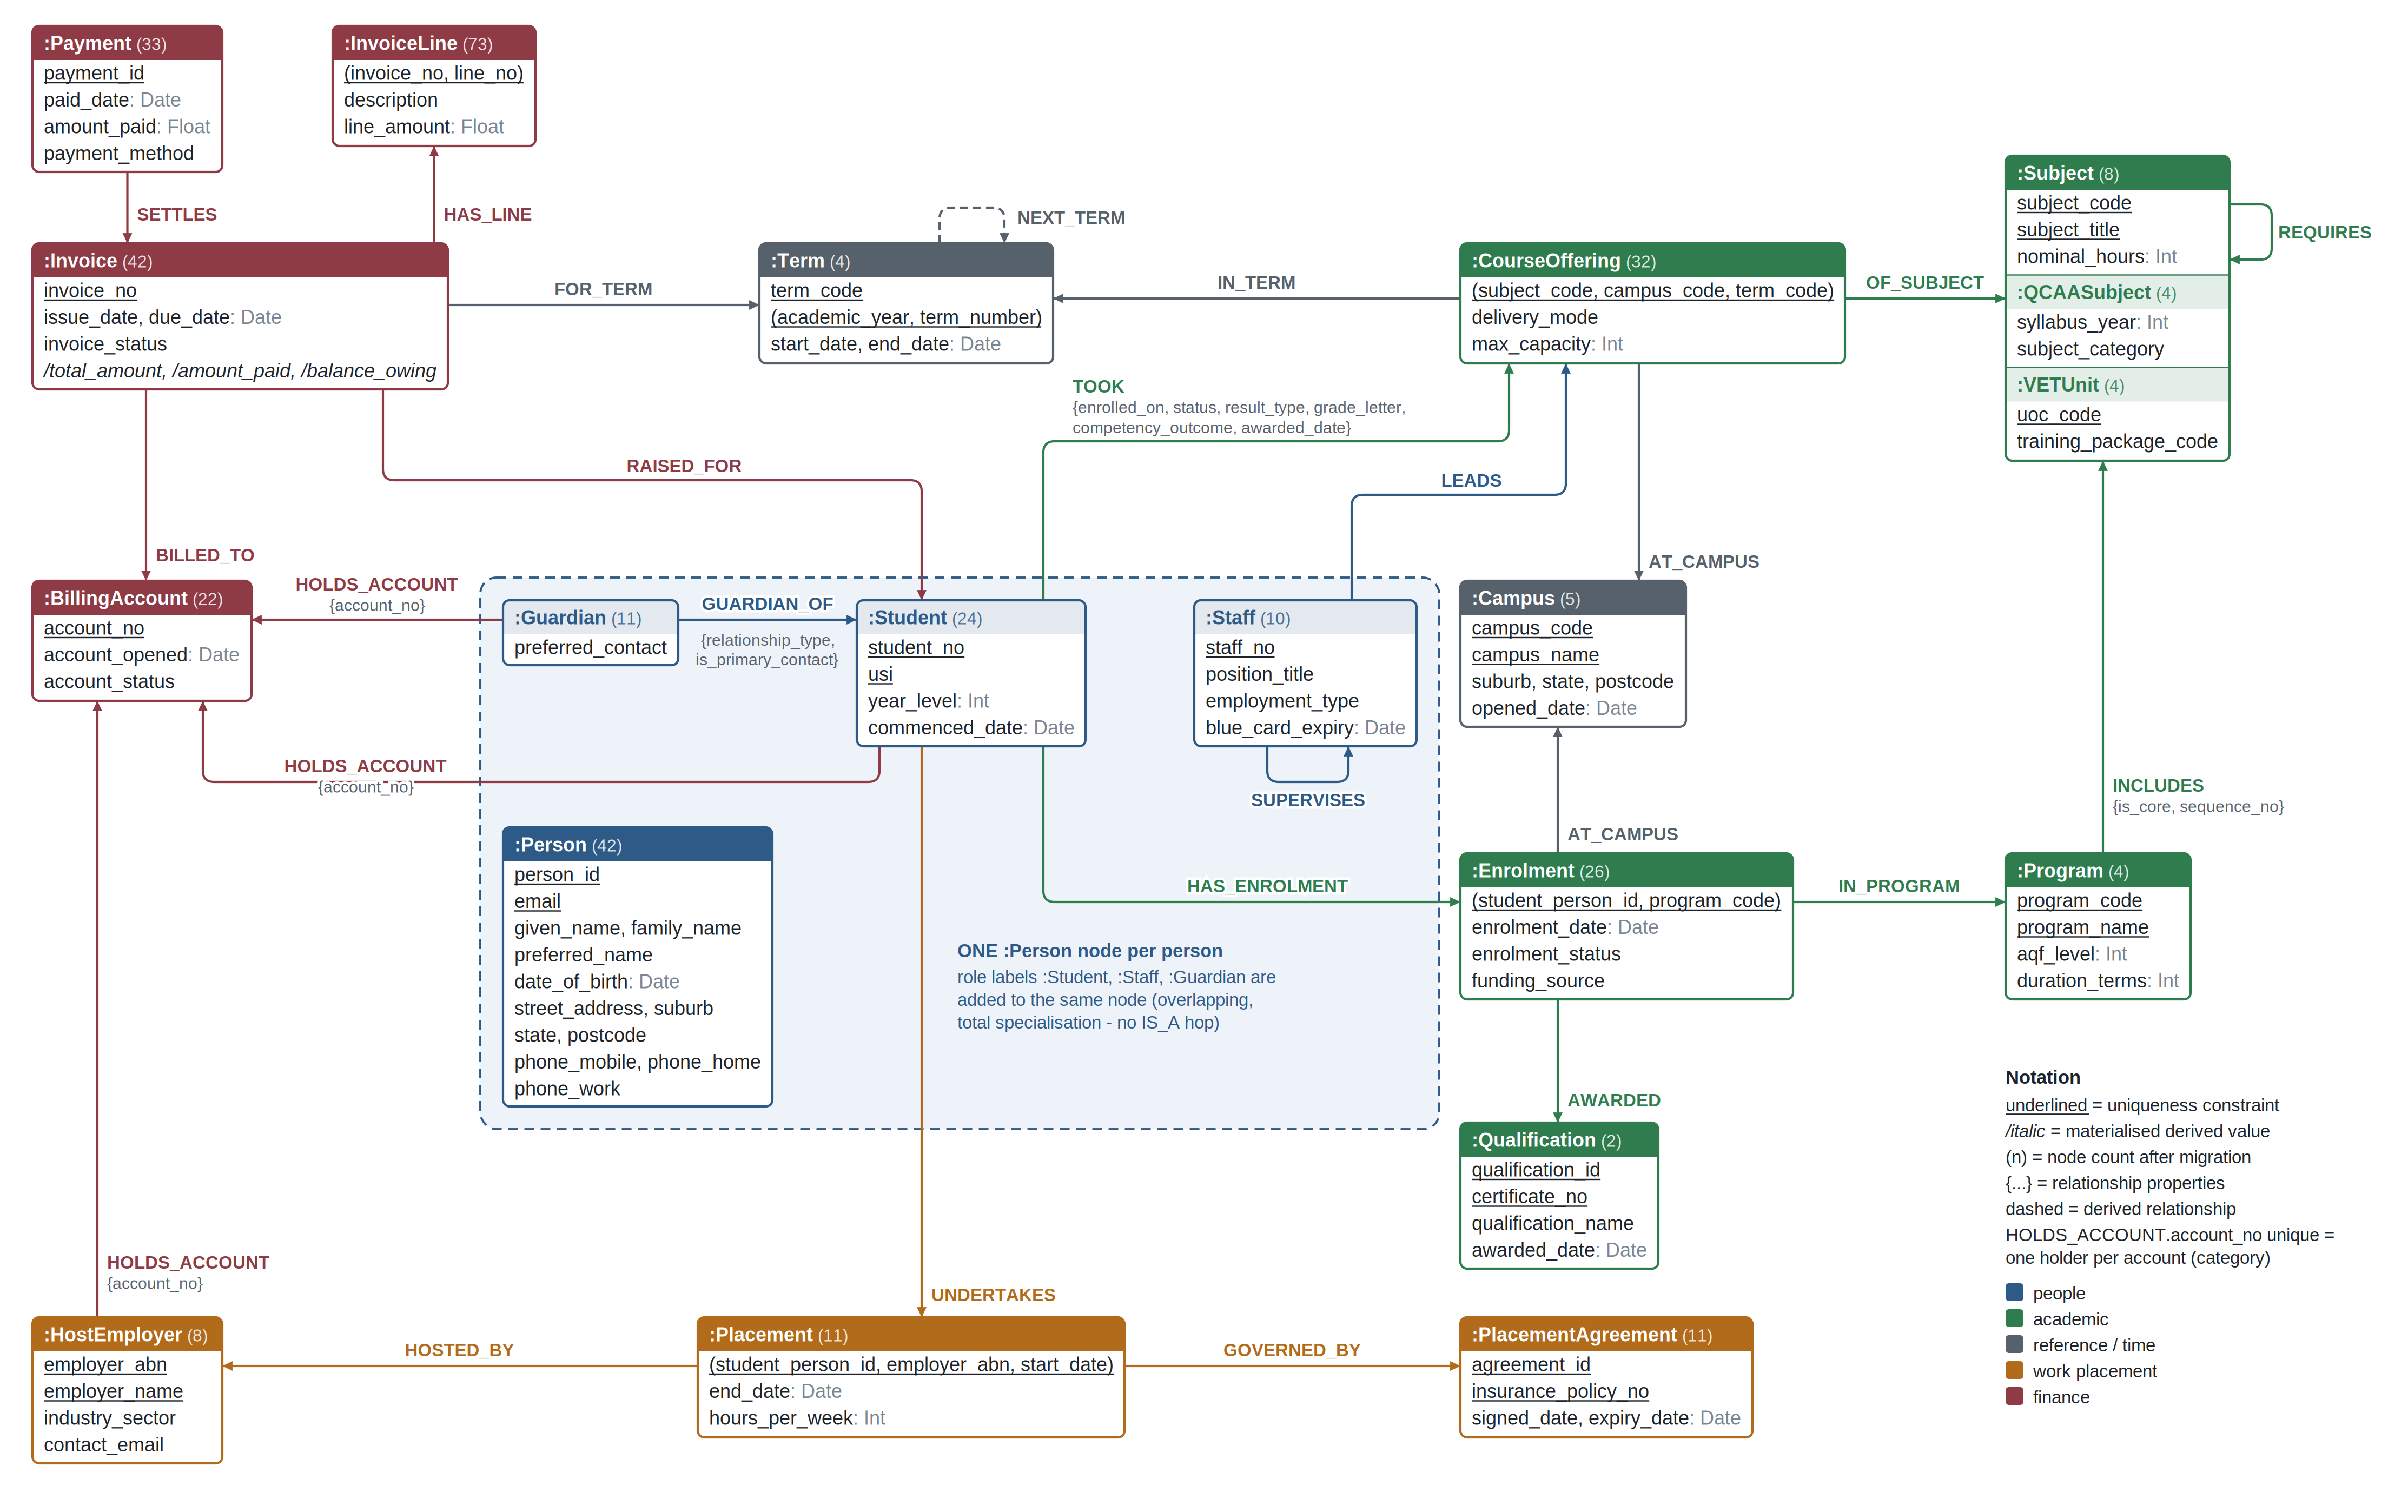

figure3_optimisations


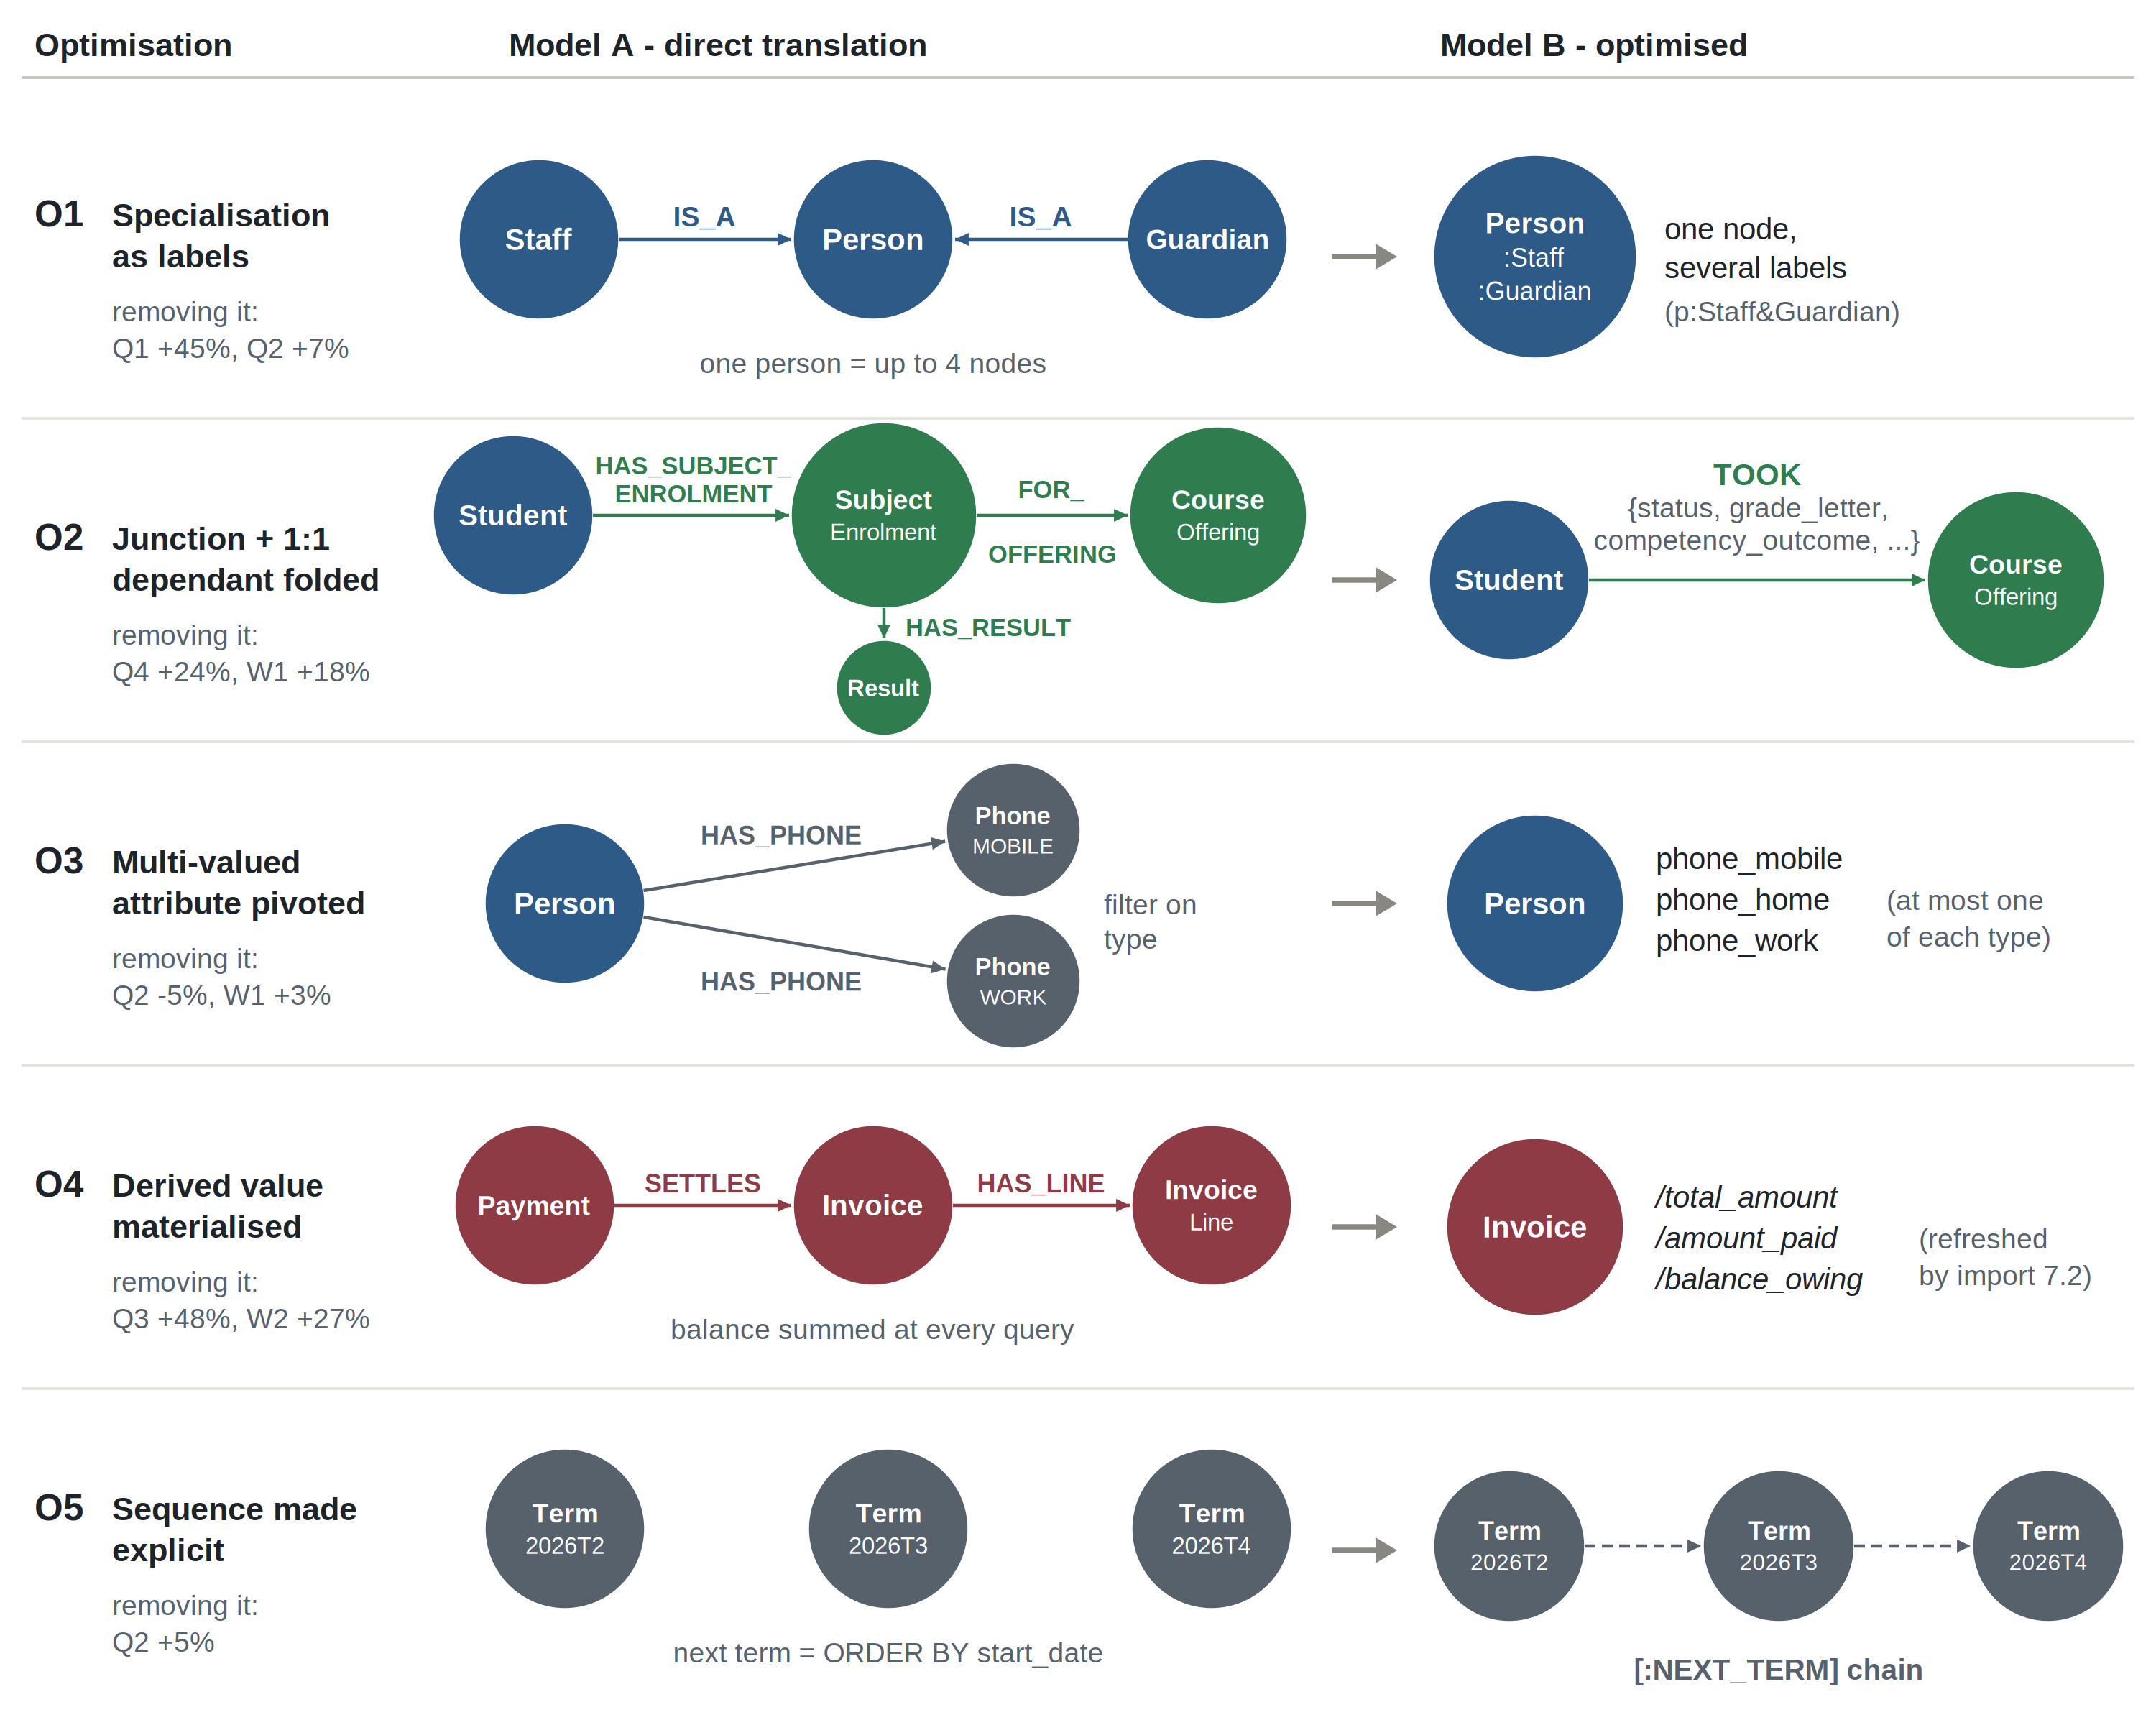

figure5_experiment


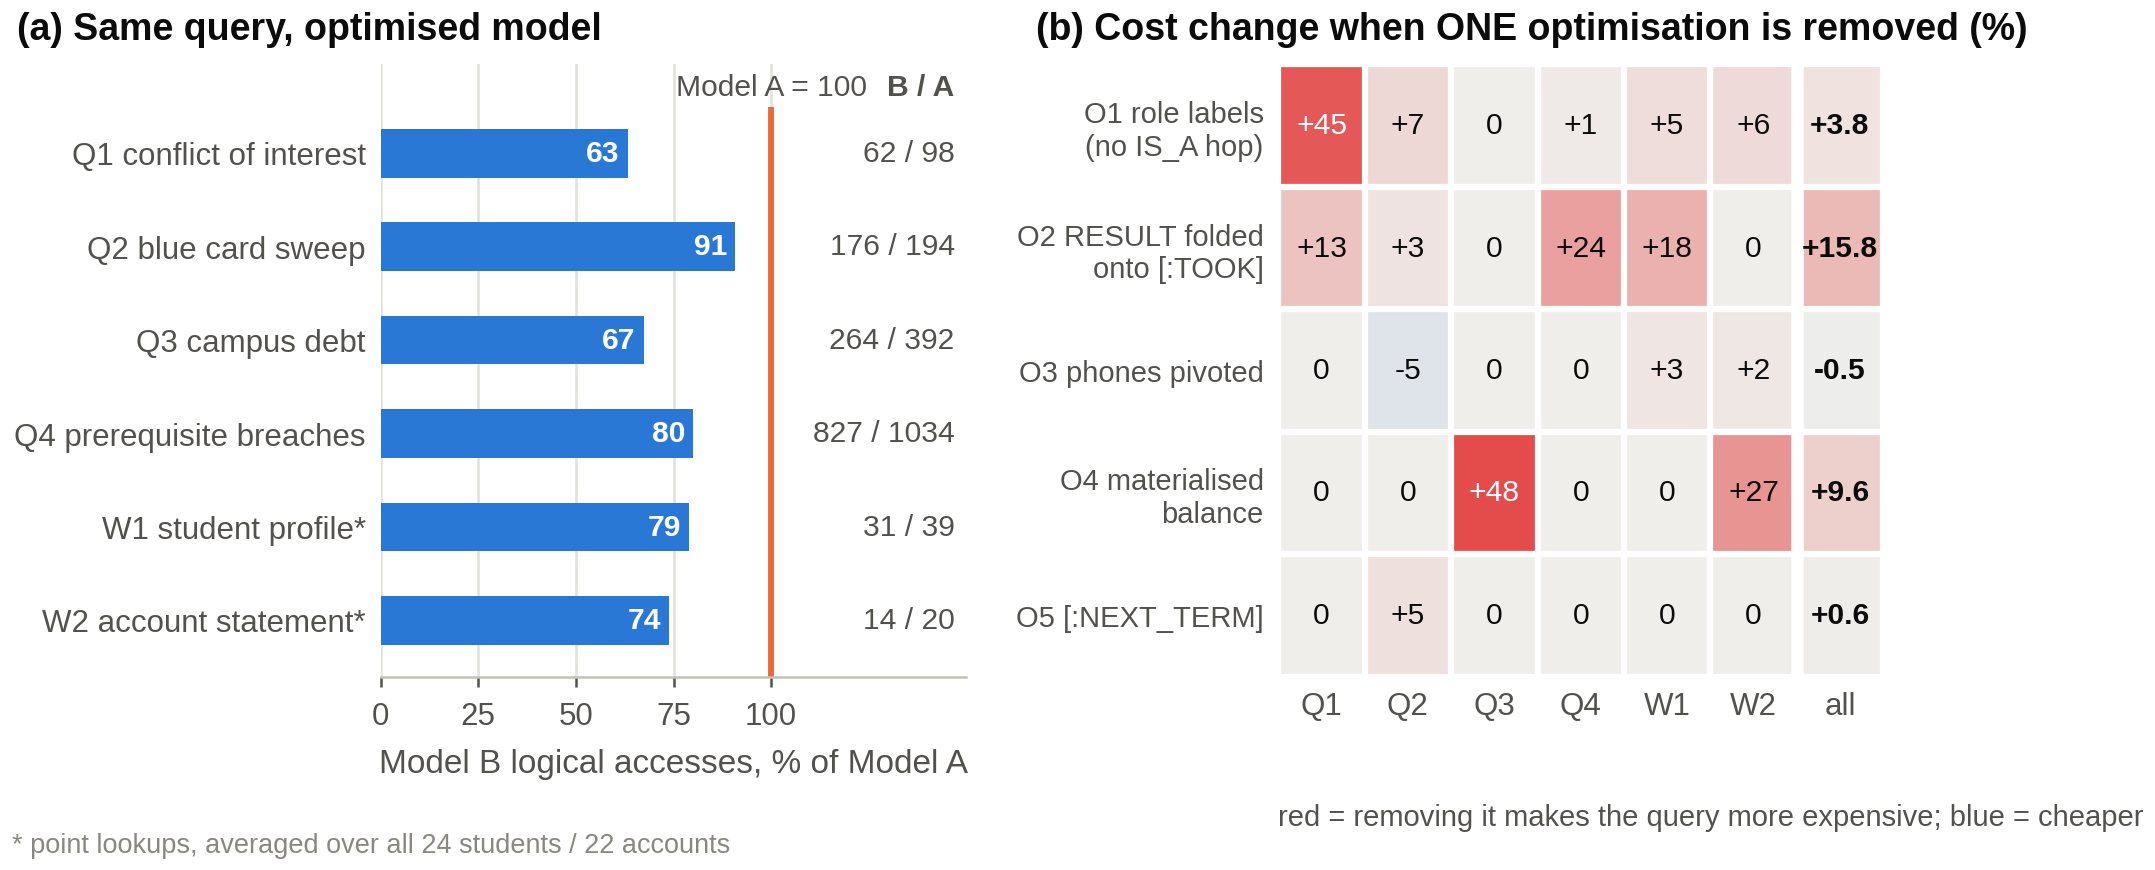

figure6_q1_conflict


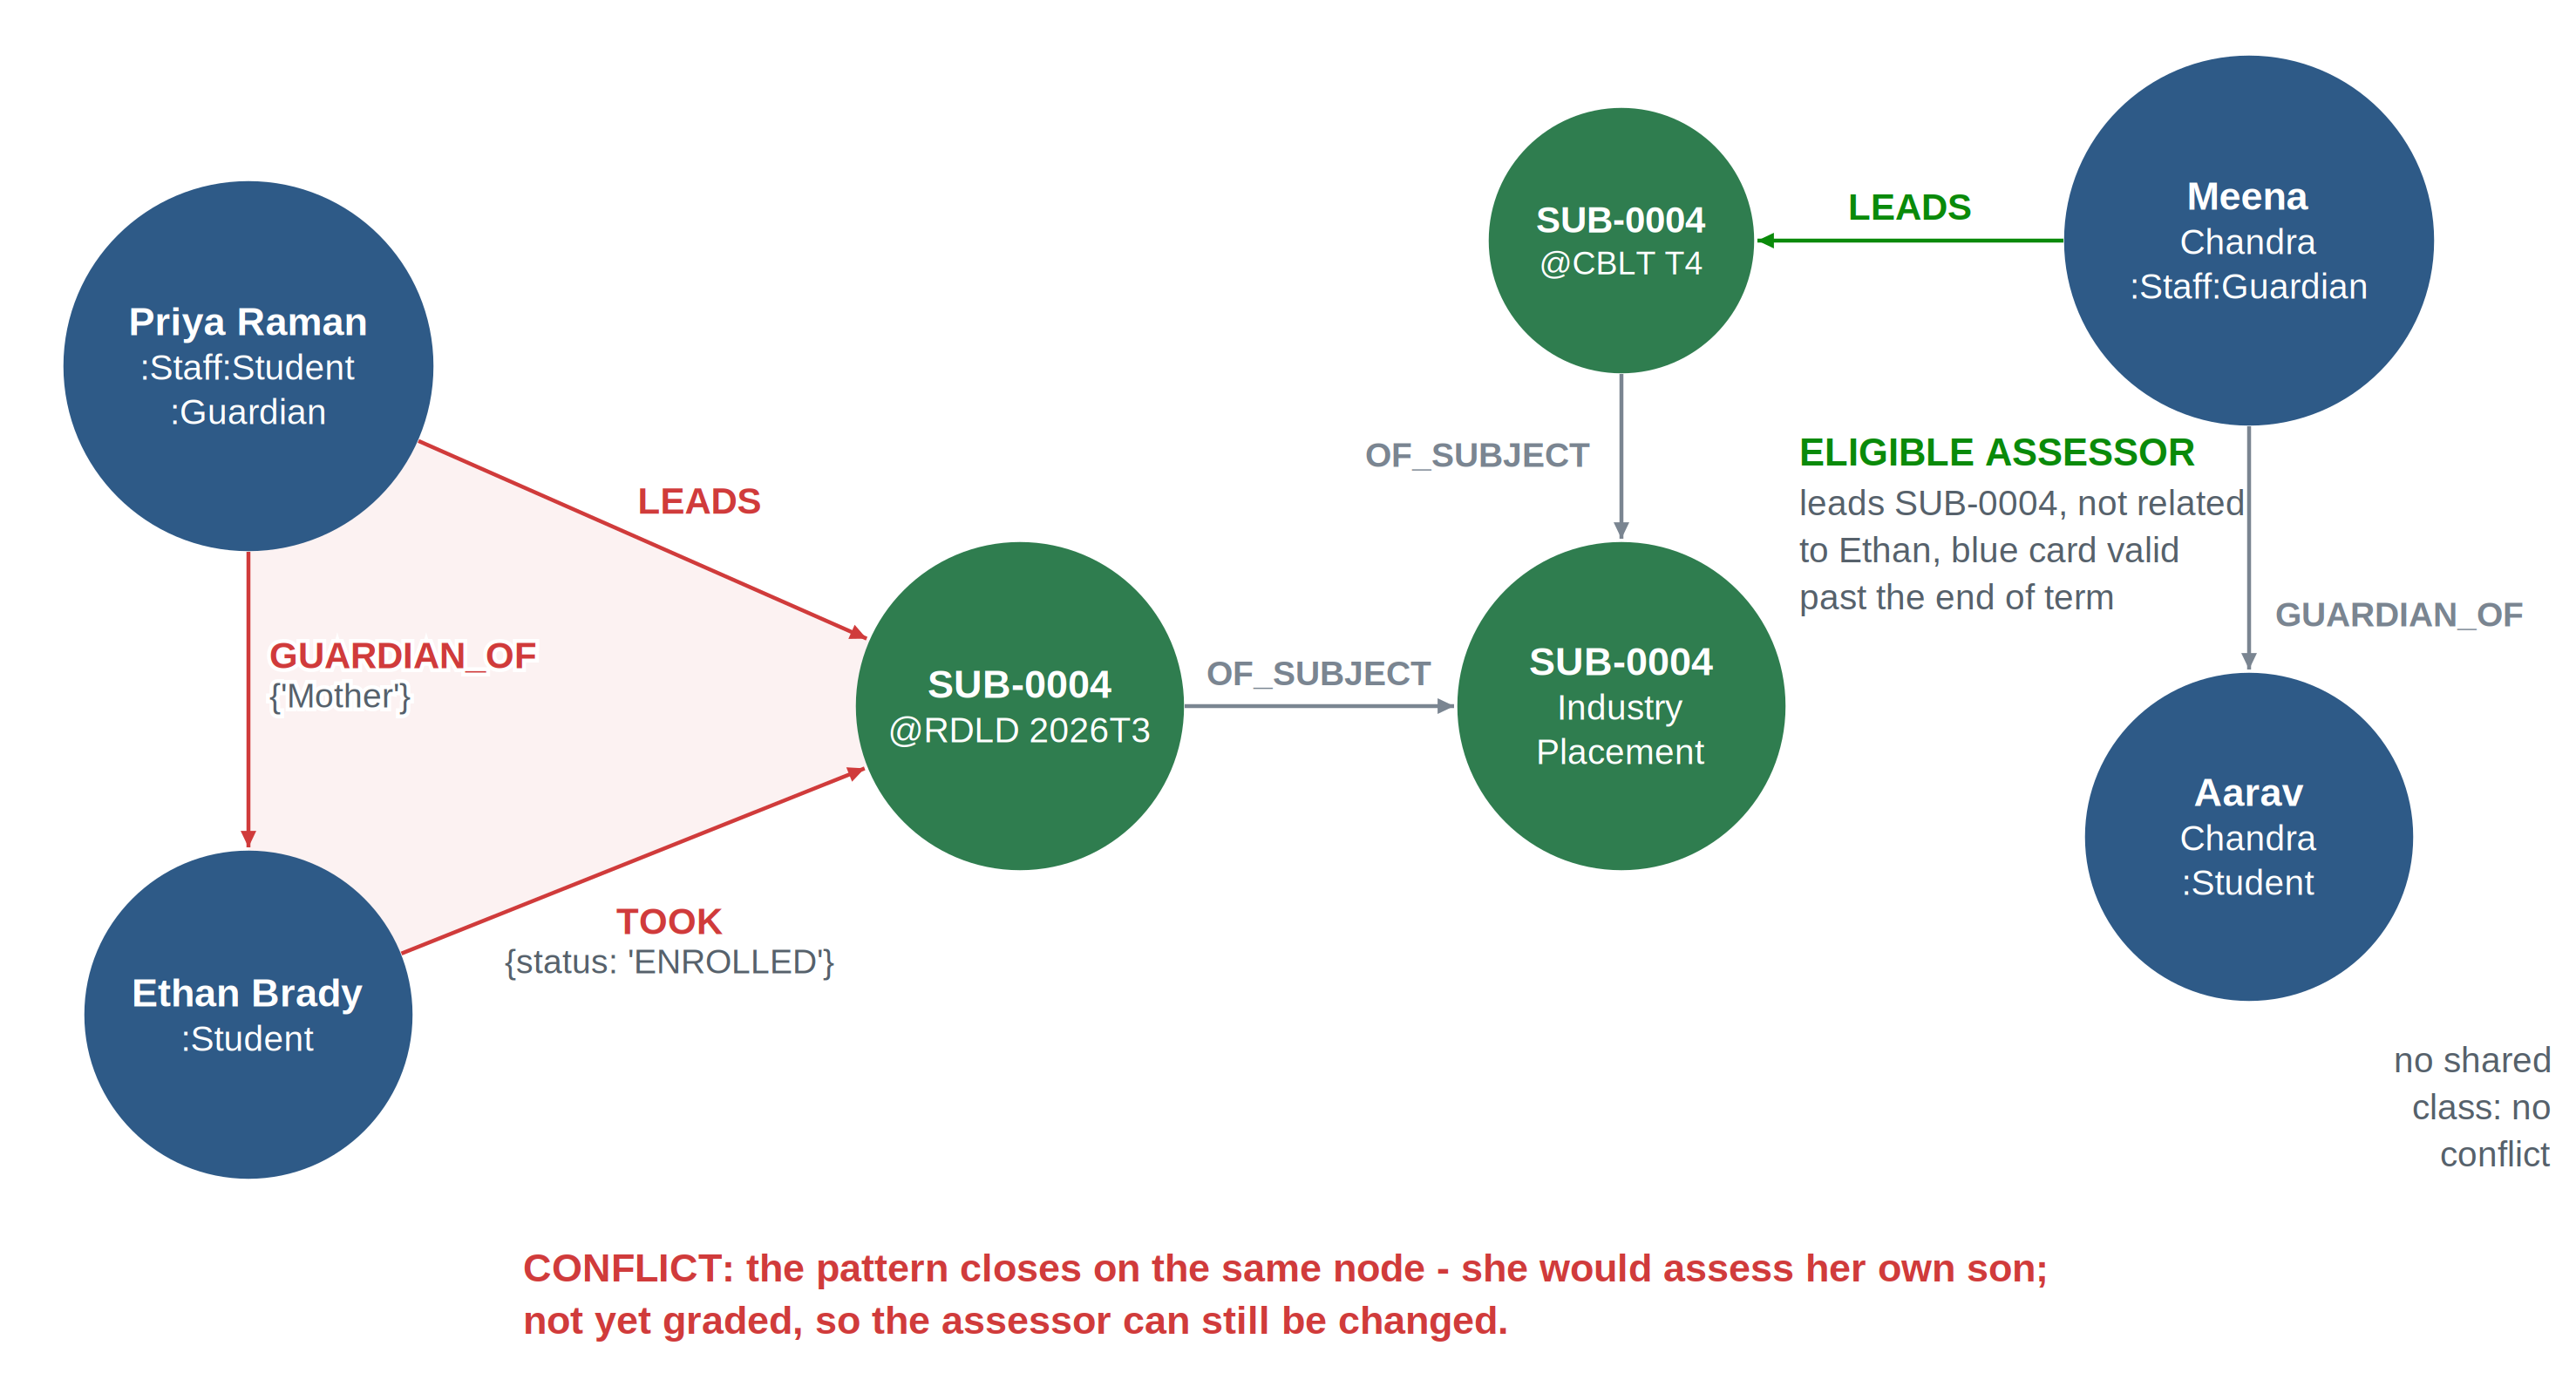

figure7_centrality


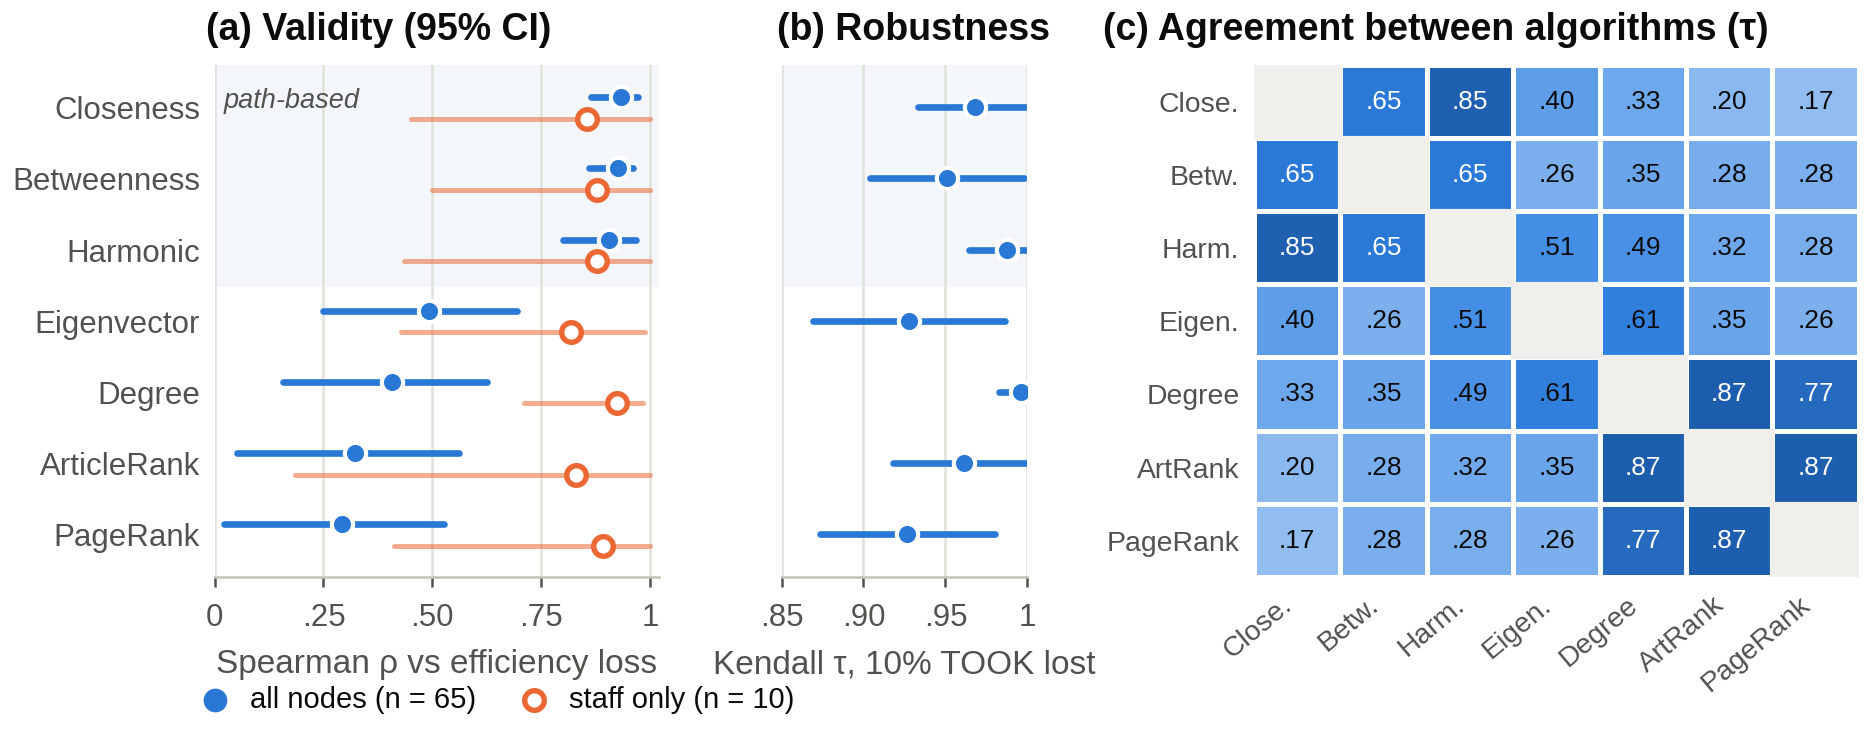

figure8_network


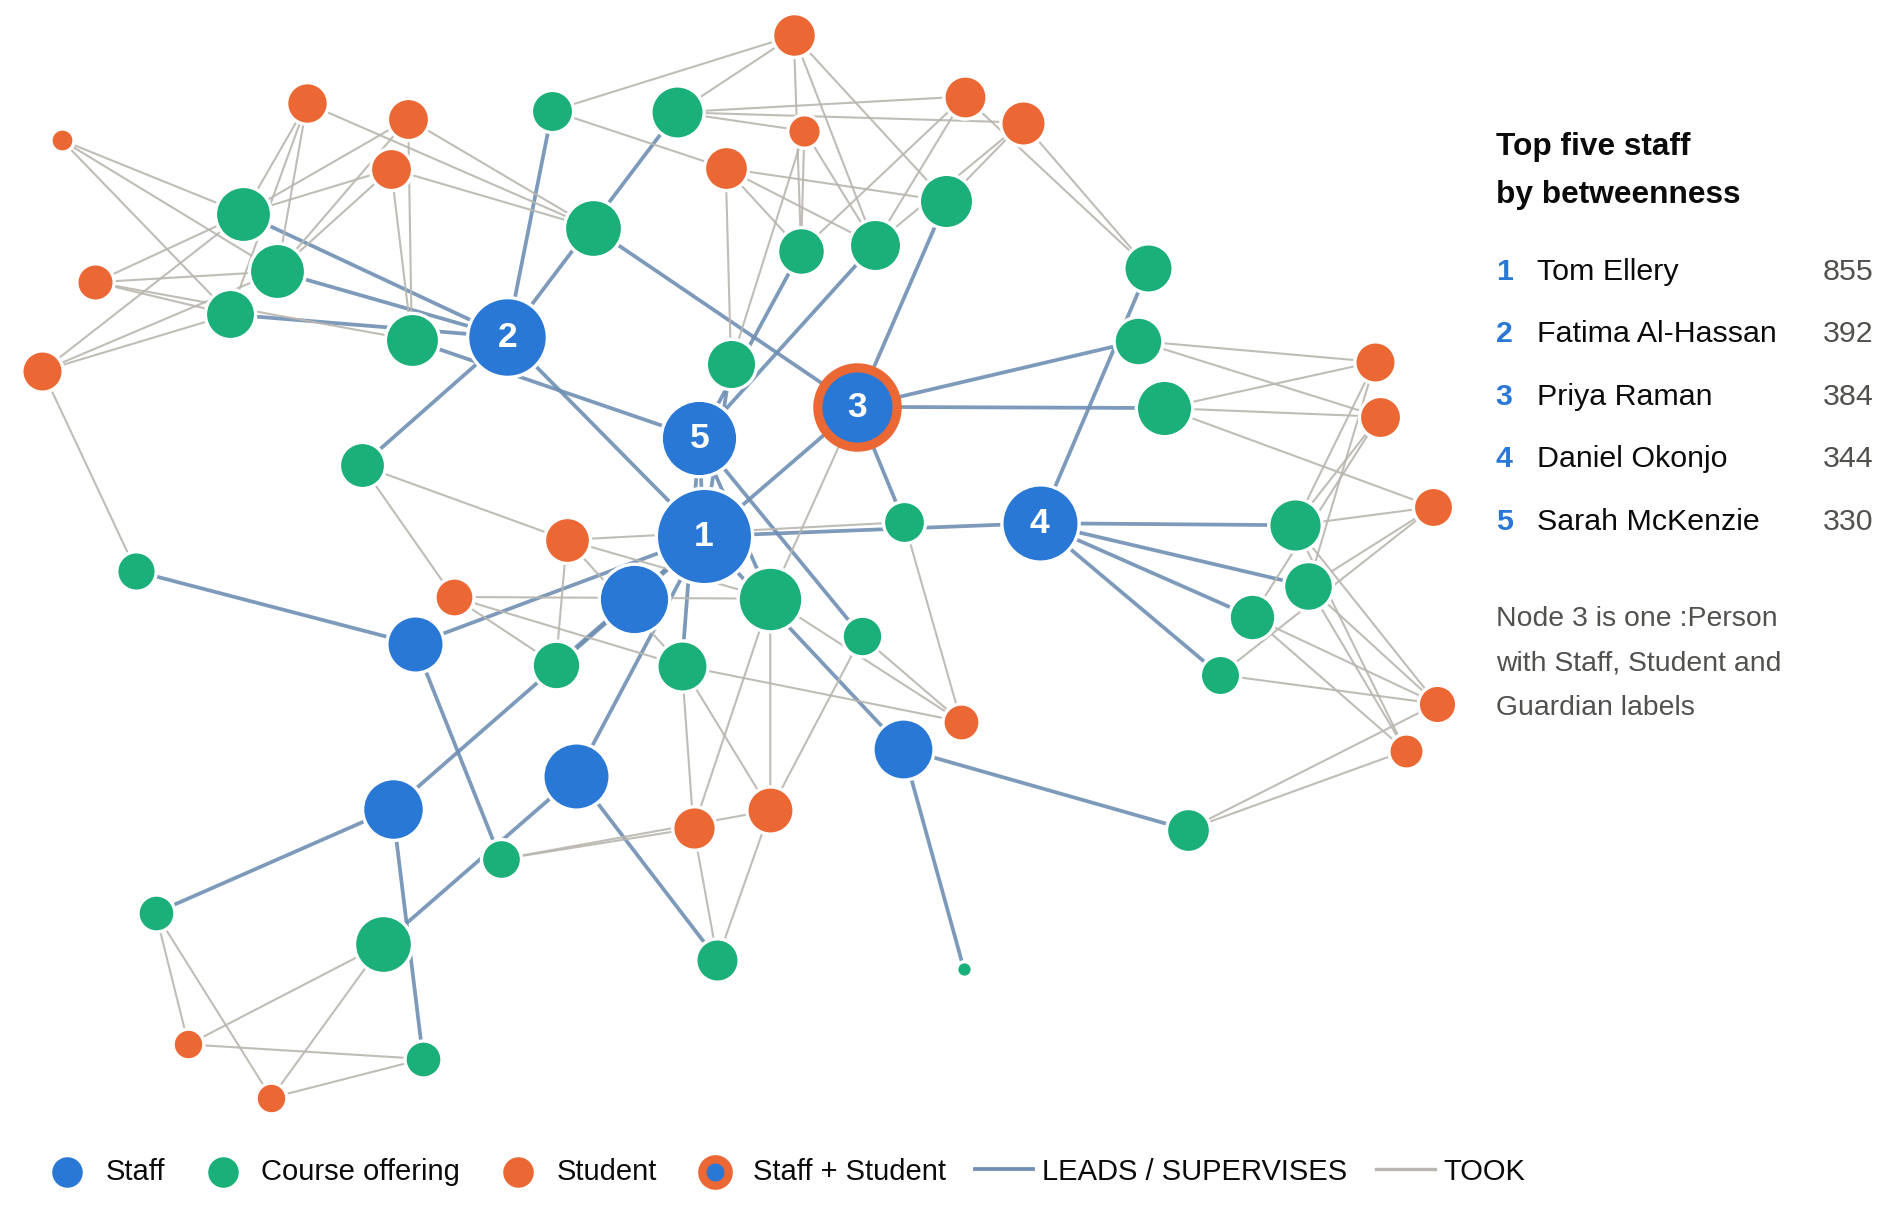

figure9_similarity


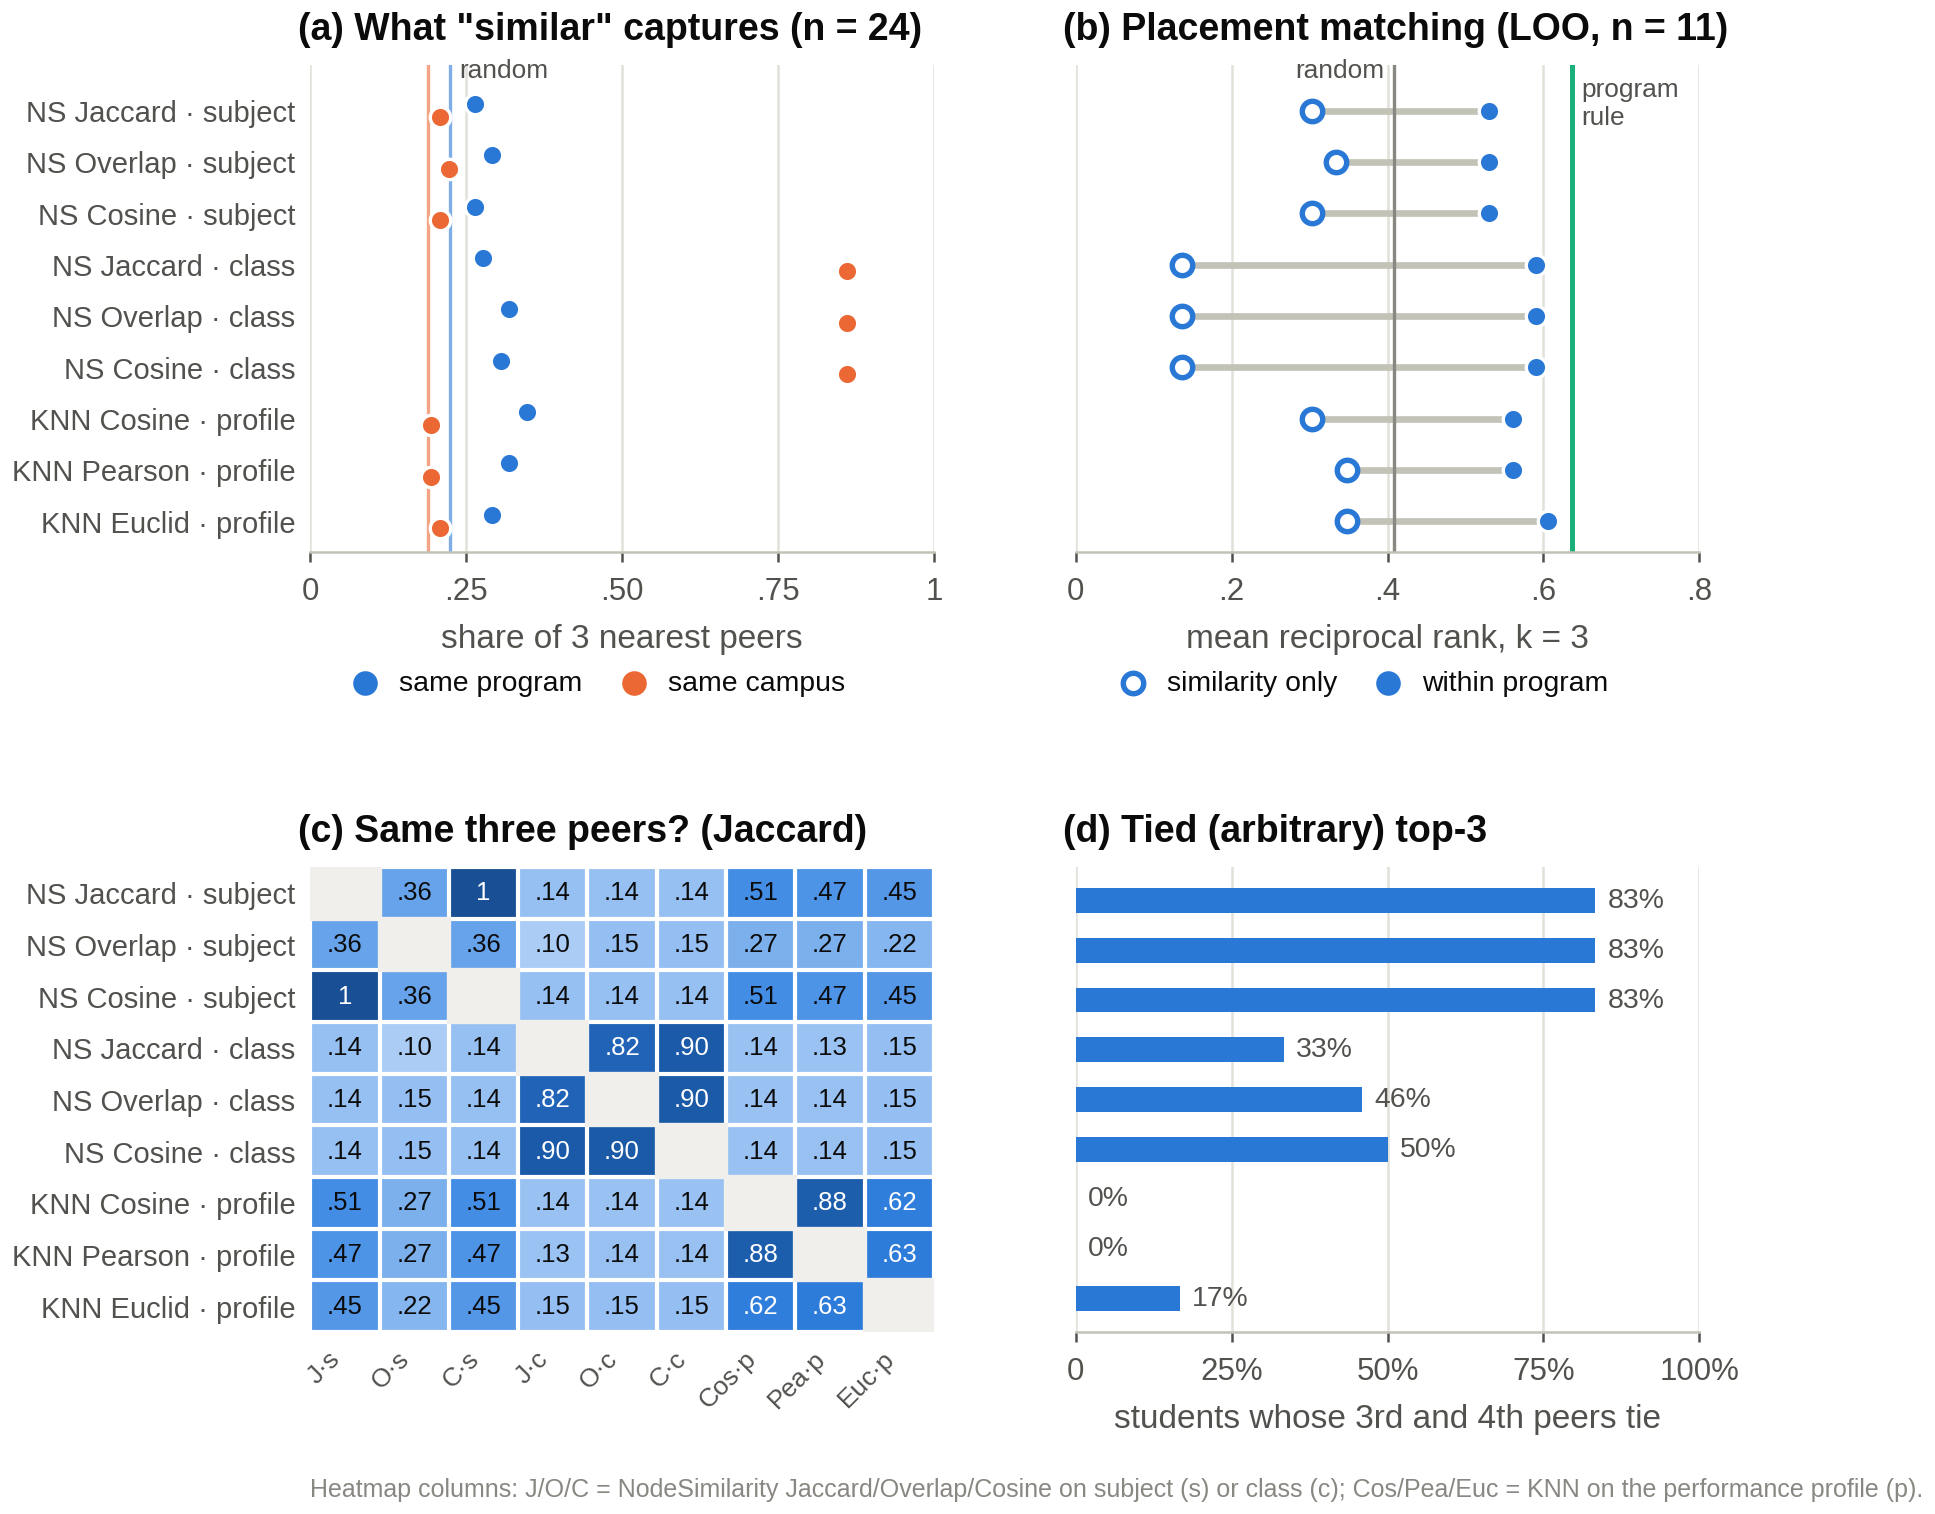

A2_revised_UML


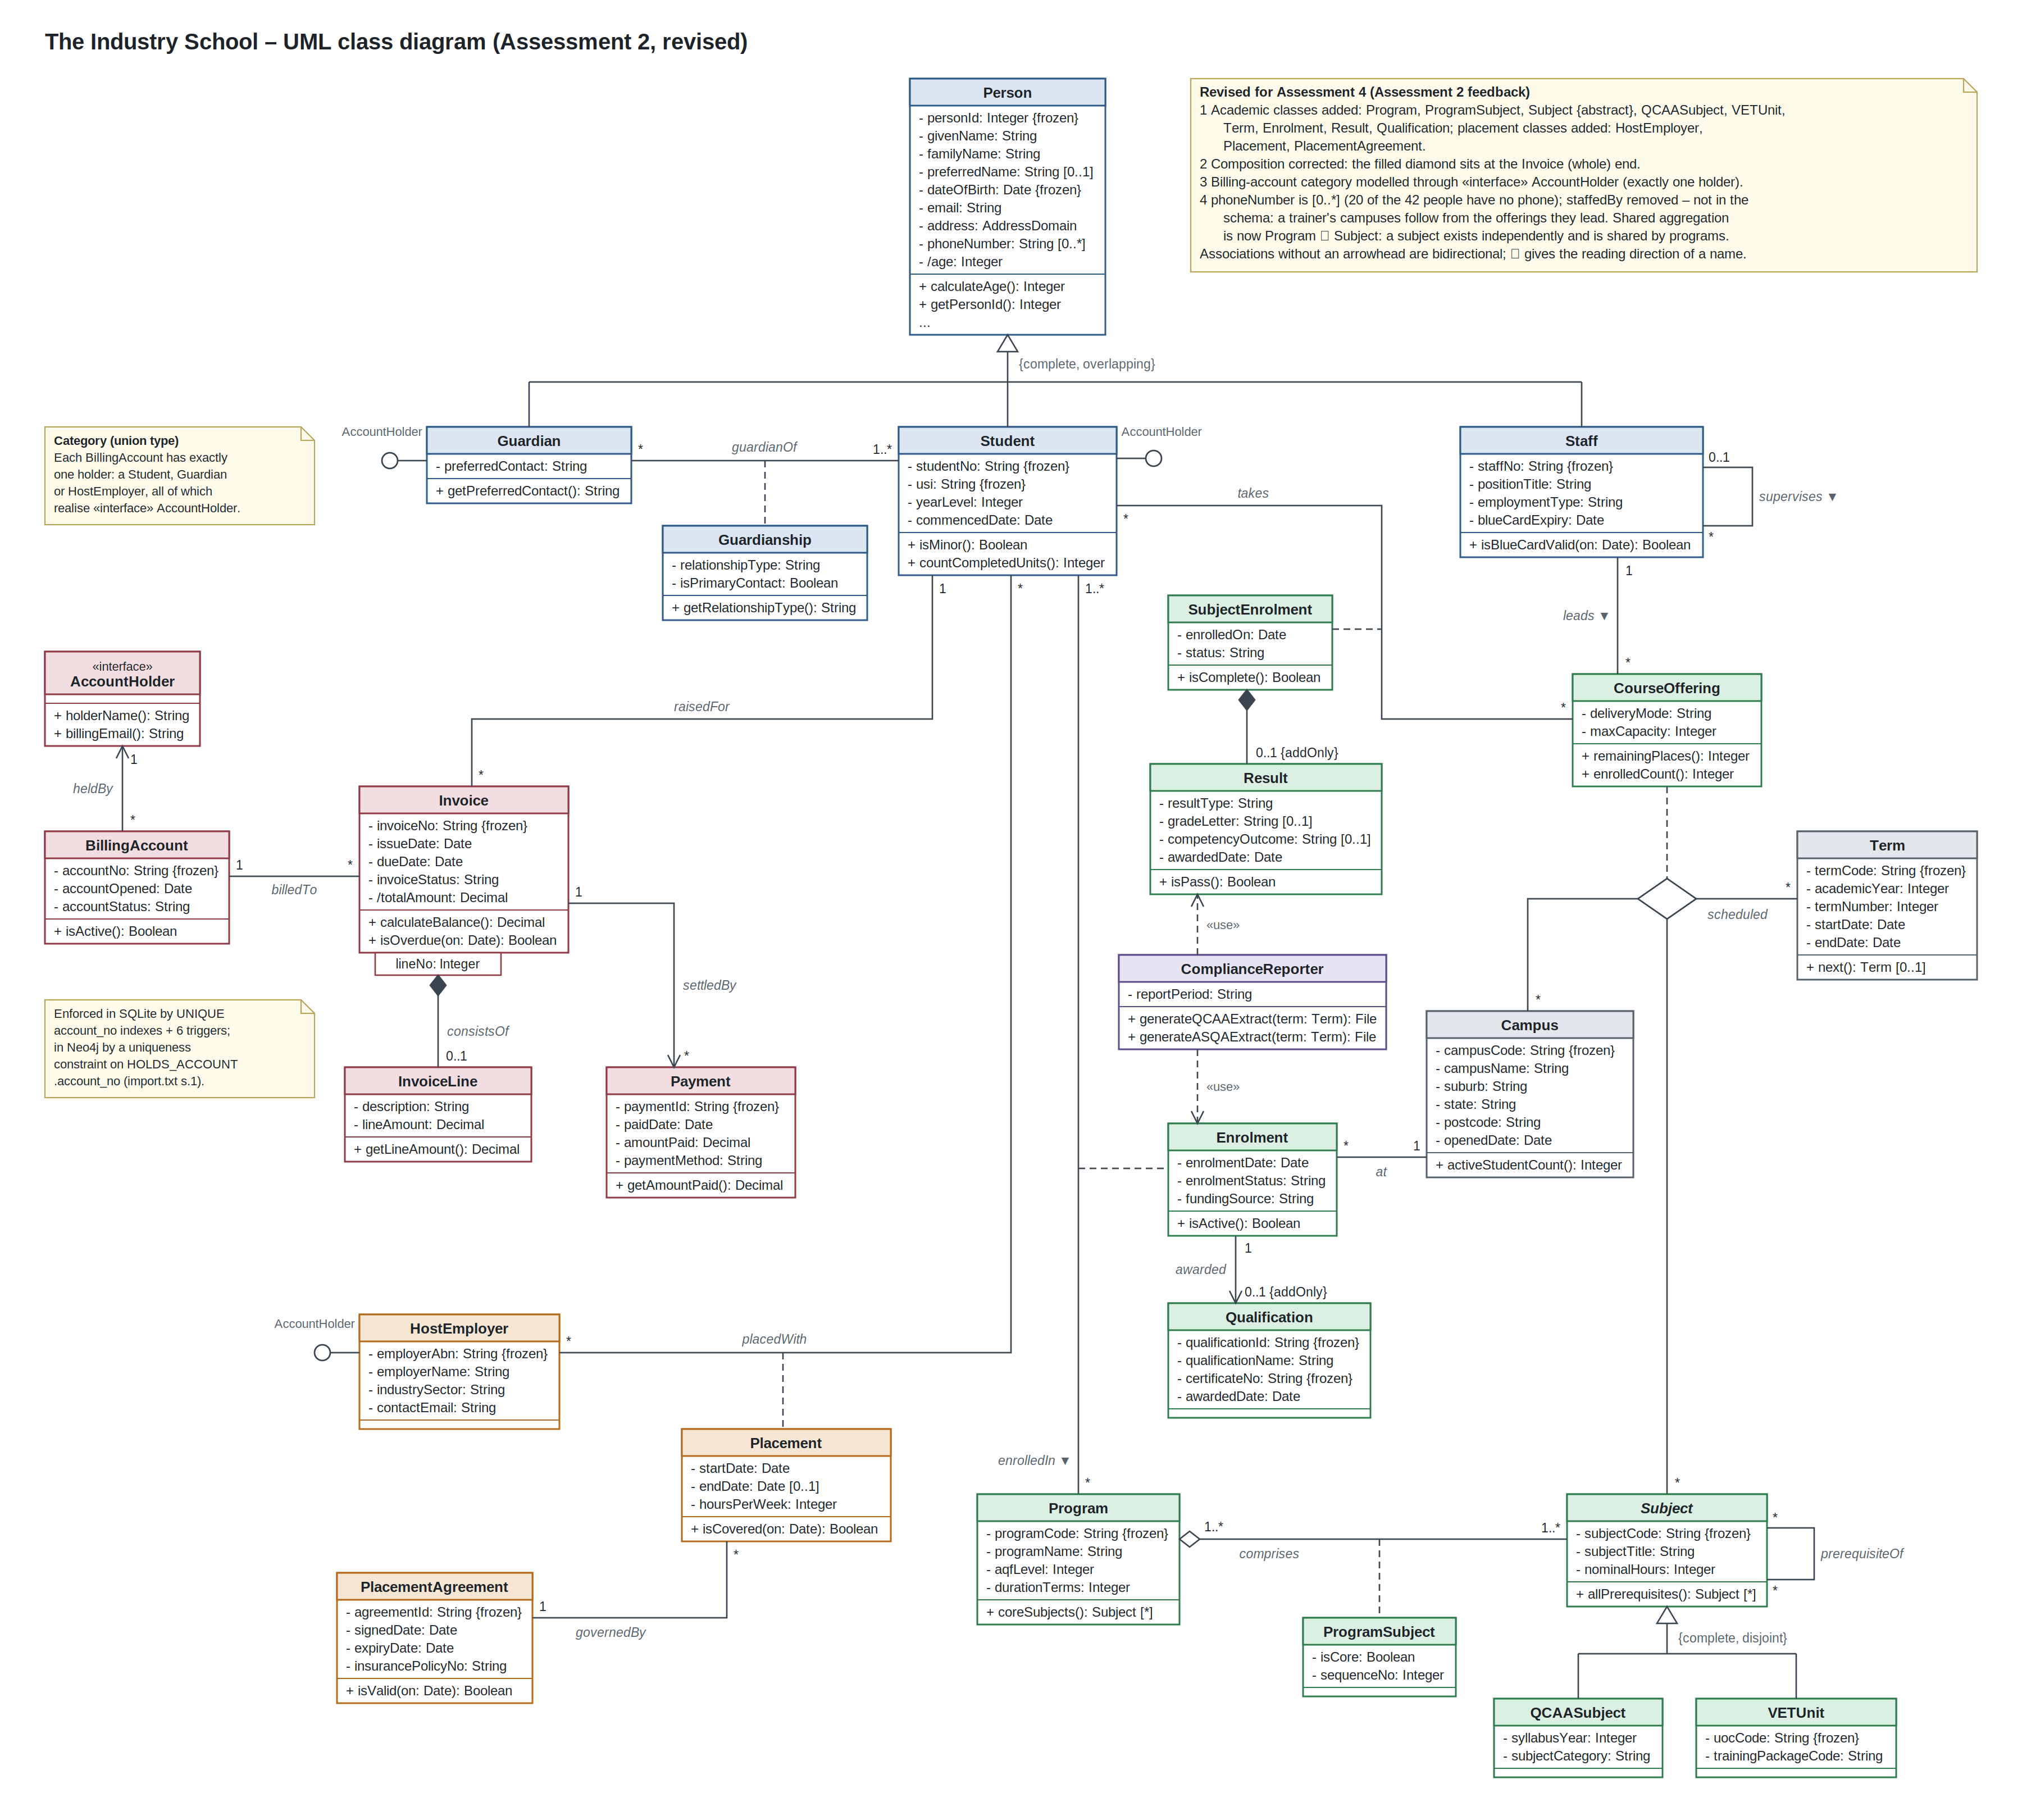

18 files in figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
import glob, os, re, shutil
from IPython.display import Image, SVG, display

def order(f):
    m = re.search(r'figure(\d+)', f)
    return int(m.group(1)) if m else 99

for svg in sorted(glob.glob('figures/*.svg'), key=order):
    png = svg[:-4] + '.png'
    print(os.path.basename(svg)[:-4])
    display(Image(png, width=900) if os.path.exists(png) else SVG(filename=svg))

shutil.make_archive('figures', 'zip', 'figures')
print(len(os.listdir('figures')), 'files in figures.zip')
try:
    from google.colab import files
    files.download('figures.zip')
except ImportError:
    print('figures.zip saved in', os.getcwd())